# Analysis of the abstract-only corpus, part 1/2

This Notebook includes a part of the exploratory analysis done on the cleaned data, filtered to contain only the abstracts from years 2016-2026. The thesis only reports the main findings; many things found out here could not fit into the final reported results.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

In [2]:
CLEANED_ABSTRACTS = "/scratch/project_2020431/data/scores_2016-2026.csv.gz"

In [3]:
cat_cols = "id domain entity_lower pos tag dep ent_type ent_iob entity_type entity_type_updated".split()
dtypes = {col: "category" for col in cat_cols}

In [67]:
preview_cols = "id year domain masked_sentence_minimal entity chunk_text score dep pos ent_type".split()

In [5]:
df = pd.read_csv(CLEANED_ABSTRACTS, dtype=dtypes)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276497 entries, 0 to 3276496
Data columns (total 27 columns):
 #   Column                   Dtype   
---  ------                   -----   
 0   id                       category
 1   year                     int64   
 2   domain                   category
 3   sent_id                  int64   
 4   match_id                 int64   
 5   sentence                 object  
 6   masked_sentence_minimal  object  
 7   masked_sentence_chunk    object  
 8   entity                   object  
 9   entity_lower             category
 10  in_noun_chunk            bool    
 11  chunk_text               object  
 12  chunk_root_text          object  
 13  chunk_root_dep           object  
 14  score                    float64 
 15  token_i                  int64   
 16  token_text               object  
 17  pos                      category
 18  tag                      category
 19  dep                      category
 20  ent_type                

In [6]:
domain_order = ["Physical Sciences", "Life Sciences", "Social Sciences", "Health Sciences"]

In [ ]:
# Binarized version of the score
df["humanlike"] = df["score"] > 0

In [179]:
df["entity_type_new"] = df["entity_type_updated"]
df["entity_type_new"] = df["entity_type_new"].cat.add_categories("human_pron")

human_pronouns = {"we", "she", "he", "i", "us", "her", "him"}
pronoun_mask = df["entity_lower"].isin(human_pronouns)
df.loc[pronoun_mask, "entity_type_new"] = "human_pron"

In [180]:
df.entity_type_new.value_counts()

entity_type_new
artifact      2132033
lm             436596
human_pron     370695
human          297937
propn_llm       39236
Name: count, dtype: int64

In [8]:
#df["is_propn_llm"] = df["entity_lower"].isin(("chatgpt", "claude", "gemini"))
df["is_propn_llm"].value_counts()

is_propn_llm
False    3237261
True       39236
Name: count, dtype: int64

In [ ]:
"""
# Change the entity_type for proper noun LLMs
df["entity_type_updated"] = df["entity_type"]
df["entity_type_updated"] = df["entity_type_updated"].cat.add_categories(["propn_llm"])
df.loc[df["is_propn_llm"] == True, "entity_type_updated"] = "propn_llm"
df["entity_type_updated"] = df["entity_type_updated"].cat.remove_unused_categories()
"""

In [5]:
df.entity_type_updated.value_counts()

entity_type_updated
artifact     2132033
human         668632
lm            436596
propn_llm      39236
Name: count, dtype: int64

In [8]:
multi_token_mask = df["entity_lower"].str.contains(" ")
multi_token_ents = df.loc[multi_token_mask]["entity_lower"].unique()

In [9]:
multi_token_ents

['language model', 'artificial intelligence', 'language models', 'pre-trained language model', 'pre-trained language models', 'large language models', 'large language model', 'foundation models', 'foundation model']
Categories (64, object): ['agent', 'agents', 'ai', 'algorithm', ..., 'chatgpt', 'claude', 'gemini', 'llama']

In [ ]:
# For calculating averages, drop duplicated multi-token columns,
# keeping only the last row (e.g. keep "model" from "large language model")
detect_dupl_cols = "id entity_lower sent_id match_id score".split()
df_dedupl = df.drop_duplicates(detect_dupl_cols, keep="last").copy()

In [11]:
len(df_dedupl)/len(df)

0.9037917629712464

In [182]:
df_dedupl.entity_type_updated.value_counts()

entity_type_updated
artifact     1958102
human         668632
lm            295301
propn_llm      39236
Name: count, dtype: int64

In [186]:
df_dedupl.groupby("entity_type_updated", observed=True)["score"].mean().sort_values()

entity_type_updated
artifact    -0.042712
lm          -0.021052
propn_llm    0.000410
human        0.070004
Name: score, dtype: float64

In [183]:
df_dedupl.entity_type_new.value_counts()

entity_type_new
artifact      1958102
human_pron     370695
human          297937
lm             295301
propn_llm       39236
Name: count, dtype: int64

In [185]:
df_dedupl.groupby("entity_type_new", observed=True)["score"].mean().sort_values()

entity_type_new
artifact     -0.042712
lm           -0.021052
propn_llm     0.000410
human_pron    0.066241
human         0.074685
Name: score, dtype: float64

In [ ]:
# Map the plural entities to their singular counterparts in order to
# make some of the plots more brief
skip_singular = set(("approaches", "us", "companies"))
def map_to_singular(term):
    if term.endswith("s") and term not in skip_singular:
        return term[:-1]
    return term

df_dedupl["entity_stripped"] = df_dedupl["entity_lower"].apply(map_to_singular)
df_dedupl["entity_stripped"] = df_dedupl["entity_stripped"].replace({"approaches": "approach"})

In [13]:
et_order = "artifact lm propn_llm human".split()

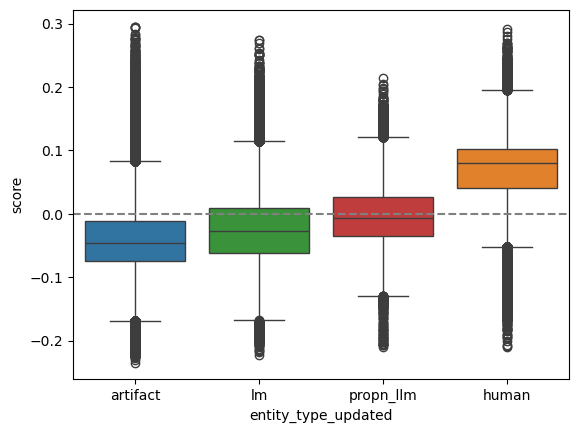

In [14]:
ax = sns.boxplot(df_dedupl, x="entity_type_updated", y="score", hue="entity_type_updated", order=et_order)
ax.axhline(0, color="gray", linestyle="--")
plt.show()

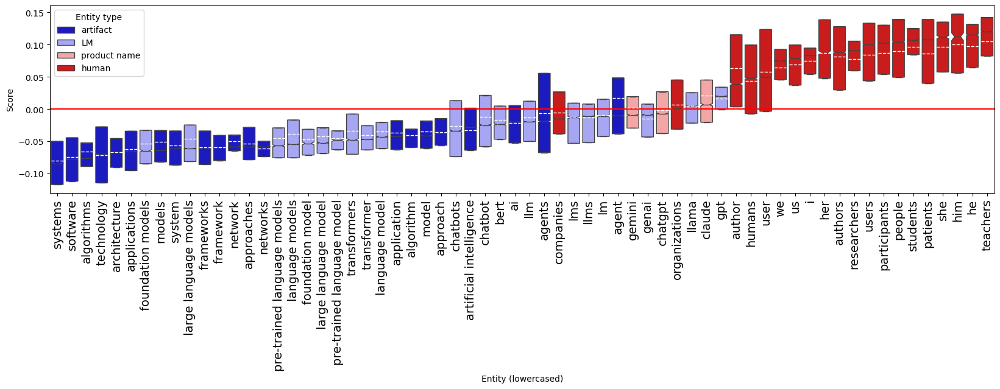

In [29]:
median_order = df_dedupl.groupby("entity_lower", observed=True)["score"].median().sort_values().index
fig, ax = plt.subplots(figsize=(20, 4))
sns.boxplot(df_dedupl, y="score", x="entity_lower",
            showmeans=True, meanline=True, meanprops={"color": "white"},
            whis=(25, 75), showfliers=False, notch=True,
            ax=ax, order=median_order, hue="entity_type_updated", hue_order=et_order,
            dodge=False, palette=et_palette)
ax.axhline(0, color="red")
plt.xticks(rotation=90, fontsize=14)
ax.set_xlabel("Entity (lowercased)")
ax.set_ylabel("Score")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [legend_map[l] for l in labels], title="Entity type")
plt.savefig("../figures/entity_scores.pdf", bbox_inches="tight")
plt.show()

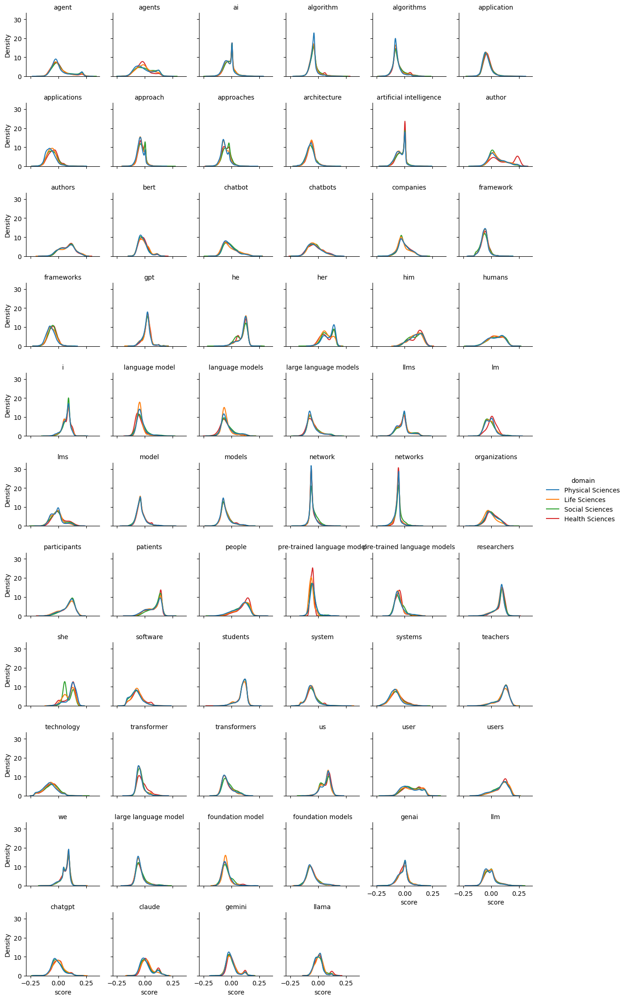

In [12]:
g = sns.displot(df_dedupl, kind="kde", x="score", col="entity_lower", col_wrap=6, common_norm=False, height=2, hue="domain", hue_order=domain_order)
g.set_titles("{col_name}")

### Robustness check with human pronouns

In [176]:
df_dedupl[df_dedupl["entity_lower"].isin(human_pronouns)].groupby("entity_lower", observed=True)["humanlike"].agg(["mean", "std"]).sort_values("mean", ascending=False)

,mean,std
entity_lower,,
she,0.967418,0.177577
he,0.960677,0.194379
i,0.959725,0.196610
her,0.955894,0.205371
him,0.952797,0.212258
us,0.933664,0.248882
we,0.920233,0.270932


In [11]:
print(pd.DataFrame(df_dedupl[df_dedupl["entity_lower"].isin(human_pronouns)].groupby("entity_lower", observed=True)["humanlike"].mean().sort_values(ascending=False)).T.to_latex(float_format="%.3f"))

\begin{tabular}{lrrrrrrr}
\toprule
entity_lower & she & he & i & her & him & us & we \\
\midrule
humanlike & 0.967 & 0.961 & 0.960 & 0.956 & 0.953 & 0.934 & 0.920 \\
\bottomrule
\end{tabular}



### Binary interpretation of human-likeness

In [27]:
ents_to_compare = "gpt claude llama chatgpt genai agent lm gemini llm ai bert chatbot model algorithm technology system".split()

In [47]:
humanlike_binary = df_dedupl[df_dedupl["entity_lower"].isin(ents_to_compare)].groupby(["domain", "entity_lower"], observed=True)["humanlike"].mean().unstack("domain")
hum_bin_order = humanlike_binary.mean(axis=1).sort_values(ascending=False).index
humanlike_binary.loc[hum_bin_order, domain_order].style.background_gradient(axis=None)

domain,Physical Sciences,Life Sciences,Social Sciences,Health Sciences
entity_lower,,,,
gpt,0.727500,0.788354,0.734162,0.794447
claude,0.501171,0.622754,0.547789,0.645540
llama,0.534151,0.618026,0.524721,0.609453
chatgpt,0.372029,0.489484,0.409589,0.490360
genai,0.423077,0.473934,0.455825,0.397603
agent,0.404952,0.416667,0.499238,0.428430
lm,0.397942,0.395349,0.331034,0.608696
gemini,0.356810,0.421053,0.376157,0.472482
llm,0.339821,0.374224,0.401823,0.425681


In [48]:
# Contrasted with mean scores
humanlike_mean = df_dedupl[df_dedupl["entity_lower"].isin(ents_to_compare)].groupby(["domain", "entity_lower"], observed=True)["score"].mean().unstack("domain")
hum_mean_order = humanlike_mean.mean(axis=1).sort_values(ascending=False).index
humanlike_mean.loc[hum_mean_order, domain_order].style.background_gradient(axis=None)

domain,Physical Sciences,Life Sciences,Social Sciences,Health Sciences
entity_lower,,,,
claude,0.014399,0.019656,0.021009,0.030336
gpt,0.013883,0.018420,0.016570,0.020982
agent,0.015605,0.011507,0.025314,0.007847
llama,0.003027,0.010777,0.007784,0.015853
gemini,-0.003065,0.001088,-0.000664,0.010301
chatgpt,-0.009092,0.003447,-0.004669,0.002656
lm,-0.010174,-0.010208,-0.012870,0.008628
llm,-0.015094,-0.011365,-0.005975,-0.004538
chatbot,-0.014508,-0.010573,-0.007183,-0.013278


In [49]:
# Contrasted with median scores
humanlike_median = df_dedupl[df_dedupl["entity_lower"].isin(ents_to_compare)].groupby(["domain", "entity_lower"], observed=True)["score"].median().unstack("domain")
hum_med_order = humanlike_median.mean(axis=1).sort_values(ascending=False).index
humanlike_median.loc[hum_med_order, domain_order].style.background_gradient(axis=None)

domain,Physical Sciences,Life Sciences,Social Sciences,Health Sciences
entity_lower,,,,
gpt,0.018378,0.021930,0.020135,0.023408
claude,0.000072,0.014354,0.007410,0.015110
llama,0.003165,0.011034,0.002381,0.009582
chatgpt,-0.016567,-0.001840,-0.011970,-0.001242
genai,-0.010571,-0.005139,-0.005467,-0.011831
agent,-0.012231,-0.011441,-0.000180,-0.009781
lm,-0.011439,-0.015365,-0.020291,0.009249
gemini,-0.012990,-0.010167,-0.013840,-0.003035
llm,-0.023024,-0.016712,-0.011182,-0.009432


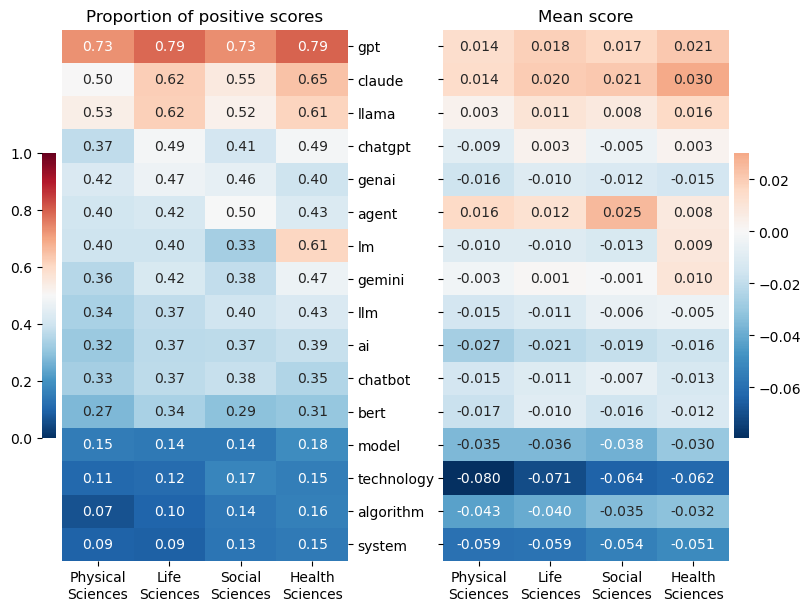

In [95]:
fig, axes = plt.subplots(1, 2, figsize=(8, 6), layout="constrained")

xlabels = [d.replace(" ", "\n") for d in domain_order]
    
sns.heatmap(humanlike_binary.loc[hum_bin_order, domain_order], cmap="RdBu_r",
            cbar_kws={'location': 'left', "pad": 0.02, "fraction": 0.05},
            ax=axes[0], vmin=0, vmax=1, annot=True, fmt=".2f",
            xticklabels=xlabels)
axes[0].set_title("Proportion of positive scores")
#axes[0].set_yticks([])
axes[0].tick_params(axis="y", left=False, labelleft=False, right=True, labelright=True, rotation=0)
axes[0].set_ylabel("")
axes[0].set_xlabel("")

sns.heatmap(humanlike_mean.loc[hum_bin_order, domain_order], cmap="RdBu_r",
            cbar_kws={"pad": 0.02, "fraction": 0.05},
            annot=True, ax=axes[1], fmt=".3f", center=0,
            xticklabels=xlabels)
axes[1].set_title("Mean score")
axes[1].tick_params(axis="y", left=True, labelleft=False)
axes[1].set_ylabel("")
axes[1].set_xlabel("")

#plt.tight_layout()
plt.savefig("../figures/binary-vs-mean.pdf", bbox_inches="tight")
plt.show()

In [105]:
(humanlike_binary.loc["claude"] - humanlike_binary.loc["gpt"]).mean()

-0.18180193351296955

In [106]:
(humanlike_mean.loc["claude"] - humanlike_mean.loc["gpt"]).mean()

0.003886240276956888

### Verbs as entities?

In [11]:
# How many of the entities are detected as verbs, likely making them invalid for analysis?
verbs = (df_dedupl[df_dedupl["pos"] == "VERB"]).copy()
len(verbs) / len(df_dedupl)

0.003692333460868661

In [18]:
verbs.entity_lower.value_counts()[lambda x: x > 100]

entity_lower
model                      3039
algorithms                 2933
approach                   1372
models                      904
ai                          816
approaches                  739
llm                         223
llms                        134
artificial intelligence     115
Name: count, dtype: int64

In [19]:
3039/len(df_dedupl)

0.00102624852639289

In [17]:
for sent in verbs[verbs["entity_lower"] == "models"].sample(10)["sentence"]:
    print(sent)

Unlike traditional competency frameworks, the GENESIS L-Level model does not classify skills — it models system impact under stress.
To address these, we introduce the Federated Tumor Segmentation (FeTS) Initiative, as an international consortium using federated learning (FL) for data-private multi-institutional collaborations, where AI models leverage data at participating institutions, without sharing data between them.
Here, we introduce neural interaction explainable AI (NeurixAI), an explainable and highly scalable deep learning framework that models drug-gene interactions and identifies transcriptomic patterns linked with drug response.
CDR models conceptual knowledge as inherently subject to entropylike structural degradation across time and context, necessitating continuous monitoring, detection, and restorative regulation to preserve depth and coherence.
Grounded in Bayes' theorem, CHBR models the concept used in human image recognition as latent variables and formulates this 

Decision: given that terms are not reliably actually used as verbs, despite classified as such by spaCy, and comprising only 0.3% of all data, I will leave the verbs untouched. I do not believe dropping them would significantly affect the results, though it should be kept in mind in future work to constrain the target entoty selection more carefully.

In [9]:
# Drop the human annotations to look at the scores of artifact + LM scores
no_human = df_dedupl[df_dedupl["entity_type"] != "human"].copy()

In [12]:
no_human.entity_type_updated.value_counts()

entity_type_updated
artifact     1958102
lm            295301
propn_llm      39236
Name: count, dtype: int64

In [13]:
no_human.entity_type_updated.value_counts(normalize=True)

entity_type_updated
artifact     0.854082
lm           0.128804
propn_llm    0.017114
Name: proportion, dtype: float64

In [25]:
# How many of the papers contain only a single sentence?
print("Contains single sentence:")
no_human.groupby("id", observed=True).size().value_counts().value_counts().loc[1]

Contains single sentence:


30

## Doc-level inspection

### Load data, initialize helpers etc.

In [20]:
def get_doc_summary(df: pd.DataFrame):
    return df.groupby("id", observed=True).agg(
        year=("year", "first"),
        domain=("domain", "first"),
        
        contains_artifact=("entity_type", lambda x: (x == "artifact").any()),
        contains_lm=("entity_type", lambda x: (x == "lm").any()),
        contains_propn_llm=("is_propn_llm", lambda x: (x == True).any()),
        contains_human=("entity_type", lambda x: (x == "human").any()),
        
        num_artifact=("entity_type", lambda x: (x == "artifact").sum()),
        num_lm=("entity_type_updated", lambda x: (x == "lm").sum()),
        num_propn_llm=("entity_type_updated", lambda x: (x == "propn_llm").sum()),
        num_human=("entity_type", lambda x: (x == "human").sum()),
        num_sents=("id", "size"),
        num_unique_entities=("entity_lower", "nunique"),

        avg_score=("score", lambda x: x[df.loc[x.index, "entity_type"] != "human"].mean()),
        avg_score_artifact=("score", lambda x: x[df.loc[x.index, "entity_type"] == "artifact"].mean()),
        avg_score_lm=("score", lambda x: x[df.loc[x.index, "entity_type"] == "lm"].mean()),
        avg_score_lm_no_propn=("score", lambda x: x[df.loc[x.index, "entity_type_updated"] == "lm"].mean()),
        avg_score_propn_llm=("score", lambda x: x[df.loc[x.index, "entity_type_updated"] == "propn_llm"].mean()),
        avg_score_human=("score", lambda x: x[df.loc[x.index, "entity_type"] == "human"].mean())
    )

In [73]:
def add_to_doc_summary(df: pd.DataFrame):
    return df.groupby("id", observed=True).agg(
        num_unique_entities_nonhum=("entity_lower", lambda x: x[df.loc[x.index, "entity_type"] != "human"].nunique())
    )

In [21]:
#docs = get_doc_summary(df_dedupl)

In [51]:
#docs.to_csv("../data/doc-level-scores.csv", index=False)

In [244]:
doc_cat_cols = "year domain paper_type".split()
doc_dtype = {col: "category" for col in doc_cat_cols}

In [245]:
docs = pd.read_csv("../data/doc-level-scores.csv", dtype=doc_dtype)

In [246]:
docs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284148 entries, 0 to 284147
Data columns (total 21 columns):
 #   Column                 Non-Null Count   Dtype   
---  ------                 --------------   -----   
 0   id                     284148 non-null  object  
 1   year                   284148 non-null  category
 2   domain                 284148 non-null  category
 3   contains_artifact      284148 non-null  bool    
 4   contains_lm            284148 non-null  bool    
 5   contains_propn_llm     284148 non-null  bool    
 6   contains_human         284148 non-null  bool    
 7   num_artifact           284148 non-null  int64   
 8   num_lm                 284148 non-null  int64   
 9   num_propn_llm          284148 non-null  int64   
 10  num_human              284148 non-null  int64   
 11  num_sents              284148 non-null  int64   
 12  num_unique_entities    284148 non-null  int64   
 13  avg_score              283183 non-null  float64 
 14  avg_score_artifact  

In [247]:
docs.isna().sum()

id                            0
year                          0
domain                        0
contains_artifact             0
contains_lm                   0
contains_propn_llm            0
contains_human                0
num_artifact                  0
num_lm                        0
num_propn_llm                 0
num_human                     0
num_sents                     0
num_unique_entities           0
avg_score                   965
avg_score_artifact         5818
avg_score_lm             196016
avg_score_lm_no_propn    201140
avg_score_propn_llm      270032
avg_score_human           82439
post_chatgpt                  0
paper_type                    0
dtype: int64

In [248]:
docs["num_nonhuman_sents"] = docs["num_artifact"] + docs["num_lm"] + docs["num_propn_llm"]

In [249]:
avg_score_cols = [col for col in docs.columns if col.startswith("avg_score")]
contains_cols = [col for col in docs.columns if col.startswith("contains")]
num_cols = [col for col in docs.columns if col.startswith("num")]
sorted_avg_cols = docs[avg_score_cols].mean().sort_values().index

In [250]:
col_to_label = {
    "avg_score_artifact": "Artifact",
    "avg_score": "Artifact + LM",
    "avg_score_lm_no_propn": "LM",
    "avg_score_lm": "LM",
    "avg_score_propn_llm": "Product name",
    "avg_score_human": "Human"
}
to_plot_cols = ["avg_score_artifact", "avg_score_lm_no_propn", "avg_score_propn_llm", "avg_score_human"]

In [251]:
hue_order = ["Physical Sciences", "Life Sciences", "Social Sciences", "Health Sciences"]
size_order = ["Physical Sciences", "Social Sciences", "Health Sciences", "Life Sciences"]

In [252]:
pt_order = ["artifact", "lm", "propn"] # pt as in paper_type

In [207]:
legend_map = {
    "artifact": "artifact",
    "lm": "LM",
    "propn_llm": "product name",
    "propn": "product name",
    "human": "human",
    "human_pron": "human pronoun"
}

In [140]:
abbreviation_map = {
    "Physical Sciences": "PS",
    "Life Sciences": "LS",
    "Social Sciences": "SS",
    "Health Sciences": "HS"
}

In [253]:
et_palette = sns.color_palette("seismic", 4)
et_palette

[(0.0, 0.0, 0.8599999999999999),
 (0.6, 0.6, 1.0),
 (1.0, 0.6, 0.6),
 (0.9, 0.0, 0.0)]

In [ ]:
# For visualizing how much counts deviate from expected counts under independence
def standardize(table):
    row_totals = table.sum(axis=1)
    col_totals = table.sum(axis=0)
    grand_total = table.sum().sum()
    
    E = np.outer(row_totals, col_totals) / grand_total
    E = pd.DataFrame(E, index=table.index, columns=table.columns)
    
    lift = table / E
    log_lift = np.log(lift.mask(lift == 0, np.nan))
    return log_lift

### Report descriptive statistics

In [23]:
print("Number of unique abstract IDs:", docs.id.nunique())

Number of unique abstract IDs: 284148


In [24]:
print("Number of abstracts that contain artifact/LM/product name mention:", len(docs[docs["paper_type"] != "human_only"]))
assert docs.id.nunique() - len(docs[docs["paper_type"] == "human_only"]) == len(docs[docs["paper_type"] != "human_only"])

Number of abstracts that contain artifact/LM/product name mention: 283183


The differences in the following numbers is that `paper_type` is assigned in "priority order":
- proper noun LLM (--> product name)
- LM
- artifact
meaning that the paper is first checked for proper noun LLM, if not found, then checked for LM, if not found, then checked for artifact, and last classified as `human_only`.

In the `contains_cols`, the value does not depend on other values; a single abstract can include many entity types.

In [25]:
pd.DataFrame({"count": docs.paper_type.value_counts(),
              "proportion": docs.paper_type.value_counts(normalize=True)})

,count,proportion
paper_type,,
artifact,195051,0.686442
lm,74016,0.260484
propn,14116,0.049678
human_only,965,0.003396


In [26]:
for col in contains_cols:
    vc = docs[col].value_counts()
    vcn = docs[col].value_counts(normalize=True)
    display(pd.DataFrame({"count": vc, "proportion": vcn}))
    print()

,count,proportion
contains_artifact,,
True,278330,0.979525
False,5818,0.020475


,count,proportion
contains_lm,,
False,196016,0.689838
True,88132,0.310162


,count,proportion
contains_propn_llm,,
False,270032,0.950322
True,14116,0.049678


,count,proportion
contains_human,,
True,201709,0.709873
False,82439,0.290127


In [27]:
# contains propn_llm / contains_lm
print(f"{14116/88132:.2%} of abstracts that include LM terms include product name terms")

16.02% of abstracts that include LM terms include product name terms


What each average includes:
- `avg_score_artifact`: only scores for artifact terms
- `avg_score`: average of artifact + LM + proper noun LM terms
- `avg_score_lm_no_propn`: average of LM only (excluding pn)
- `avg_score_lm`: LM + proper noun LLM
- `avg_score_propn_llm`: average of proper noun LLM only (excluding LM)
- `avg_score_human`: average of human scores

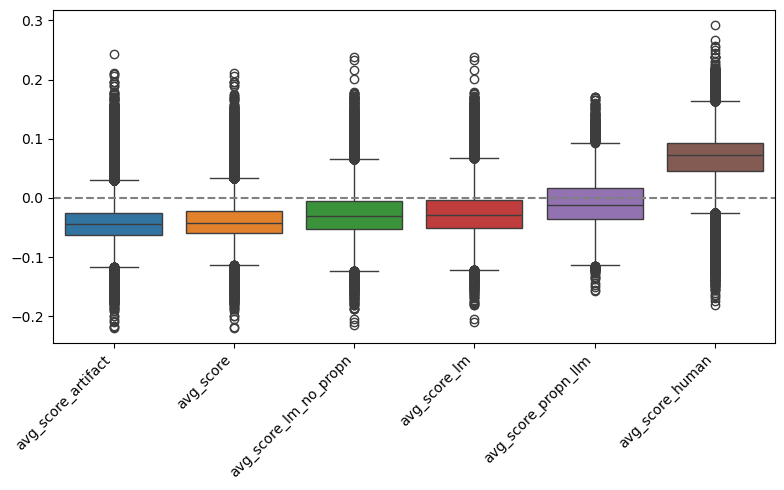

In [28]:
plt.figure(figsize=(8, 5))
ax = sns.boxplot(docs[sorted_avg_cols])
ax.axhline(0, color="gray", linestyle="--")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

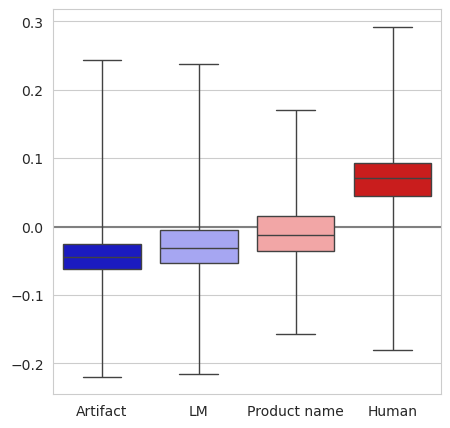

In [32]:
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.axhline(0, color="gray")
    sns.boxplot(docs[to_plot_cols].rename(columns=col_to_label), palette="seismic", whis=(0, 100), fliersize=2, ax=ax)
    #plt.xticks(rotation=45, ha="right")
    #plt.tight_layout()
    plt.savefig("../figures/entity_type_scores.pdf", bbox_inches="tight")
    plt.show()

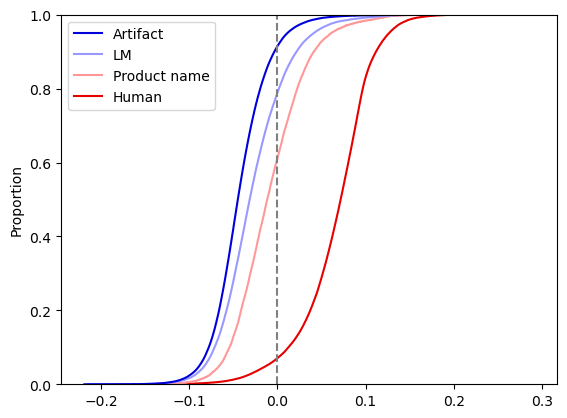

In [33]:
ax = sns.ecdfplot(docs[to_plot_cols].rename(columns=col_to_label), palette="seismic")
ax.axvline(0, color="gray", linestyle="--")
plt.show()

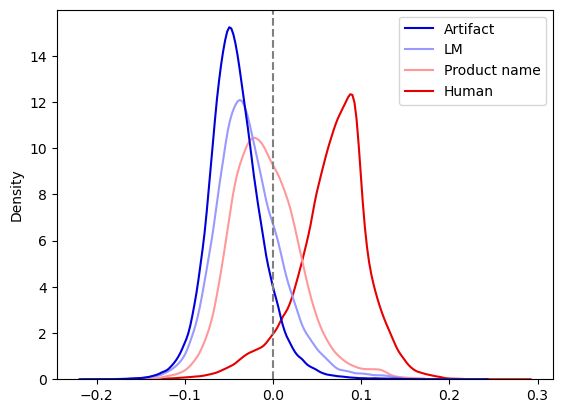

In [34]:
ax = sns.kdeplot(docs[to_plot_cols].rename(columns=col_to_label), palette="seismic", common_norm=False, cut=0)
ax.axvline(0, color="gray", linestyle="--")

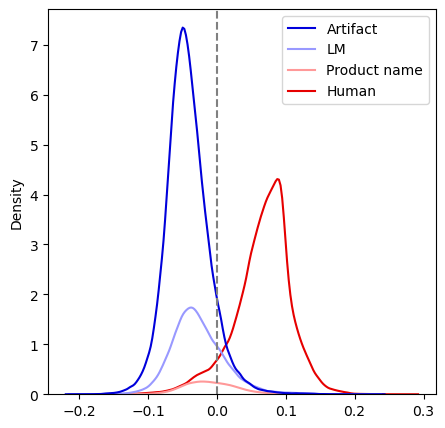

In [35]:
plt.figure(figsize=(5,5))
ax = sns.kdeplot(docs[to_plot_cols].rename(columns=col_to_label), palette="seismic", cut=0)
ax.axvline(0, color="gray", linestyle="--")
plt.savefig("../figures/entity_type_scores_kde.pdf", bbox_inches="tight")
plt.show()

In [42]:
docs[sorted_avg_cols].describe()

,avg_score_artifact,avg_score,avg_score_lm_no_propn,avg_score_lm,avg_score_propn_llm,avg_score_human
count,278330.000000,283183.000000,83008.000000,88132.000000,14116.000000,201709.000000
mean,-0.042318,-0.039616,-0.027254,-0.025372,-0.008066,0.066423
std,0.031504,0.030626,0.038943,0.038285,0.040155,0.041596
min,-0.219427,-0.219427,-0.215185,-0.209236,-0.157619,-0.180921
25%,-0.062041,-0.058962,-0.052629,-0.050746,-0.035670,0.045159
50%,-0.044888,-0.041955,-0.031474,-0.029483,-0.011600,0.071712
75%,-0.025051,-0.022102,-0.005503,-0.003589,0.015947,0.092589
max,0.243426,0.211933,0.238203,0.238203,0.171064,0.292030


In [57]:
docs[num_cols].describe()

,num_artifact,num_lm,num_propn_llm,num_human,num_sents,num_unique_entities,num_nonhuman_sents,num_unique_entities_nonhum
count,284148.000000,284148.000000,284148.000000,284148.000000,284148.000000,284148.000000,284148.000000,284148.000000
mean,6.891134,1.039251,0.138083,2.353112,10.421580,5.495777,8.068468,4.399559
std,5.563382,2.241531,0.876848,3.700568,7.531501,2.421658,5.845376,2.137519
min,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,3.000000,0.000000,0.000000,0.000000,6.000000,4.000000,4.000000,3.000000
50%,6.000000,0.000000,0.000000,2.000000,9.000000,5.000000,7.000000,4.000000
75%,9.000000,1.000000,0.000000,3.000000,13.000000,7.000000,11.000000,6.000000
max,256.000000,78.000000,75.000000,256.000000,316.000000,31.000000,256.000000,24.000000


Below shows how many unique (nonhuman) entities each abstract contributes.

In [58]:
docs.groupby(["domain"], observed=True)["num_unique_entities_nonhum"].agg(["mean", "median", "std", "min", "max"])

,mean,median,std,min,max
domain,,,,,
Health Sciences,3.922272,4.0,2.220034,0,24
Life Sciences,3.991328,4.0,2.196137,0,23
Physical Sciences,4.736067,5.0,2.096165,0,24
Social Sciences,4.051473,4.0,2.021411,0,21


In [59]:
docs.groupby(["domain", "year"], observed=True)["num_unique_entities_nonhum"].agg(["mean", "median", "std", "min", "max"]).unstack("domain")

mean                                                  \
domain Health Sciences Life Sciences Physical Sciences Social Sciences   
year                                                                     
2016          1.891892      2.206897          3.958206        2.833333   
2017          2.046025      2.489540          3.960737        2.997183   
2018          2.580645      2.555556          3.945397        3.343179   
2019          3.138232      2.781250          4.068144        3.312351   
2020          3.352209      3.159875          4.202461        3.401659   
2021          3.461409      3.281615          4.275631        3.585953   
2022          3.549579      3.506598          4.345626        3.660775   
2023          3.989375      3.683911          4.541718        3.802736   
2024          4.053085      4.095775          4.781783        4.052604   
2025          4.138039      4.398985          5.040370        4.299278   
2026          4.024133      4.454545          5.093992        4.416821   

                median                                                  \
domain Health Sciences Life Sciences Physical Sciences Social Sciences   
year                                                                     
2016               1.0           2.0               4.0             3.0   
2017               2.0           2.0               4.0             3.0   
2018               2.0           2.0               4.0             3.0   
2019               3.0           2.0               4.0             3.0   
2020               3.0           3.0               4.0             3.0   
2021               3.0           3.0               4.0             3.0   
2022               3.0           3.0               4.0             3.0   
2023               4.0           3.0               4.0             4.0   
2024               4.0           4.0               5.0             4.0   
2025               4.0           4.0               5.0             4.0   
2026               4.0           4.0               5.0             4.0   

                   std                                                  \
domain Health Sciences Life Sciences Physical Sciences Social Sciences   
year                                                                     
2016          1.432992      1.717896          1.931819        1.856811   
2017          1.470285      1.851327          1.826271        1.989377   
2018          1.909735      2.044037          1.861623        1.955946   
2019          2.305165      2.050025          1.908602        1.784560   
2020          1.968091      2.004584          1.892551        1.743071   
2021          1.978281      1.946730          1.943105        1.798424   
2022          2.006888      1.995031          1.943433        1.840040   
2023          2.210421      2.063584          2.005572        1.905990   
2024          2.176173      2.112706          2.059414        1.953289   
2025          2.241008      2.204926          2.148019        2.072023   
2026          2.428182      2.265798          2.301156        2.251315   

                   min                                                  \
domain Health Sciences Life Sciences Physical Sciences Social Sciences   
year                                                                     
2016                 0             0                 0               0   
2017                 0             0                 0               0   
2018                 0             0                 0               0   
2019                 0             0                 0               0   
2020                 0             0                 0               0   
2021                 0             0                 0               0   
2022                 0             0                 0               0   
2023                 0             0                 0               0   
2024                 0             0                 0               0   
2025               

Around 4% of the abstracts only contribute one technical entity.

In [60]:
len(docs[docs["num_nonhuman_sents"] == 1]) / len(docs)

0.03819136506327688

In [22]:
docs_no_human = (docs[docs["paper_type"] != "human_only"]).copy()
docs_no_human["paper_type"] = docs_no_human["paper_type"].cat.remove_unused_categories()
docs_no_human["year"] = docs_no_human["year"].astype("category")

<Axes: xlabel='post_chatgpt'>

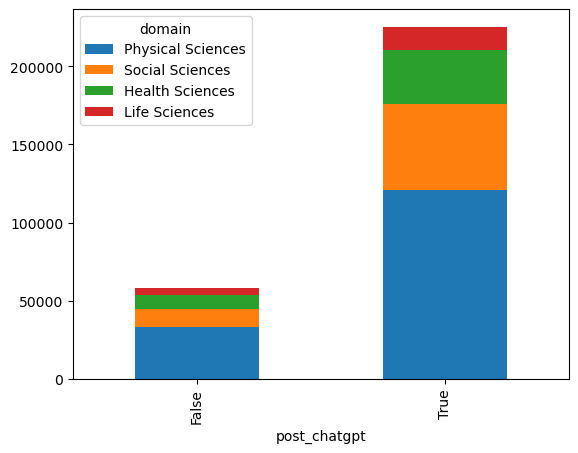

In [168]:
docs_no_human.groupby("domain", observed=True)["post_chatgpt"].value_counts().unstack("domain").sort_index()[size_order].plot.bar(stacked=True)

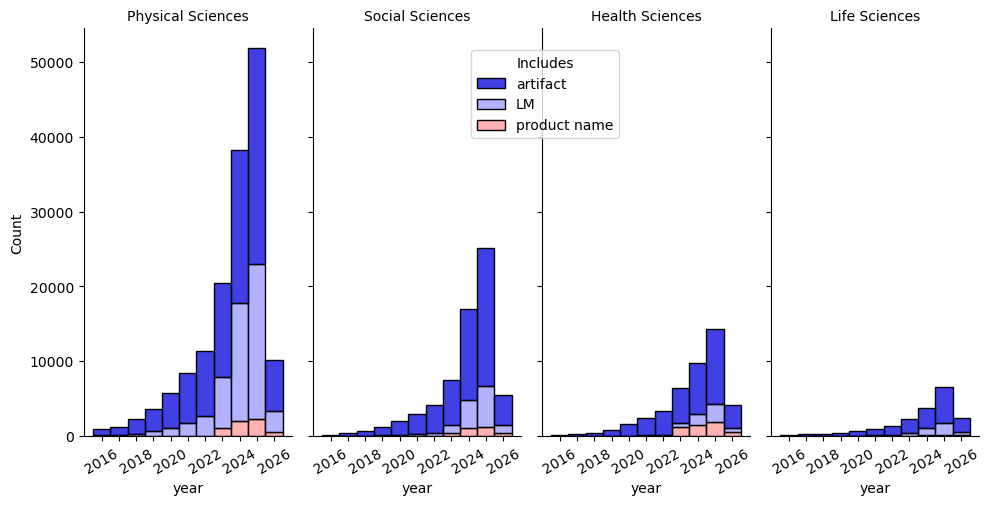

In [56]:
renamed = docs_no_human.rename(columns={"paper_type": "Includes"})
renamed["Includes"] = renamed["Includes"].cat.rename_categories(legend_map)
g = sns.displot(renamed, x="year", hue="Includes", col="domain", col_order=size_order,
                multiple="stack", palette=et_palette[:-1], height=5, aspect=0.5, facet_kws=dict(legend_out=False))
g.set_titles(col_template="{col_name}")
years = sorted(renamed["year"].unique())
n = 2
labels = [str(y) if i % n == 0 else "" for i, y in enumerate(years)]
g.set_xticklabels(labels, rotation=30)
sns.move_legend(g, "center", bbox_to_anchor=(0.55, 0.8), frameon=True)
plt.savefig("../figures/displot.pdf", bbox_inches="tight")
plt.show()

In [62]:
# How many of the papers either contain or not LM terms per each year and domain?
docs.groupby(["domain", "contains_lm"], observed=True)["year"].value_counts().unstack("year").swaplevel().sort_index() #.plot.bar(stacked=True)

year                           2016  2017  2018  2019  2020  2021  2022  \
contains_lm domain                                                        
False       Health Sciences     183   238   398   785  1563  2299  3212   
            Life Sciences       173   231   280   434   609   876  1232   
            Physical Sciences   846  1073  1913  2979  4659  6637  8743   
            Social Sciences     179   320   669  1158  1892  2751  3714   
True        Health Sciences       2     1     5    18    44    72   116   
            Life Sciences         1     8     8    14    29    65   132   
            Physical Sciences   135   175   303   587  1110  1722  2619   
            Social Sciences       7    35    42    97   157   239   416   

year                            2023   2024   2025  2026  
contains_lm domain                                        
False       Health Sciences     4748   6897  10088  3152  
            Life Sciences       1885   2773   4733  1895  
            Physical Sciences  12589  20542  28916  6914  
            Social Sciences     6055  12304  18488  3991  
True        Health Sciences     1652   2861   4292  1116  
            Life Sciences        396   1038   1771   558  
            Physical Sciences   7894  17741  23028  3289  
            Social Sciences     1473   4729   6716  1419

In [64]:
contains_propn_summary = (docs.groupby(["domain", "contains_propn_llm"], observed=True)["year"]
    .value_counts().unstack("year").swaplevel().sort_index()) #.plot.bar(stacked=True)
contains_propn_summary

year                                  2016  2017  2018  2019  2020  2021  \
contains_propn_llm domain                                                  
False              Health Sciences     185   239   403   803  1607  2371   
                   Life Sciences       174   239   288   448   638   941   
                   Physical Sciences   981  1248  2216  3566  5769  8359   
                   Social Sciences     186   355   711  1255  2049  2990   
True               Health Sciences       0     0     0     0     0     0   
                   Life Sciences         0     0     0     0     0     0   
                   Physical Sciences     0     0     0     0     0     0   
                   Social Sciences       0     0     0     0     0     0   

year                                   2022   2023   2024   2025  2026  
contains_propn_llm domain                                               
False              Health Sciences     3319   5266   8277  12486  3736  
                   Life Sciences       1364   2237   3714   6341  2360  
                   Physical Sciences  11343  19450  36299  49739  9719  
                   Social Sciences     4128   7138  16020  23980  5095  
True               Health Sciences        9   1134   1481   1894   532  
                   Life Sciences          0     44     97    163    93  
                   Physical Sciences     19   1033   1984   2205   484  
                   Social Sciences        2    390   1013   1224   315

In [67]:
contains_propn_summary.loc[(True, "Physical Sciences")].sum()

5725

In [68]:
contains_propn_summary.loc[(True, "Health Sciences")].sum()

5050

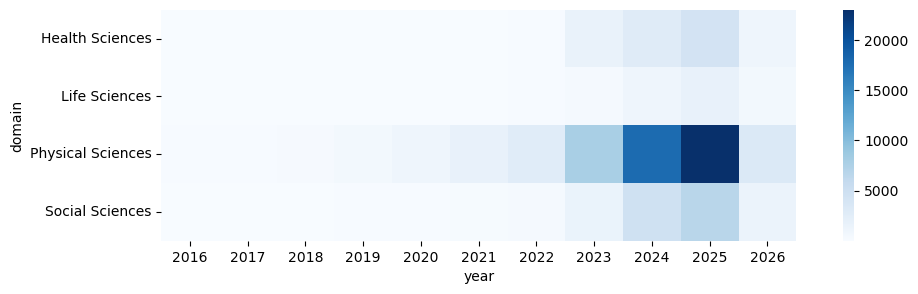

In [81]:
# A heatmap visualization of the number of LM papers per domain and year
def plot_lm_papers(subset_col, normalize_by=False, cmap="Blues", annot=False):
    subset = docs[docs[subset_col] == True]
    plt.figure(figsize=(12,3))
    sns.heatmap(pd.crosstab(subset["domain"], subset["year"], normalize=normalize_by), annot=annot, square=True, cmap=cmap)
    plt.show()
plot_lm_papers("contains_lm")

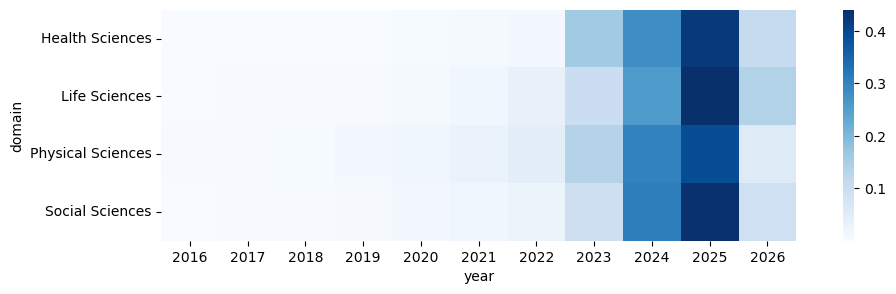

In [82]:
plot_lm_papers("contains_lm", "index")

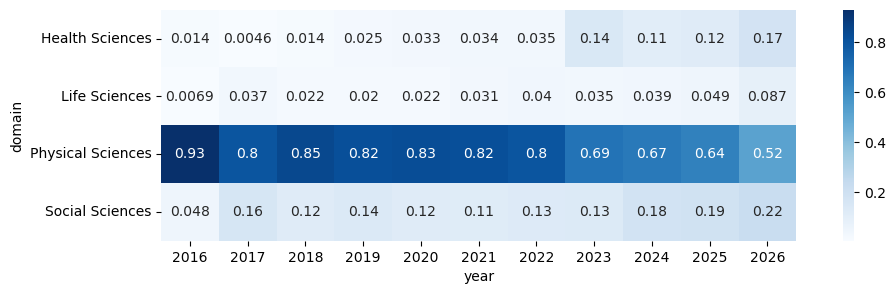

In [83]:
plot_lm_papers("contains_lm", "columns", annot=True)

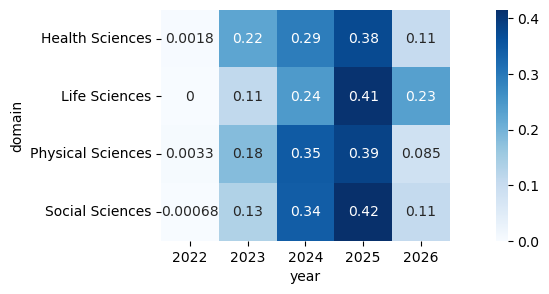

In [86]:
plot_lm_papers("contains_propn_llm", "index", annot=True)

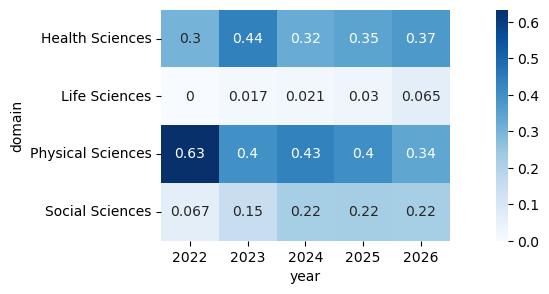

In [87]:
plot_lm_papers("contains_propn_llm", "columns", annot=True)

An interesting finding from above plots: proper noun LLMs are heavily utilized in Health Sciences, considering that 11-17% of LM papers per year (since 2023) come from that domain, while the proportion of proper noun LLM papers varies between 30-44% per year, which could explain the observed higher scores on average.

In [88]:
len(docs[(docs["contains_artifact"] == True) | (docs["contains_lm"] == True)]) / len(docs)

0.9966038824837761

The following heatmaps are visualizing how the average scores on document-level have evolved through years in different disciplines.

In [90]:
def plot_averages(docs, avg_score_col, title, vmin=-0.05, vmax=0.05):
    plt.figure(figsize=(14,5))
    sns.heatmap(
        docs.groupby(
            ["domain", "year"], observed=True
        )[avg_score_col].mean().unstack(), square=True, annot=True, cmap="coolwarm", vmin=vmin, vmax=vmax
    )
    plt.title(title)
    plt.show()

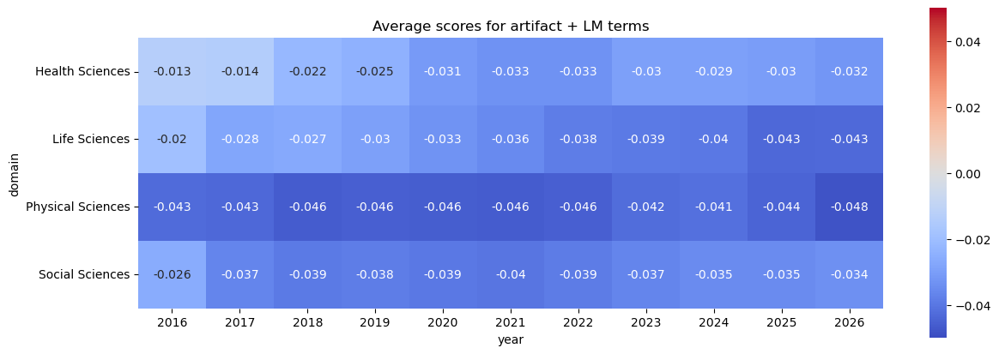

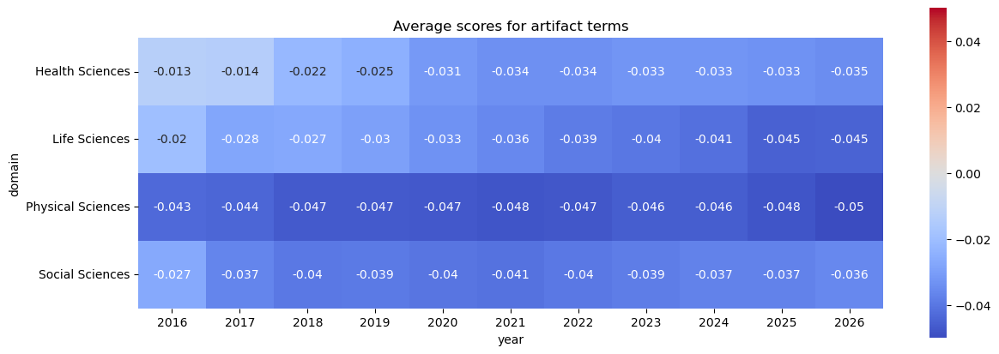

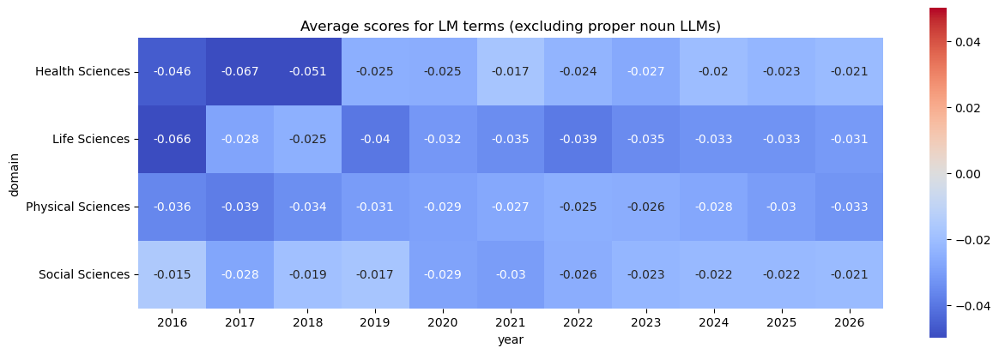

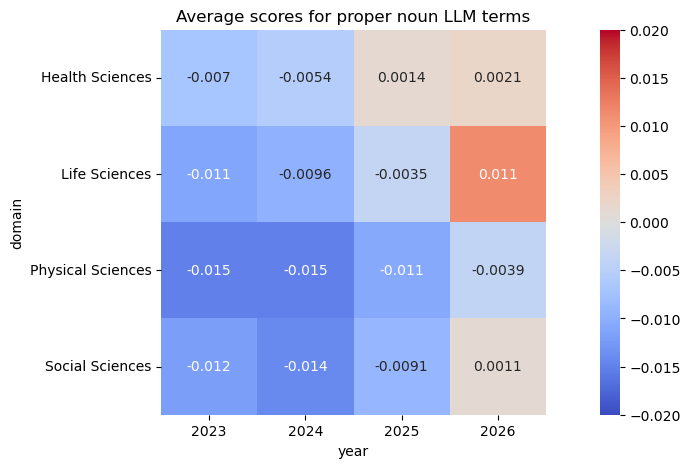

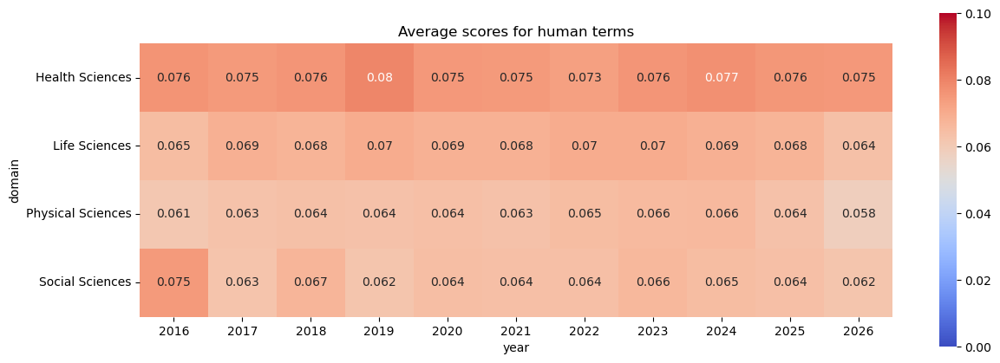

In [94]:
plot_args = (
    ("avg_score", "Average scores for artifact + LM terms"),
    ("avg_score_artifact", "Average scores for artifact terms"),
    ("avg_score_lm_no_propn", "Average scores for LM terms (excluding proper noun LLMs)"),
    ("avg_score_propn_llm", "Average scores for proper noun LLM terms"),
    ("avg_score_human", "Average scores for human terms")
)

for avg_score_col, title in plot_args:
    if "human" in avg_score_col:
        plot_averages(docs, avg_score_col, title, vmin=0, vmax=0.1)
    elif "llm" in avg_score_col:
        plot_averages(docs[docs["post_chatgpt"]], avg_score_col, title, vmin=-0.02, vmax=0.02)
    else:
        plot_averages(docs, avg_score_col, title)

In [254]:
docs[avg_score_cols].corr("spearman").style.background_gradient(axis=None)

,avg_score,avg_score_artifact,avg_score_lm,avg_score_lm_no_propn,avg_score_propn_llm,avg_score_human
avg_score,1.000000,0.919421,0.710353,0.681547,0.587368,0.127176
avg_score_artifact,0.919421,1.000000,0.217938,0.195450,0.174577,0.120530
avg_score_lm,0.710353,0.217938,1.000000,0.968548,0.797765,0.083003
avg_score_lm_no_propn,0.681547,0.195450,0.968548,1.000000,0.234620,0.070817
avg_score_propn_llm,0.587368,0.174577,0.797765,0.234620,1.000000,-0.009418
avg_score_human,0.127176,0.120530,0.083003,0.070817,-0.009418,1.000000


In [260]:
# Check if the individual entity type scores correlate
avg_score_ind_cols = ["avg_score_artifact", "avg_score_lm_no_propn", "avg_score_propn_llm", "avg_score_human"]
docs[avg_score_ind_cols].corr("spearman").style.background_gradient(axis=None)

,avg_score_artifact,avg_score_lm_no_propn,avg_score_propn_llm,avg_score_human
avg_score_artifact,1.000000,0.195450,0.174577,0.120530
avg_score_lm_no_propn,0.195450,1.000000,0.234620,0.070817
avg_score_propn_llm,0.174577,0.234620,1.000000,-0.009418
avg_score_human,0.120530,0.070817,-0.009418,1.000000


There is some, but weak, correlation between all non-human terms.

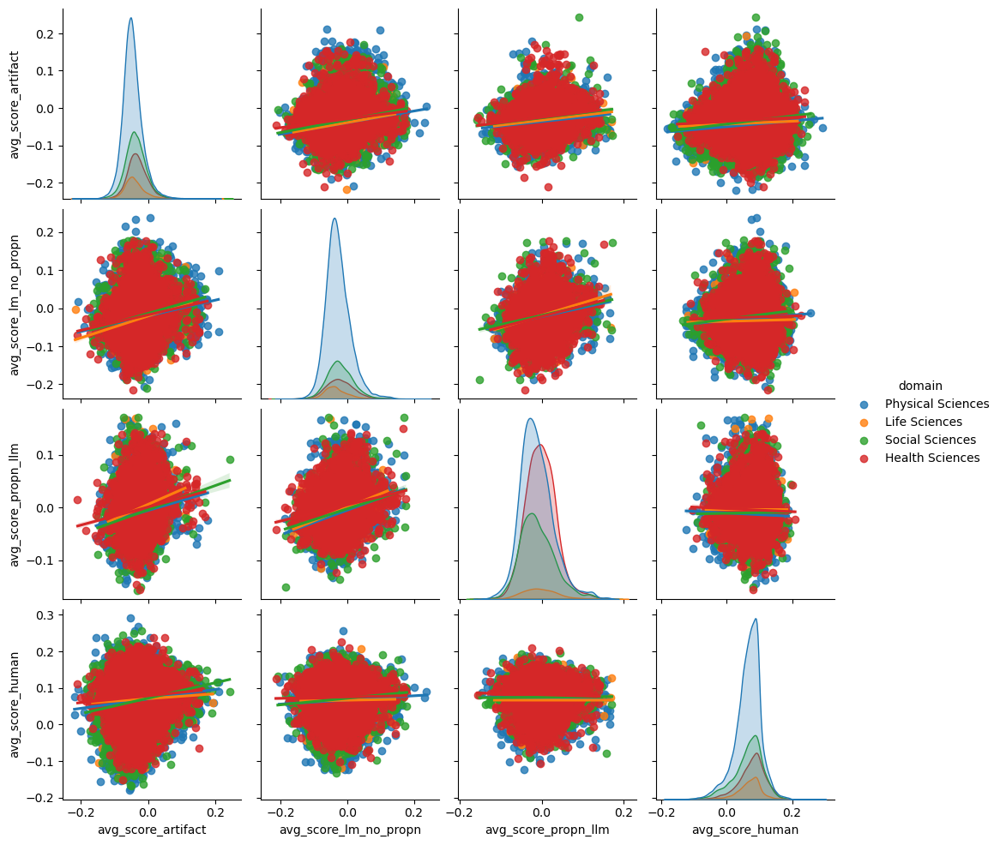

In [275]:
sns.pairplot(docs[avg_score_ind_cols + ["domain"]], kind="reg", hue="domain", hue_order=domain_order)
plt.show()

In [261]:
docs[avg_score_ind_cols + contains_cols].corr("spearman").style.background_gradient(axis=None)

,avg_score_artifact,avg_score_lm_no_propn,avg_score_propn_llm,avg_score_human,contains_artifact,contains_lm,contains_propn_llm,contains_human
avg_score_artifact,1.000000,0.195450,0.174577,0.120530,nan,0.026574,0.083065,0.086513
avg_score_lm_no_propn,0.195450,1.000000,0.234620,0.070817,-0.067117,nan,0.051670,0.030613
avg_score_propn_llm,0.174577,0.234620,1.000000,-0.009418,-0.087992,nan,nan,-0.062718
avg_score_human,0.120530,0.070817,-0.009418,1.000000,-0.025474,0.006123,0.058579,nan
contains_artifact,nan,-0.067117,-0.087992,-0.025474,1.000000,-0.163775,-0.043343,-0.045666
contains_lm,0.026574,nan,nan,0.006123,-0.163775,1.000000,0.340979,0.213040
contains_propn_llm,0.083065,0.051670,nan,0.058579,-0.043343,0.340979,1.000000,0.044771
contains_human,0.086513,0.030613,-0.062718,nan,-0.045666,0.213040,0.044771,1.000000


In [95]:
docs[avg_score_cols + contains_cols].corr("spearman").style.background_gradient(axis=None)

,avg_score,avg_score_artifact,avg_score_lm,avg_score_lm_no_propn,avg_score_propn_llm,avg_score_human,contains_artifact,contains_lm,contains_propn_llm,contains_human
avg_score,1.000000,0.919421,0.710353,0.681547,0.587368,0.127176,-0.086217,0.177184,0.155639,0.120116
avg_score_artifact,0.919421,1.000000,0.217938,0.195450,0.174577,0.120530,nan,0.026574,0.083065,0.086513
avg_score_lm,0.710353,0.217938,1.000000,0.968548,0.797765,0.083003,-0.068130,nan,0.165471,0.010328
avg_score_lm_no_propn,0.681547,0.195450,0.968548,1.000000,0.234620,0.070817,-0.067117,nan,0.051670,0.030613
avg_score_propn_llm,0.587368,0.174577,0.797765,0.234620,1.000000,-0.009418,-0.087992,nan,nan,-0.062718
avg_score_human,0.127176,0.120530,0.083003,0.070817,-0.009418,1.000000,-0.025474,0.006123,0.058579,nan
contains_artifact,-0.086217,nan,-0.068130,-0.067117,-0.087992,-0.025474,1.000000,-0.163775,-0.043343,-0.045666
contains_lm,0.177184,0.026574,nan,nan,nan,0.006123,-0.163775,1.000000,0.340979,0.213040
contains_propn_llm,0.155639,0.083065,0.165471,0.051670,nan,0.058579,-0.043343,0.340979,1.000000,0.044771
contains_human,0.120116,0.086513,0.010328,0.030613,-0.062718,nan,-0.045666,0.213040,0.044771,1.000000


In [96]:
docs[avg_score_cols + num_cols].corr("spearman").style.background_gradient(axis=None)

,avg_score,avg_score_artifact,avg_score_lm,avg_score_lm_no_propn,avg_score_propn_llm,avg_score_human,num_artifact,num_lm,num_propn_llm,num_human,num_sents,num_unique_entities,num_nonhuman_sents,num_unique_entities_nonhum
avg_score,1.000000,0.919421,0.710353,0.681547,0.587368,0.127176,-0.098143,0.174437,0.156866,0.165110,0.097130,-0.059193,0.032023,-0.129363
avg_score_artifact,0.919421,1.000000,0.217938,0.195450,0.174577,0.120530,-0.005502,0.005498,0.083502,0.128456,0.065279,-0.091109,0.009720,-0.153326
avg_score_lm,0.710353,0.217938,1.000000,0.968548,0.797765,0.083003,-0.102562,0.207368,0.174301,0.054458,0.115711,0.016614,0.099798,-0.012193
avg_score_lm_no_propn,0.681547,0.195450,0.968548,1.000000,0.234620,0.070817,-0.103712,0.290748,0.051474,0.068052,0.108421,0.026874,0.086677,-0.001245
avg_score_propn_llm,0.587368,0.174577,0.797765,0.234620,1.000000,-0.009418,-0.151390,0.102314,0.288896,-0.068822,0.028742,-0.024294,0.052734,-0.011719
avg_score_human,0.127176,0.120530,0.083003,0.070817,-0.009418,1.000000,-0.037041,-0.011662,0.059228,0.026662,-0.004149,-0.055320,-0.028622,-0.081970
num_artifact,-0.098143,-0.005502,-0.102562,-0.103712,-0.151390,-0.037041,1.000000,-0.247008,-0.041605,-0.012778,0.720618,0.572195,0.849337,0.634311
num_lm,0.174437,0.005498,0.207368,0.290748,0.102314,-0.011662,-0.247008,1.000000,0.181889,0.225547,0.240917,0.302903,0.194362,0.277991
num_propn_llm,0.156866,0.083502,0.174301,0.051474,0.288896,0.059228,-0.041605,0.181889,1.000000,0.066589,0.156344,0.134151,0.154128,0.120303
num_human,0.165110,0.128456,0.054458,0.068052,-0.068822,0.026662,-0.012778,0.225547,0.066589,1.000000,0.483512,0.372133,0.100134,0.038288


In [97]:
docs[avg_score_cols + num_cols].corr("spearman").style.background_gradient(axis=None)

,avg_score,avg_score_artifact,avg_score_lm,avg_score_lm_no_propn,avg_score_propn_llm,avg_score_human,num_artifact,num_lm,num_propn_llm,num_human,num_sents,num_unique_entities,num_nonhuman_sents,num_unique_entities_nonhum
avg_score,1.000000,0.919421,0.710353,0.681547,0.587368,0.127176,-0.098143,0.174437,0.156866,0.165110,0.097130,-0.059193,0.032023,-0.129363
avg_score_artifact,0.919421,1.000000,0.217938,0.195450,0.174577,0.120530,-0.005502,0.005498,0.083502,0.128456,0.065279,-0.091109,0.009720,-0.153326
avg_score_lm,0.710353,0.217938,1.000000,0.968548,0.797765,0.083003,-0.102562,0.207368,0.174301,0.054458,0.115711,0.016614,0.099798,-0.012193
avg_score_lm_no_propn,0.681547,0.195450,0.968548,1.000000,0.234620,0.070817,-0.103712,0.290748,0.051474,0.068052,0.108421,0.026874,0.086677,-0.001245
avg_score_propn_llm,0.587368,0.174577,0.797765,0.234620,1.000000,-0.009418,-0.151390,0.102314,0.288896,-0.068822,0.028742,-0.024294,0.052734,-0.011719
avg_score_human,0.127176,0.120530,0.083003,0.070817,-0.009418,1.000000,-0.037041,-0.011662,0.059228,0.026662,-0.004149,-0.055320,-0.028622,-0.081970
num_artifact,-0.098143,-0.005502,-0.102562,-0.103712,-0.151390,-0.037041,1.000000,-0.247008,-0.041605,-0.012778,0.720618,0.572195,0.849337,0.634311
num_lm,0.174437,0.005498,0.207368,0.290748,0.102314,-0.011662,-0.247008,1.000000,0.181889,0.225547,0.240917,0.302903,0.194362,0.277991
num_propn_llm,0.156866,0.083502,0.174301,0.051474,0.288896,0.059228,-0.041605,0.181889,1.000000,0.066589,0.156344,0.134151,0.154128,0.120303
num_human,0.165110,0.128456,0.054458,0.068052,-0.068822,0.026662,-0.012778,0.225547,0.066589,1.000000,0.483512,0.372133,0.100134,0.038288


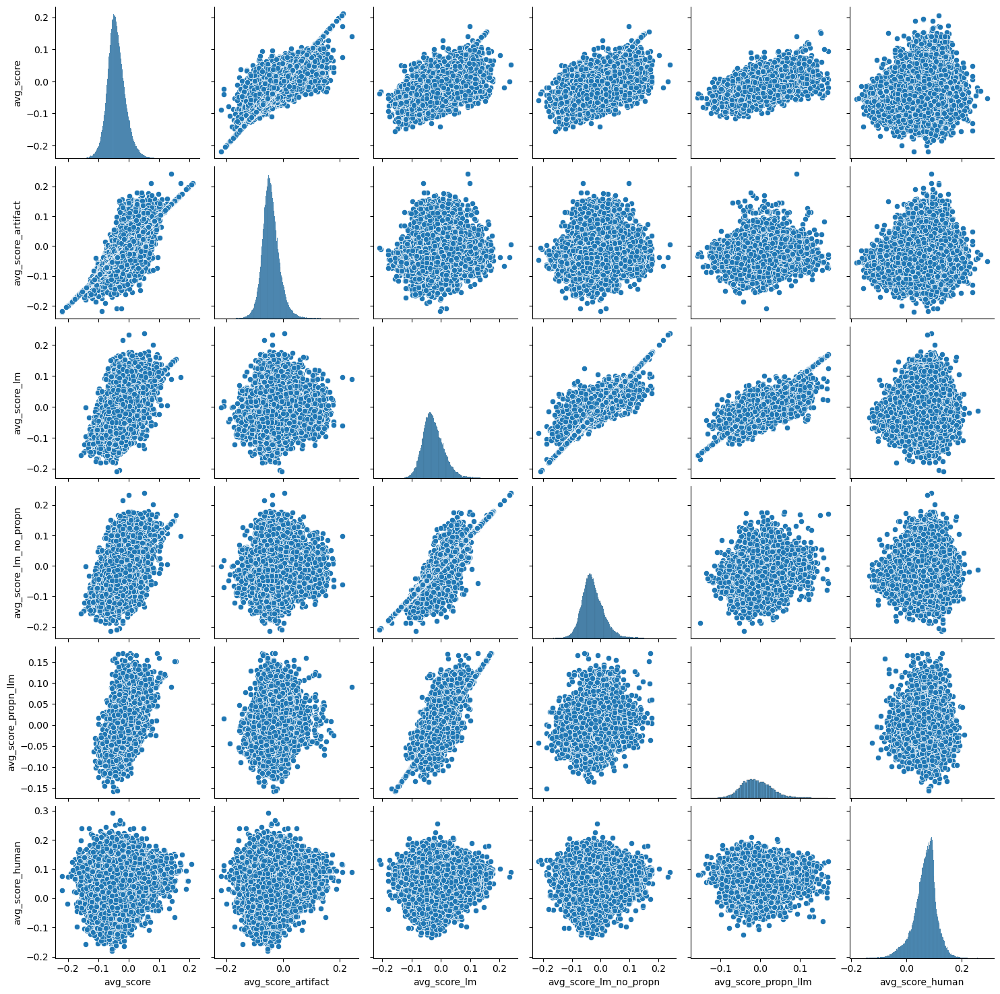

In [98]:
sns.pairplot(docs[avg_score_cols])
plt.show()

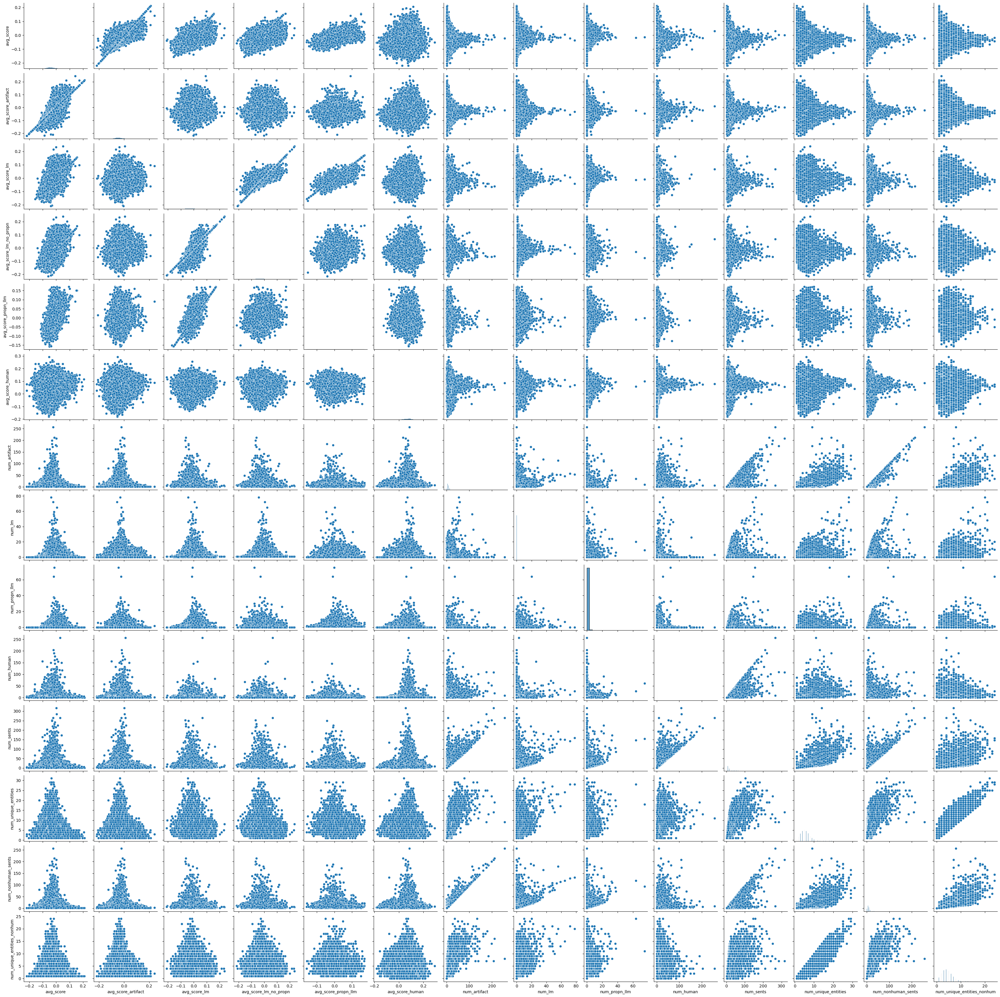

In [99]:
sns.pairplot(docs[avg_score_cols + num_cols])

In [100]:
for col in avg_score_cols:
    print(col)
    ser = docs.groupby("post_chatgpt", observed=True)[col].mean()
    print(ser)
    print("Diff:", ser[True] - ser[False]) # post - pre
    print()

avg_score
post_chatgpt
False   -0.041262
True    -0.039194
Name: avg_score, dtype: float64
Diff: 0.0020673859025280086

avg_score_artifact
post_chatgpt
False   -0.042229
True    -0.042341
Name: avg_score_artifact, dtype: float64
Diff: -0.00011217295894799112

avg_score_lm
post_chatgpt
False   -0.027692
True    -0.025135
Name: avg_score_lm, dtype: float64
Diff: 0.002556670360431921

avg_score_lm_no_propn
post_chatgpt
False   -0.027759
True    -0.027199
Name: avg_score_lm_no_propn, dtype: float64
Diff: 0.0005595538603166209

avg_score_propn_llm
post_chatgpt
False   -0.004228
True    -0.008074
Name: avg_score_propn_llm, dtype: float64
Diff: -0.0038462428878648126

avg_score_human
post_chatgpt
False    0.066189
True     0.066485
Name: avg_score_human, dtype: float64
Diff: 0.00029561690302994104



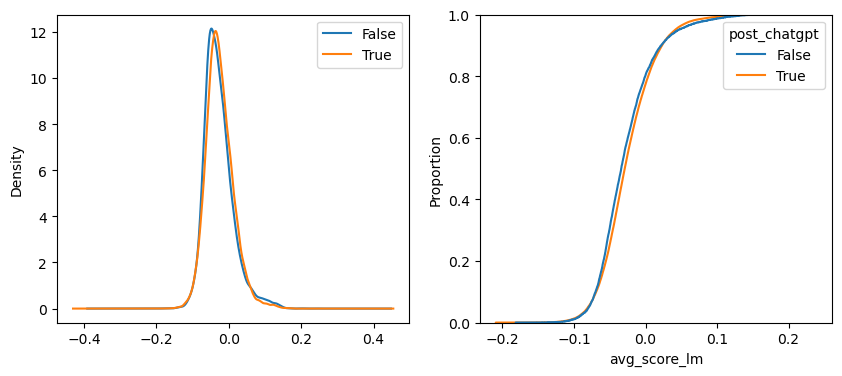

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes = axes.flatten()
docs.groupby("post_chatgpt", observed=True)["avg_score_lm"].plot.density(ax=axes[0], legend=True)
sns.ecdfplot(docs, hue="post_chatgpt", x="avg_score_lm", ax=axes[1])
plt.show()

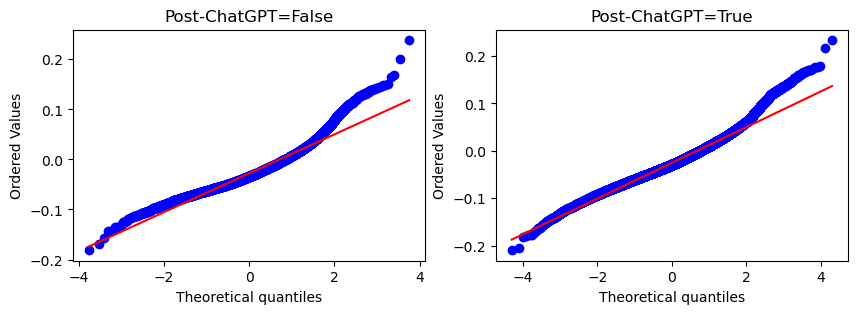

In [63]:
# By looking at a Q-Q plot, are the values normally distributed?
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes = axes.flatten()
for i, (name, subset) in enumerate(docs.groupby("post_chatgpt", observed=True)["avg_score_lm"]):
    stats.probplot(subset.dropna().values, plot=axes[i])
    axes[i].set_title(f"Post-ChatGPT={name}")

In [30]:
# As the data is not normally distributed, use a Mann-Whitney U rank test on two independent samples
mask = docs["post_chatgpt"] == False
pre = docs.loc[mask, "avg_score_lm"].dropna()
post = docs.loc[~mask, "avg_score_lm"].dropna()

In [31]:
# Calculate the effect size
# |r| ≈ 0.10 small, ≈ 0.30 medium, ≥ 0.50 large effect # https://metricgate.com/docs/rank-biserial-correlation/
def calc_rank_biseral(x, y):
    U1, p = stats.mannwhitneyu(x, y)
    U2 = (len(x) * len(y)) - U1
    U = min(U1, U2)
    rank_biserial = 1 - ((2*U) / (len(x) * len(y)))
    note = ""
    if rank_biserial > 0.5: note = "!!!"
    elif rank_biserial > 0.3: note = "!!"
    elif rank_biserial > 0.1: note = "!"
    print(f"U={U}, p={p:.3f}, rank_biserial={rank_biserial:.3f} {note}")

In [30]:
# How likely is it that a random score from post-ChatGPT group exceeds
# a random score from a pre-ChatGPT group?
calc_rank_biseral(pre, post)

U=304770439.0, p=0.000, rank_biserial=0.066 


Given the results from Mann-Whitney U test combined with Rank-Biseral Correlation, there doesn't seem to be evidence that the average scores for LM terms are significantly different in pre- or post-ChatGPT groups, because the effect size is only ~0.066, under 0.1, which is considered a small effect size.

In the following plots, the domains are inspected separately, revealing more differences. However, it looks like dividing papers into pre- and post-ChatGPT eras doesn't account for differences. (If anything, Life Sciences shows a small effect for the observation that artifact terms are less anthropomorhized *post*-ChatGPT, rather than more.) Instead, if the papers are not compared by era but if they contain mentions of proper noun LLMs, the differences seem to be larger, both visually and given the effect sizes. Artifact terms are generally more anthropomorphized when papers also include proper noun LM terms. Effect sizes are still below medium.

In [31]:
def plot_ecdf(x, hue, save_as=None):
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes = axes.flatten()

    print(f"x={x}, hue={hue}")
    for i, domain in enumerate(hue_order):
        if type(domain) == float:
            continue
        axes[i].axvline(0, color="lightgray", linestyle="--")
        subset = docs[docs["domain"] == domain]
        sns.ecdfplot(subset, x=x, hue=hue, ax=axes[i])
        axes[i].set_title(domain)
    
        mask = subset[hue] == False
        pre = subset.loc[mask, x].dropna()
        post = subset.loc[~mask, x].dropna()
    
        print(domain)
        calc_rank_biseral(pre, post)
        print()
    if save_as:
        plt.savefig(f"../figures/{save_as}", bbox_inches="tight")
    plt.show()

    print("="*40)

x=avg_score_artifact, hue=contains_propn_llm
Physical Sciences
U=325077757.0, p=0.000, rank_biserial=0.191 !

Life Sciences
U=2893032.0, p=0.000, rank_biserial=0.162 !

Social Sciences
U=72628606.0, p=0.000, rank_biserial=0.187 !

Health Sciences
U=74713931.5, p=0.000, rank_biserial=0.164 !



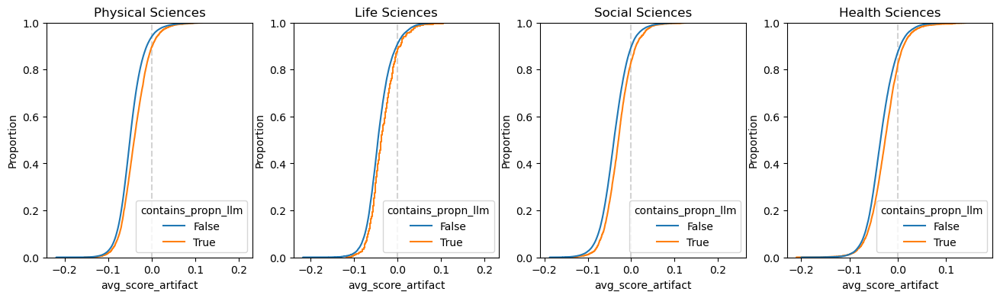

x=avg_score_lm_no_propn, hue=contains_propn_llm
Physical Sciences
U=97115571.0, p=0.000, rank_biserial=0.092 

Life Sciences
U=394123.0, p=0.000, rank_biserial=0.226 !

Social Sciences
U=9626084.0, p=0.009, rank_biserial=0.040 

Health Sciences
U=7442725.0, p=0.000, rank_biserial=0.047 



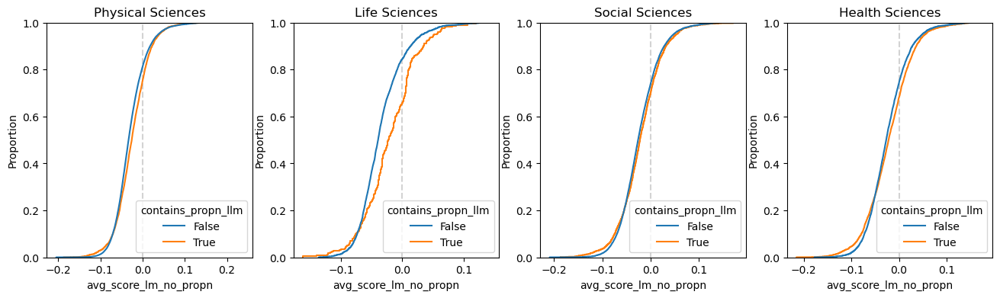

x=avg_score_human, hue=contains_propn_llm
Physical Sciences
U=224189279.0, p=0.000, rank_biserial=0.128 !

Life Sciences
U=1927373.0, p=0.353, rank_biserial=0.030 

Social Sciences
U=45885684.0, p=0.000, rank_biserial=0.127 !

Health Sciences
U=45577439.0, p=0.000, rank_biserial=0.104 !



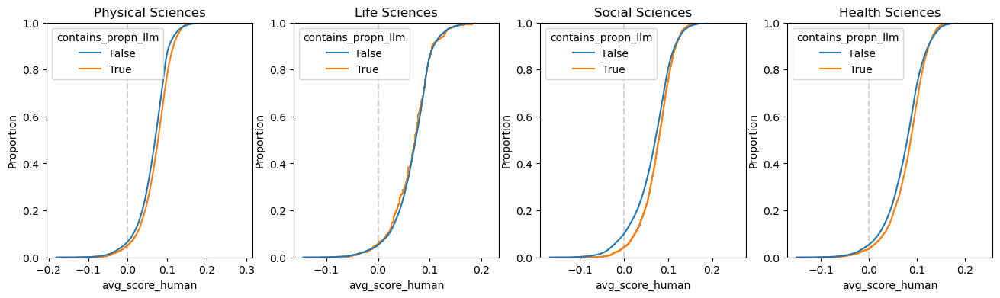

In [32]:
for x in to_plot_cols:
    if x == "avg_score_propn_llm":
        continue
    if x == "avg_score_artifact":
        plot_ecdf(x, "contains_propn_llm")#, save_as="ecdf_artifact_vs_propn_llm.pdf")
    else:
        plot_ecdf(x, "contains_propn_llm")

No significant differences detected when a paper either contains or not an LM term

x=avg_score_artifact, hue=contains_lm
Physical Sciences
U=2399262932.0, p=0.000, rank_biserial=0.100 

Life Sciences
U=26357192.0, p=0.000, rank_biserial=0.061 

Social Sciences
U=351850748.0, p=0.000, rank_biserial=0.048 

Health Sciences
U=147647304.0, p=0.000, rank_biserial=0.053 



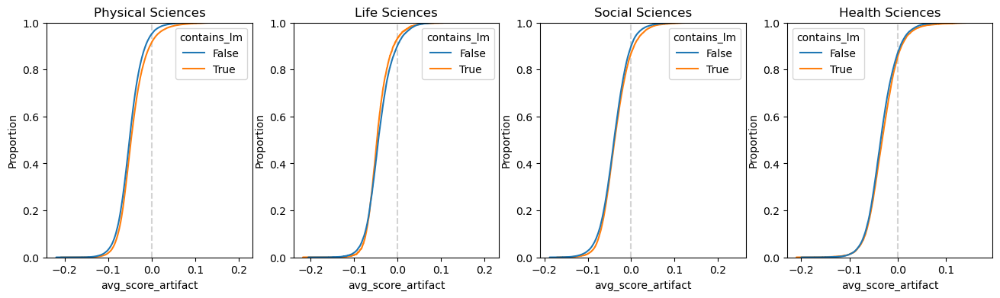

x=avg_score_human, hue=contains_lm
Physical Sciences
U=1515958963.0, p=0.000, rank_biserial=0.021 

Life Sciences
U=14850243.0, p=0.000, rank_biserial=0.061 

Social Sciences
U=197437802.5, p=0.000, rank_biserial=0.082 

Health Sciences
U=86188958.0, p=0.012, rank_biserial=0.019 



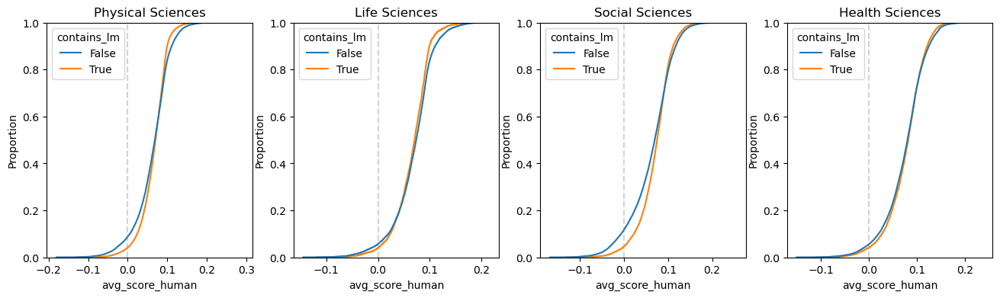

In [33]:
for x in to_plot_cols:
    if x in ("avg_score_propn_llm", "avg_score_lm_no_propn"):
        continue
    plot_ecdf(x, "contains_lm")

When average scores are split by the fact that at least one artifact term is in the same abstract, something happens. This could also be caused by the sparse number of abstracts that do not contain any artifact_mentions. In general it looks like if artifact terms are not included, other terms are treated in a more human-like manner.

In [34]:
docs.groupby("domain", observed=True)["contains_artifact"].value_counts(normalize=True).unstack("domain")

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
contains_artifact,,,,
False,0.026039,0.024032,0.019739,0.017517
True,0.973961,0.975968,0.980261,0.982483


In [35]:
docs.groupby("domain", observed=True)["contains_artifact"].value_counts().unstack("domain")

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
contains_artifact,,,,
False,1139,460,3048,1171
True,42603,18681,151366,65680


In [38]:
docs[docs["contains_propn_llm"]].groupby("domain", observed=True)["contains_artifact"].value_counts().unstack("domain")

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
contains_artifact,,,,
False,332,20,217,99
True,4718,377,5508,2845


Trying to understand why there is such a big difference in the product name term scores if the same abstracts contains an artifact term or not, as the presence or absence of an artifact terms should not directly affect the product name term score.

In [46]:
docs[docs["contains_propn_llm"]].groupby(["domain", "contains_artifact"], observed=True)["avg_score_propn_llm"].mean().unstack("domain")

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
contains_artifact,,,,
False,0.013264,0.018091,-0.005026,0.008685
True,-0.003500,-0.003453,-0.012732,-0.010702


In [81]:
docs[docs["contains_propn_llm"]].groupby(["domain", "contains_artifact"], observed=True)["num_nonhuman_sents"].mean().unstack("domain")

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
contains_artifact,,,,
False,6.614458,6.30000,7.304147,6.626263
True,13.206019,12.67374,11.973130,11.921265


In [67]:
to_inspect_ids_no_art = docs[(docs["contains_propn_llm"]) & (~docs["contains_artifact"])]["id"]
(df_dedupl[(df_dedupl["id"].isin(to_inspect_ids_no_art)) & (df_dedupl["entity_type"] == "lm")]
    .groupby(["domain"], observed=True)["entity_lower"].value_counts()[lambda x: x > 10].unstack("domain"))

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
entity_lower,,,,
chatgpt,883.0,37.0,423.0,227.0
llms,383.0,35.0,473.0,129.0
llm,182.0,NaN,131.0,77.0
gpt,160.0,12.0,98.0,21.0
gemini,150.0,NaN,61.0,34.0
large language models,141.0,11.0,157.0,65.0
claude,108.0,NaN,51.0,22.0
chatbots,79.0,NaN,23.0,17.0
large language model,33.0,NaN,22.0,14.0


In [91]:
(df_dedupl[(df_dedupl["id"].isin(to_inspect_ids_no_art)) & (df_dedupl["entity_type"] != "human")]
    .groupby(["id", "domain"], observed=True)["entity_lower"].nunique().unstack("domain").mean())

domain
Health Sciences      2.780120
Life Sciences        3.300000
Physical Sciences    3.608295
Social Sciences      3.232323
dtype: float64

In [92]:
(df_dedupl[(df_dedupl["id"].isin(to_inspect_ids_art)) & (df_dedupl["entity_type"] != "human")]
    .groupby(["id", "domain"], observed=True)["entity_lower"].nunique().unstack("domain").mean())

domain
Health Sciences      5.403349
Life Sciences        6.387268
Physical Sciences    6.206064
Social Sciences      5.668893
dtype: float64

In [93]:
(df_dedupl[(df_dedupl["id"].isin(to_inspect_ids_no_art)) & (df_dedupl["entity_type_updated"] == "propn_llm")]["humanlike"].mean())

0.5966135458167331

In [94]:
(df_dedupl[(df_dedupl["id"].isin(to_inspect_ids_art)) & (df_dedupl["entity_type_updated"] == "propn_llm")]["humanlike"].mean())

0.4401794348339959

In [68]:
for row in (df_dedupl[(df_dedupl["id"].isin(to_inspect_ids_no_art)) & (df_dedupl["entity_type_updated"] == "propn_llm")  & (df_dedupl["score"] > 0)]
    .groupby(["domain"], observed=True).sample(5, random_state=123).itertuples()):
    print(row.score)
    print(row.sentence)
    print()

0.0965680994372532
Results showed that Claude outperformed both ChatGPT and Gemini overall, particularly excelling in Spanish and Urdu translations, while Gemini led in Arabic.

0.0199589142946157
Domain-specific analysis revealed Gemini's consistently high agreement across all six COBIDAS sections (experimental design: 0.915, statistical modeling: 0.880), while ChatGPT and Claude showed weaker, more variable performance.

0.0447538271796831
87.5% of the answers provided by ChatGPT-4 (21 of 24 answers) were considered superior to the answers provided by ChatGPT-3.5 for the same questions.

0.0760985300798364
Likert scores for Claude 3 Opus (mean: 4.7) and ChatGPT 4 (mean: 4.5) showed no significant differ ence (p>0.05).

0.0044771292338867
ChatGPT and Claude achieved accuracy levels comparable with traditional self-reported dietary assessment methods but without associated user burden, suggesting potential utility as dietary monitoring tools.

0.0297649016972319
While some of the varia

In [69]:
to_inspect_ids_art = docs[(docs["contains_propn_llm"]) & (docs["contains_artifact"])]["id"]
df_dedupl[(df_dedupl["id"].isin(to_inspect_ids_art)) & (df_dedupl["entity_type"] == "artifact")].groupby(["domain"], observed=True)["entity_lower"].value_counts()[lambda x: x > 10].unstack("domain")

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
entity_lower,,,,
ai,14973,868,12147,9542
artificial intelligence,3126,134,2143,1722
models,2520,340,4141,1404
model,1960,289,3265,1334
technology,1508,50,1362,1086
applications,1120,58,1181,492
systems,972,177,1916,1069
approach,964,113,1645,806
application,867,67,858,426


In [70]:
for row in (df_dedupl[(df_dedupl["id"].isin(to_inspect_ids_art)) & (df_dedupl["entity_type_updated"] == "propn_llm")  & (df_dedupl["score"] < 0)]
    .groupby(["domain"], observed=True).sample(5, random_state=123).itertuples()):
    print(row.score)
    print(row.sentence)
    print()

-0.0226476347194669
Therefore, this study focused on understanding students' real-life experiences and thoughts, with the aim of uncovering the multiple impacts of ChatGPT on communication, research, and learning in an academic setting among postgraduate students at a Graduate Business School in a Public University in Malaysia.

-0.0013511277125446
This comprehensive paper investigates the multifaceted role of ChatGPT, an AI-powered language model, in higher educational research.

-0.0425262060731486
ChatGPT, a large language model developed by OpenAI, has shown potential in diverse applications, including medicine.

-0.0418481650773916
The objective is to provide a comprehensive review of the impact of ChatGPT AI on businesses, its potential benefits, and challenges for businesses looking to adopt this technology.

-6.308796645381738e-05
CONCLUSIONS ChatGPT provides medical information of comparable quality to available static internet information.

-0.0984827934372854
Themes were ide

x=avg_score_lm_no_propn, hue=contains_artifact
Physical Sciences
U=65786438.0, p=0.000, rank_biserial=0.152 !

Life Sciences
U=448749.0, p=0.394, rank_biserial=0.032 

Social Sciences
U=4898070.0, p=0.000, rank_biserial=0.176 !

Health Sciences
U=2144222.0, p=0.000, rank_biserial=0.212 !



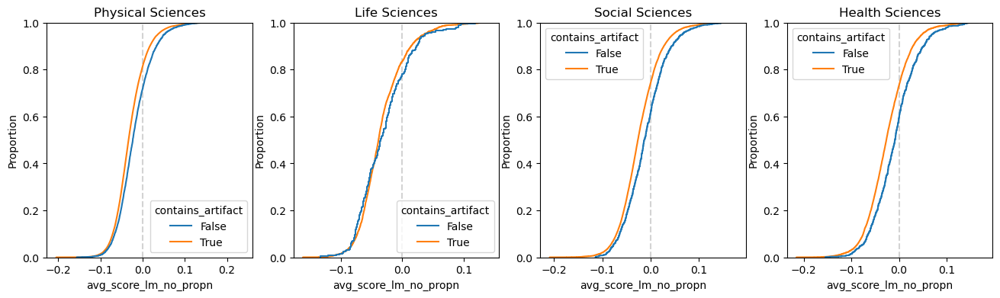

x=avg_score_propn_llm, hue=contains_artifact
Physical Sciences
U=514924.0, p=0.001, rank_biserial=0.138 !

Life Sciences
U=2485.0, p=0.010, rank_biserial=0.341 !!

Social Sciences
U=101930.0, p=0.000, rank_biserial=0.276 !

Health Sciences
U=581762.0, p=0.000, rank_biserial=0.257 !



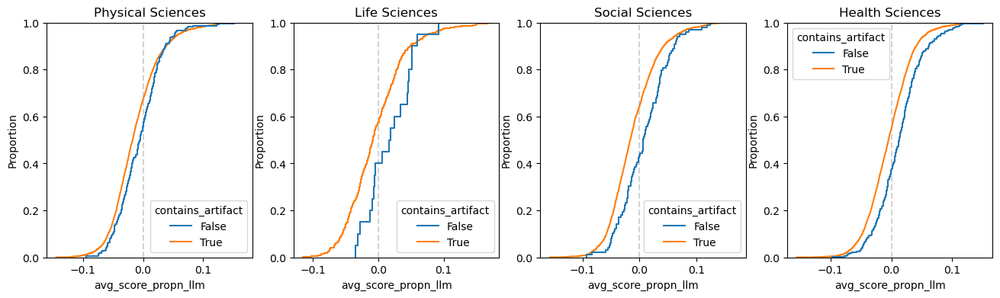

x=avg_score_human, hue=contains_artifact
Physical Sciences
U=138343610.0, p=0.000, rank_biserial=0.079 

Life Sciences
U=2456656.0, p=0.301, rank_biserial=0.030 

Social Sciences
U=19088984.0, p=0.000, rank_biserial=0.166 !

Health Sciences
U=10621432.0, p=0.000, rank_biserial=0.100 !



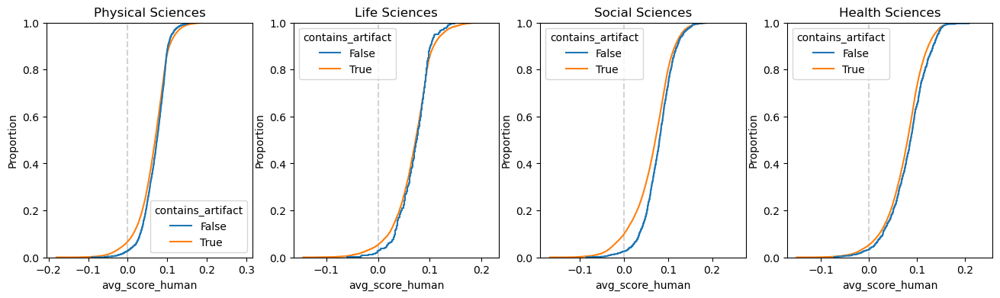

In [36]:
for x in to_plot_cols:
    if x == "avg_score_artifact":
        continue
    plot_ecdf(x, "contains_artifact")

No significant differences detected when scores come from pre- or post-ChatGPT eras 

x=avg_score_artifact, hue=post_chatgpt
Physical Sciences
U=1946139629.0, p=0.344, rank_biserial=0.003 

Life Sciences
U=24357575.0, p=0.000, rank_biserial=0.166 !

Social Sciences
U=294538815.0, p=0.000, rank_biserial=0.048 

Health Sciences
U=144685259.5, p=0.000, rank_biserial=0.029 



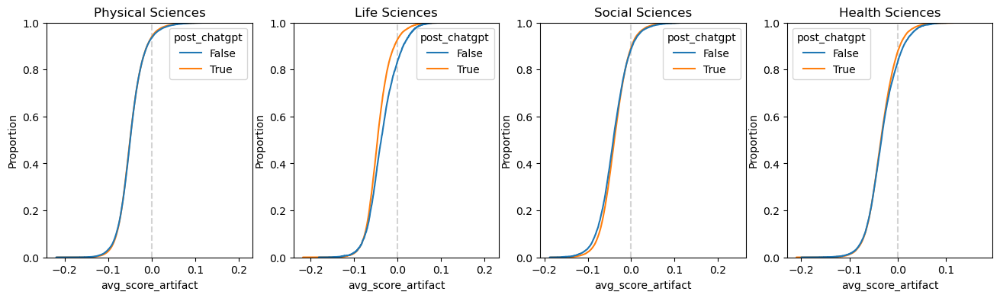

x=avg_score_lm_no_propn, hue=post_chatgpt
Physical Sciences
U=165195415.0, p=0.131, rank_biserial=0.011 

Life Sciences
U=440379.0, p=0.106, rank_biserial=0.060 

Social Sciences
U=5983965.0, p=0.000, rank_biserial=0.072 

Health Sciences
U=972462.0, p=0.269, rank_biserial=0.040 



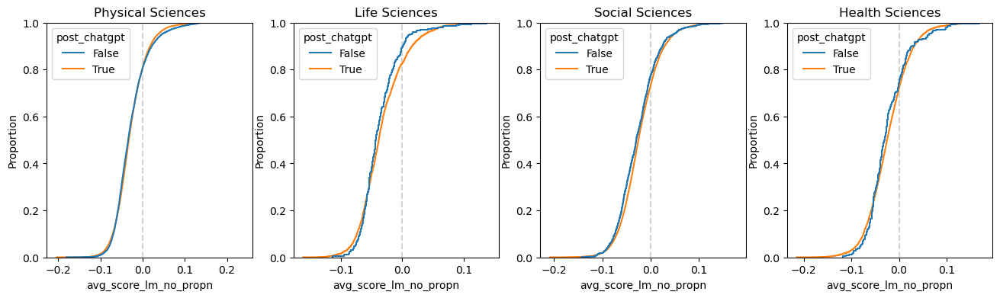

x=avg_score_human, hue=post_chatgpt
Physical Sciences
U=1033503881.0, p=0.000, rank_biserial=0.016 

Life Sciences
U=13604908.5, p=0.207, rank_biserial=0.016 

Social Sciences
U=161482863.5, p=0.167, rank_biserial=0.010 

Health Sciences
U=79007290.0, p=0.000, rank_biserial=0.034 



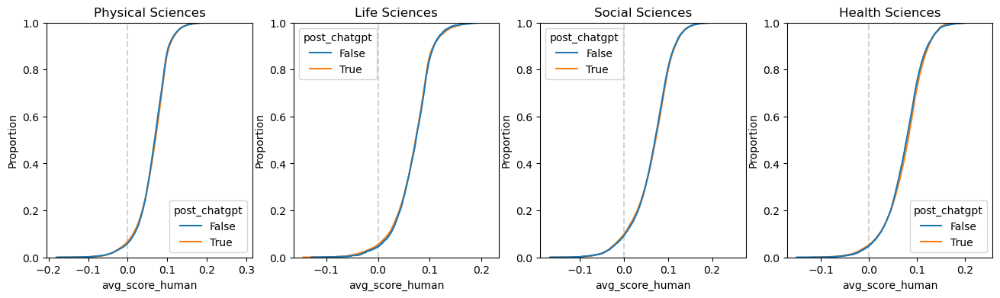

In [37]:
for x in to_plot_cols:
    if x == "avg_score_propn_llm":
        continue
    plot_ecdf(x, "post_chatgpt")

In [127]:
docs.columns

Index(['id', 'year', 'domain', 'contains_artifact', 'contains_lm',
       'contains_propn_llm', 'contains_human', 'num_artifact', 'num_lm',
       'num_propn_llm', 'num_human', 'num_sents', 'num_unique_entities',
       'avg_score', 'avg_score_artifact', 'avg_score_lm',
       'avg_score_lm_no_propn', 'avg_score_propn_llm', 'avg_score_human',
       'post_chatgpt', 'paper_type', 'num_nonhuman_sents', 'num_unique_sents'],
      dtype='object')

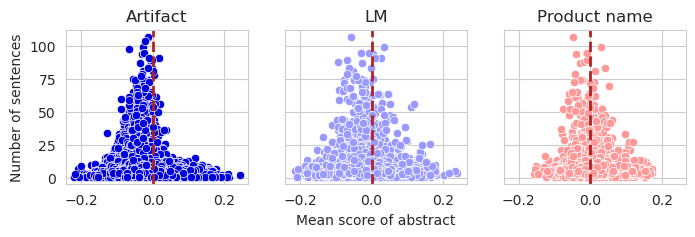

In [144]:
pick_cols = "avg_score_artifact avg_score_lm_no_propn avg_score_propn_llm".split()
with sns.axes_style("whitegrid"):
    fig, axes = plt.subplots(1, len(pick_cols), figsize=(8,2), sharey=True, sharex=True)
    axes = axes.flatten()
    for i, (ax, score_col) in enumerate(zip(axes, pick_cols)):
        sns.scatterplot(docs, x=score_col, y="num_unique_sents", ax=ax, color=et_palette[i])
        ax.axvline(0, color="firebrick", linestyle="--", linewidth=2)
        if i == 1:
            ax.set_xlabel("Mean score of abstract")
        else:
            ax.set_xlabel("")
        ax.set_ylabel("Number of sentences")
        ax.set_title(col_to_label[score_col])

In [121]:
df_dedupl[df_dedupl["entity_type"] != "human"].groupby(["id", "domain"], observed=True)["sentence"].nunique().unstack("domain").mean()

domain
Health Sciences      5.082748
Life Sciences        4.439404
Physical Sciences    4.999293
Social Sciences      4.852263
dtype: float64

In [120]:
df_dedupl[df_dedupl["entity_type"] != "human"].groupby(["id", "domain"], observed=True)["sentence"].size().unstack("domain").mean()

domain
Health Sciences      8.059935
Life Sciences        6.804932
Physical Sciences    8.334176
Social Sciences      7.934803
dtype: float64

A quick check that most abstracts do not include suspiciosly high number of sentences, as the above plot cloud suggest.

In [122]:
num_unique_sents = df_dedupl[df_dedupl["entity_type"] != "human"].groupby("id", observed=True)["sentence"].nunique().reset_index()

<Axes: ylabel='Frequency'>

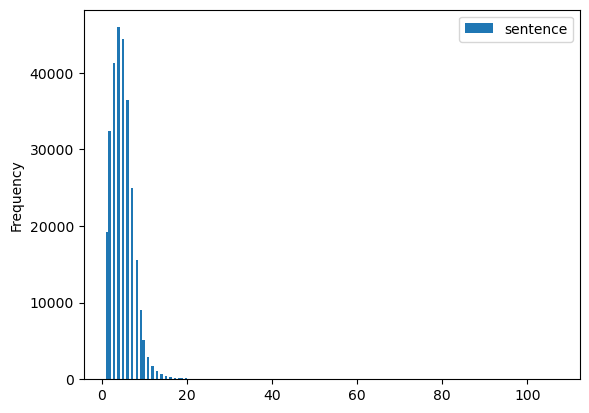

In [141]:
num_unique_sents.plot.hist(bins=200)

In [125]:
docs = docs.merge(num_unique_sents, on="id")

In [126]:
docs = docs.rename(columns={"sentence": "num_unique_sents"})

Does the number of sentences correlate with higher scores? This doesn't quite to seem the case, but rather many different entities leading to a flatter average, possibly signaling that different terms are used or the same terms are used differently within the same paper.

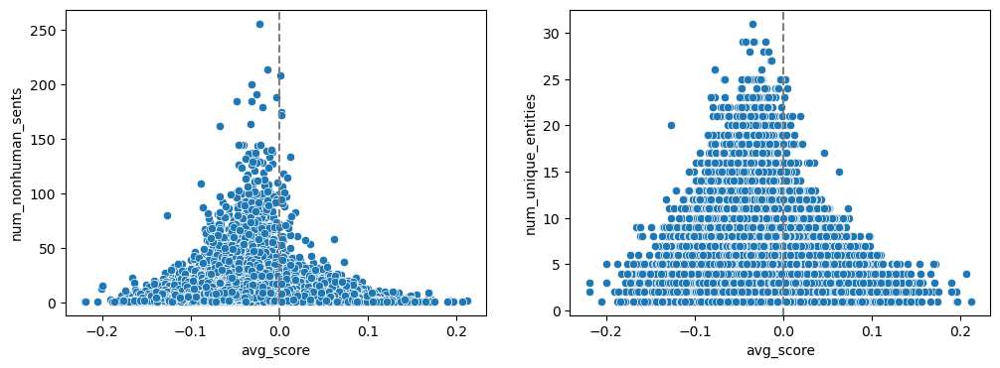

In [118]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes = axes.flatten()
for ax in axes:
    ax.axvline(0, color="gray", linestyle="--")
 
sns.scatterplot(docs, x="avg_score", y="num_nonhuman_sents", ax=axes[0])
sns.scatterplot(docs, x="avg_score", y="num_unique_entities", ax=axes[1])

plt.show()

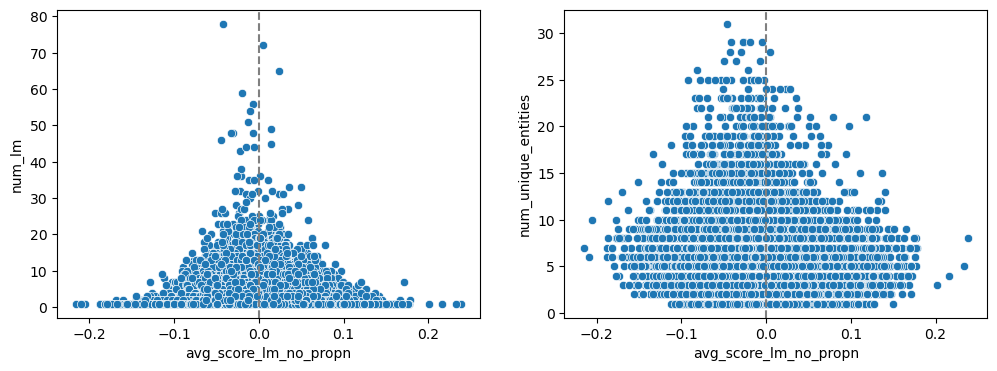

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes = axes.flatten()
for ax in axes:
    ax.axvline(0, color="gray", linestyle="--")
 
sns.scatterplot(docs, x="avg_score_lm_no_propn", y="num_lm", ax=axes[0])
sns.scatterplot(docs, x="avg_score_lm_no_propn", y="num_unique_entities", ax=axes[1])

plt.show()

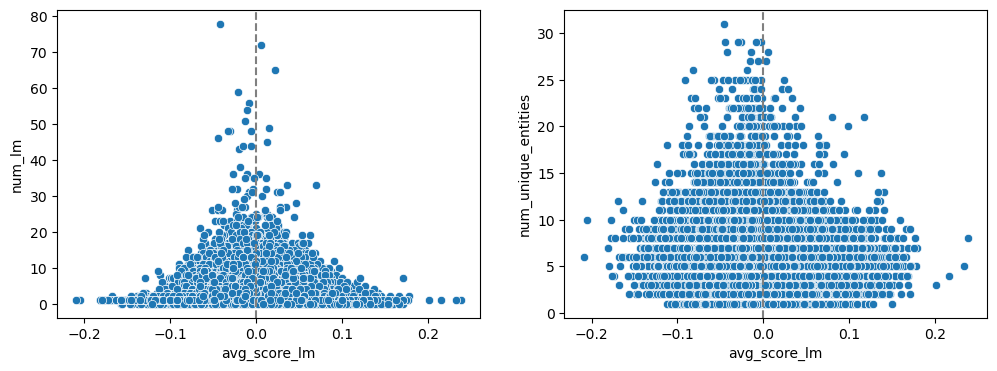

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes = axes.flatten()
for ax in axes:
    ax.axvline(0, color="gray", linestyle="--")
 
sns.scatterplot(docs, x="avg_score_lm", y="num_lm", ax=axes[0])
sns.scatterplot(docs, x="avg_score_lm", y="num_unique_entities", ax=axes[1])

plt.show()

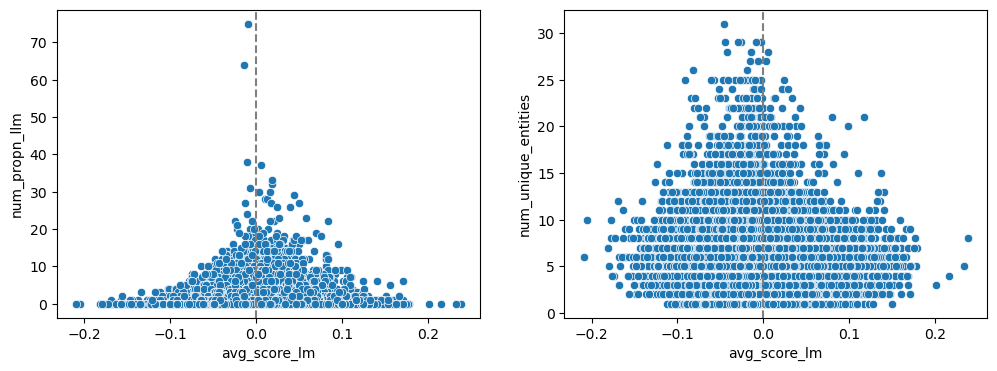

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes = axes.flatten()
for ax in axes:
    ax.axvline(0, color="gray", linestyle="--")
 
sns.scatterplot(docs, x="avg_score_lm", y="num_propn_llm", ax=axes[0])
sns.scatterplot(docs, x="avg_score_lm", y="num_unique_entities", ax=axes[1])

plt.show()

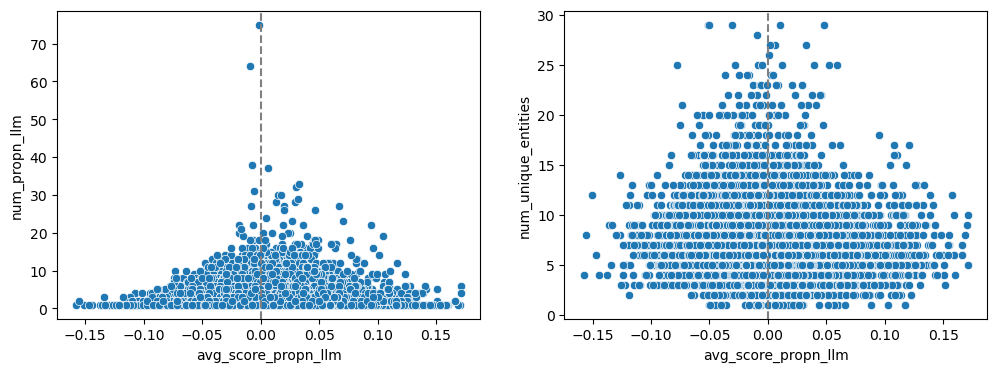

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes = axes.flatten()
for ax in axes:
    ax.axvline(0, color="gray", linestyle="--")
 
sns.scatterplot(docs, x="avg_score_propn_llm", y="num_propn_llm", ax=axes[0])
sns.scatterplot(docs, x="avg_score_propn_llm", y="num_unique_entities", ax=axes[1])

plt.show()

The following plots are pretty interesting: they show that if the author(s) of a paper are using proper noun terms, they are more likely to anthropomorphize artifact terms as well, which was also shown in the ecdf plots earlier without the time aspect.

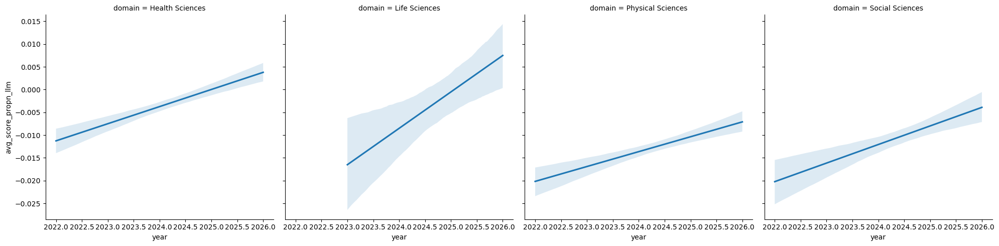

In [79]:
# Average scores for proper noun LLM terms
ax = sns.lmplot(docs, y="avg_score_propn_llm", x="year", scatter=False, col="domain")

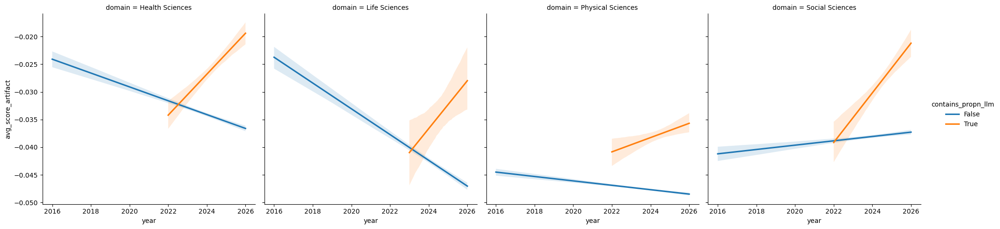

In [80]:
# Average scores for artifact terms, hue showing inclusion of proper noun LLM terms
ax = sns.lmplot(docs, y="avg_score_artifact", x="year", hue="contains_propn_llm", scatter=False, col="domain")

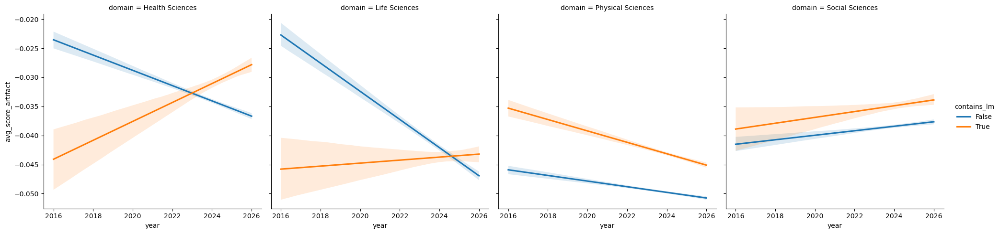

In [81]:
# Average scores for artifact terms, hue showing inclusion of any LM terms
ax = sns.lmplot(docs, y="avg_score_artifact", x="year", hue="contains_lm", scatter=False, col="domain")

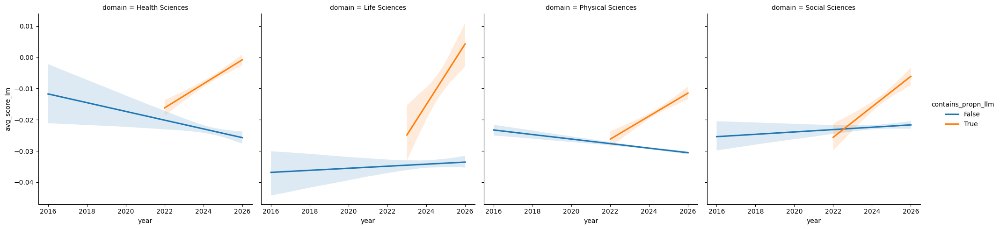

In [82]:
# Average scores for LM terms, hue showing inclusion of proper noun LLM terms
ax = sns.lmplot(docs, y="avg_score_lm", x="year", hue="contains_propn_llm", scatter=False, col="domain")

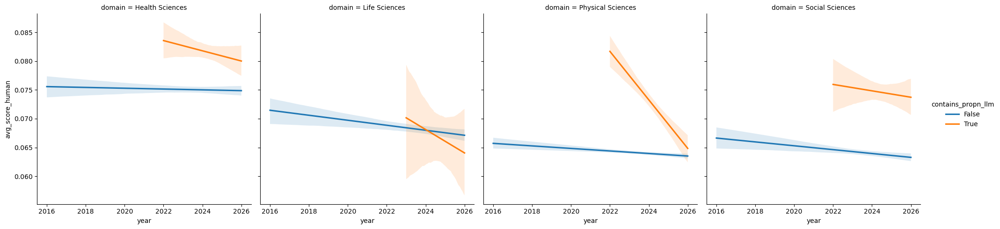

In [83]:
# Average scores for human terms, hue showing inclusion of proper noun LLM terms
ax = sns.lmplot(docs, y="avg_score_human", x="year", hue="contains_propn_llm", scatter=False, col="domain")

In [47]:
conditions = [
    docs["contains_propn_llm"],
    docs["contains_lm"],
    docs["contains_artifact"]
]

choices = [
    "propn",
    "lm",
    "artifact"
]

docs["paper_type"] = np.select(conditions, choices, default="human_only")
docs["paper_type"].value_counts()

paper_type
artifact      195051
lm             74016
propn          14116
human_only       965
Name: count, dtype: int64

In [48]:
docs["paper_type"].value_counts(normalize=True)

paper_type
artifact      0.686442
lm            0.260484
propn         0.049678
human_only    0.003396
Name: proportion, dtype: float64

In [53]:
docs = docs.drop(columns="index")

Verifying the finding in AnthroScore that LM papers anthropomorphize *also artifacts* more than non-LM papers.

<Axes: xlabel='paper_type'>

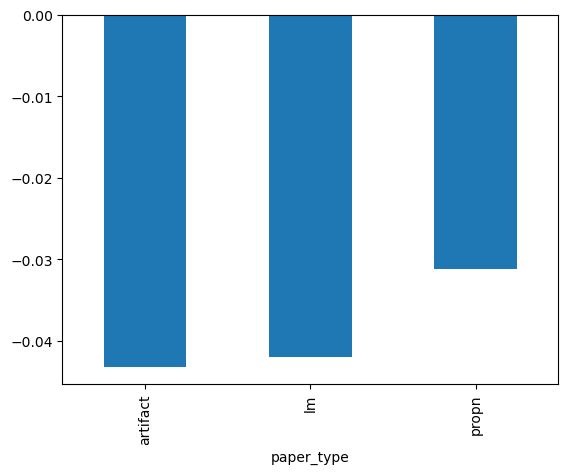

In [113]:
docs[docs["paper_type"] != "human_only"].groupby("paper_type", observed=True)["avg_score_artifact"].mean().plot.bar()

In [26]:
sorted_index = (docs[docs["paper_type"] != "human_only"]
    .groupby(["domain", "paper_type"], observed=True)["avg_score_artifact"]
    .mean().unstack("domain").mean().sort_values().index)

Is the artifact score affected by the domain and paper type?

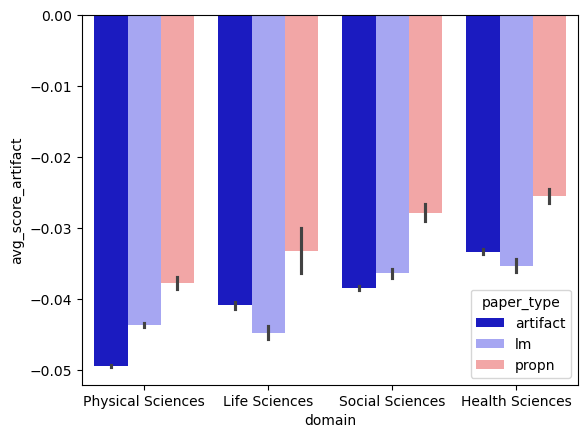

In [44]:
ax = sns.barplot(docs_no_human, x="domain", y="avg_score_artifact", hue="paper_type", hue_order=pt_order, order=hue_order, palette=et_palette[:3])

What would be the correct statistical test(s) here to determine if
- artifact scores are significantly different between domains
- artifact and LM scores are significantly different within domains?

This aggregation is not overlapping; each paper belongs to only one group. But if I was to use the `contains_cols` instead, then I would have cases where one paper belongs to multiple categories, making some of the comparisons paired. And it should also be noted that proper noun LLM and LM papers might as well include artifact terms. So it might actually not be meaningful to compare the paper types, but rather the average scores for each entity type.

In [117]:
docs_no_human.columns

Index(['id', 'year', 'domain', 'contains_artifact', 'contains_lm',
       'contains_propn_llm', 'num_artifact', 'num_lm', 'num_propn_llm',
       'num_human', 'num_sents', 'num_unique_entities', 'avg_score',
       'avg_score_artifact', 'avg_score_lm', 'avg_score_lm_no_propn',
       'avg_score_propn_llm', 'avg_score_human', 'post_chatgpt', 'paper_type',
       'num_nonhuman_sents', 'contains'],
      dtype='object')

In [25]:
docs_no_human = docs_no_human.drop(columns="contains_human")
contains_cols_no_human = [col for col in docs_no_human.columns if col.startswith("contains_")]
docs_no_human["contains"] = docs_no_human[contains_cols_no_human].apply(
    lambda col: np.where(col, col.name.replace("contains_", "") + "_", ""),
).sum(axis=1).str.rstrip("_").replace("", "none")

In [26]:
pd.crosstab(docs_no_human["contains"], docs_no_human["domain"], margins=True)

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences,All
contains,,,,,
artifact,33218,14917,95648,51268,195051
artifact_lm,4667,3387,50210,11567,69831
artifact_lm_propn_llm,4718,377,5508,2845,13448
lm,462,236,2668,819,4185
lm_propn_llm,332,20,217,99,668
All,43397,18937,154251,66598,283183


Given the new grouping above, one can calculate different types of statistics.
- Papers that only contain a single type can be compared as independent samples, using the column `avg_score`, as no other entity type is affecting the score.
- Papers that contain multiple entities can be compared pairwise, using two (or three) scores from the same paper. The question then would be if there are within-paper differences in how artifacts or LMs are portrayed (or LMs vs LLMs, or all three compared).

In [47]:
print(13448/283183)
print(69831/283183)

0.04748872637128641
0.24659319238796115


In [27]:
artifact_lm = docs_no_human[docs_no_human["contains"] == "artifact_lm"]

In [28]:
len(artifact_lm)

69831

In [53]:
artifact_lm.domain.value_counts()

domain
Physical Sciences    50210
Social Sciences      11567
Health Sciences       4667
Life Sciences         3387
Name: count, dtype: int64

In [54]:
res = stats.wilcoxon(artifact_lm["avg_score_artifact"], artifact_lm["avg_score_lm"], method="approx")
print(res)
print(res.zstatistic)
n = (artifact_lm["avg_score_artifact"] != artifact_lm["avg_score_lm"]).sum()
r_rank_biserial = res.zstatistic / np.sqrt(n)
print(r_rank_biserial)

WilcoxonResult(statistic=787775961.0, pvalue=0.0)
-80.97051360037156
-0.3064098790385494


In [29]:
import numpy as np
from scipy.stats import rankdata

def rank_biserial(x, y):
    d = np.asarray(x) - np.asarray(y)
    d = d[d != 0]
    n = len(d)
    if n == 0:
        return np.nan

    ranks = rankdata(np.abs(d))
    W_pos = ranks[d > 0].sum()
    W_neg = ranks[d < 0].sum()

    # rank-biserial correlation: (W+ - W-) / total rank sum
    r = (W_pos - W_neg) / (W_pos + W_neg)
    return r

def bootstrap_rank_biserial_ci(x, y, n_boot=2000, ci=95, random_state=0):
    x = np.asarray(x)
    y = np.asarray(y)
    n = len(x)
    rng = np.random.default_rng(random_state)

    boot_rs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)  # resample pairs jointly, keeps pairing intact
        boot_rs[i] = rank_biserial(x[idx], y[idx])

    lower = np.nanpercentile(boot_rs, (100 - ci) / 2)
    upper = np.nanpercentile(boot_rs, 100 - (100 - ci) / 2)
    point = rank_biserial(x, y)
    return point, lower, upper

# Will crash
def bootstrap_rank_biserial_ci_scipy(x, y, n_boot=2000, ci=95, random_state=0):
    ci = stats.bootstrap((x, y), rank_biserial, n_resamples=n_boot, paired=True).confidence_interval
    return rank_biserial(x, y), ci.low, ci.high

In [30]:
r, ci_low, ci_high = bootstrap_rank_biserial_ci(artifact_lm["avg_score_artifact"], artifact_lm["avg_score_lm"], n_boot=2000)
print(f"r_rb = {r:.3f}, 95% CI [{ci_low:.3f}, {ci_high:.3f}]")

r_rb = -0.354, 95% CI [-0.362, -0.346]


In [93]:
def wilcoxon_with_rank_biserial(df, group_by="domain", col_x="avg_score_artifact", col_y="avg_score_lm", n_boot=2000):
    diffs = {}
    for grouped in df.groupby(group_by, observed=True):
        name, g = grouped
        sample_size = len(g)
        print(name, f"| sample size: {sample_size}")
        x = g[col_x]
        y = g[col_y]

        method = "approx" if sample_size > 50 else "exact"
        print(f"Using method '{method}'")
        res = stats.wilcoxon(x, y, method=method)
        try:
            zstat = res.zstatistic
        except AttributeError:
            zstat = None
        print(res, f"zstatistic={zstat}")
        if zstat:
            n = (x != y).sum()
            r_rank_biserial = res.zstatistic / np.sqrt(n)
            print("z-based:", r_rank_biserial)

        r, ci_low, ci_high = bootstrap_rank_biserial_ci(x, y, n_boot=n_boot)
        print(f"r_rb = {r:.3f}, 95% CI [{ci_low:.3f}, {ci_high:.3f}]")
    
        diff = x - y
        diffs[name] = diff.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
        print()
    
    diffs_df = pd.DataFrame(diffs)
    return diffs_df

Paired samples of artifact scores and LM terms. P-values alone cannot be taken as a sign of meaningful differences as the sample sizes are large, but when compared with effect size and confidence intervals, it is clear that all domains show same tendency to anthropomorphize LM terms more than artifact terms. The effect is smallest in Health Sciences, indicating that LM terms are less often scored higher than the artifact terms in the same paper than in other domains.

In [67]:
wilcoxon_with_rank_biserial(artifact_lm)

Health Sciences | sample size: 4667
Using method 'approx'
WilcoxonResult(statistic=4145260.0, pvalue=2.323468591915981e-45) zstatistic=-14.134631554053566
z-based: -0.20690243022996288
r_rb = -0.239, 95% CI [-0.271, -0.210]

Life Sciences | sample size: 3387
Using method 'approx'
WilcoxonResult(statistic=2030972.0, pvalue=4.765378837845176e-49) zstatistic=-14.720441655061414
z-based: -0.25293751176877216
r_rb = -0.292, 95% CI [-0.329, -0.254]

Physical Sciences | sample size: 50210
Using method 'approx'
WilcoxonResult(statistic=393695238.0, pvalue=0.0) zstatistic=-72.84064504780373
z-based: -0.3250713331849433
r_rb = -0.375, 95% CI [-0.385, -0.366]

Social Sciences | sample size: 11567
Using method 'approx'
WilcoxonResult(statistic=22547581.0, pvalue=1.7666820531767996e-202) zstatistic=-30.36158869473985
z-based: -0.28230211042116815
r_rb = -0.326, 95% CI [-0.346, -0.306]



,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
count,4667.000000,3387.000000,50210.000000,11567.000000
mean,-0.010116,-0.010452,-0.014151,-0.013199
std,0.047548,0.040674,0.044478,0.046635
min,-0.245538,-0.215075,-0.282525,-0.249653
10%,-0.067784,-0.059125,-0.066623,-0.068962
25%,-0.037515,-0.033298,-0.039810,-0.041094
50%,-0.008806,-0.009546,-0.013564,-0.012906
75%,0.018804,0.013884,0.011700,0.015424
90%,0.044990,0.037605,0.037832,0.043121
max,0.218488,0.203812,0.270941,0.219831


Paired samples of LM term scores and proper noun LLM scores

Here, the sample sizes range from 20 to 332, and p-values show significance. In all domains, the p-value is < 0.01 (and other than Life Sciences < 0.001), indicating that proper noun terms are consistently scored higher than LM terms. Though it should also be noted that the confidence intervals are pretty wide; however, everything still looks non-negligible.

In [94]:
lm_propn_llm = docs_no_human[docs_no_human["contains"] == "lm_propn_llm"]
wilcoxon_with_rank_biserial(lm_propn_llm, col_x="avg_score_lm", col_y="avg_score_propn_llm")

Health Sciences | sample size: 332
Using method 'approx'
WilcoxonResult(statistic=10983.0, pvalue=1.9371444020221215e-08) zstatistic=-5.6175229595023985
z-based: -0.34250641977288226
r_rb = -0.395, 95% CI [-0.523, -0.273]

Life Sciences | sample size: 20
Using method 'exact'
WilcoxonResult(statistic=25.0, pvalue=0.0065765380859375) zstatistic=None
r_rb = -0.708, 95% CI [-1.000, -0.287]

Physical Sciences | sample size: 217
Using method 'approx'
WilcoxonResult(statistic=7366.0, pvalue=0.00025313932716304296) zstatistic=-3.6590627799875746
z-based: -0.2561856368512382
r_rb = -0.295, 95% CI [-0.443, -0.138]

Social Sciences | sample size: 99
Using method 'approx'
WilcoxonResult(statistic=1194.0, pvalue=0.0009402265814712752) zstatistic=-3.3078276381009633
z-based: -0.35062902838134663
r_rb = -0.404, 95% CI [-0.610, -0.173]



,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
count,332.000000,20.000000,217.000000,99.000000
mean,-0.006715,-0.012255,-0.005270,-0.008747
std,0.024158,0.018684,0.026811,0.028653
min,-0.100588,-0.058281,-0.091028,-0.148330
10%,-0.032235,-0.029825,-0.033343,-0.040869
25%,-0.019388,-0.018016,-0.021071,-0.024041
50%,-0.004232,-0.009254,-0.006934,-0.008032
75%,0.000625,-0.005875,0.004446,0.003340
90%,0.019636,0.001309,0.030138,0.021256
max,0.084891,0.027649,0.068959,0.070849


Paired Artifact - LM - proper noun LLM for all domains

In [70]:
from scipy.stats import friedmanchisquare

In [71]:
artifact_lm_propn_llm = docs_no_human[docs_no_human["contains"] == "artifact_lm_propn_llm"]
a = artifact_lm_propn_llm["avg_score_artifact"]
b = artifact_lm_propn_llm["avg_score_lm"]
c = artifact_lm_propn_llm["avg_score_propn_llm"]

friedmanchisquare(a, b, c)

FriedmanchisquareResult(statistic=3127.824924111902, pvalue=0.0)

In [75]:
from statsmodels.stats.multitest import multipletests
pvals = []
for (x, y), (name_x, name_y) in zip(((a, b), (b, c), (a, c)),
                (("artifact", "lm"), ("lm", "propn"), ("artifact", "propn"))
               ):
    print(name_x, "vs", name_y)
    res = stats.wilcoxon(x, y)
    pvals.append(res.pvalue)
    print(res)
    print()
    
multipletests(pvals, method="holm")

artifact vs lm
WilcoxonResult(statistic=24300565.0, pvalue=0.0)

lm vs propn
WilcoxonResult(statistic=12420859.0, pvalue=7.79933509495302e-124)

artifact vs propn
WilcoxonResult(statistic=22231641.0, pvalue=0.0)



(array([ True,  True,  True]),
 array([0.00000000e+000, 7.79933509e-124, 0.00000000e+000]),
 0.016952427508441503,
 0.016666666666666666)

Multiple Wilcoxon tests domain-wise

In [109]:
def wilcoxon_multiple(df, group_by="domain", col_a="avg_score_artifact", col_b="avg_score_lm", col_c="avg_score_propn_llm"):
    pvals = []
    diffs = {}
    summary = []
    for grouped in df.groupby(group_by, observed=True):
        name, g = grouped
        sample_size = len(g)
        print(name, f"| sample size: {sample_size}")
        a = g[col_a]
        b = g[col_b]
        c = g[col_c]
        print(friedmanchisquare(a, b, c))
        print()

        for (x, y), (name_x, name_y) in zip(((a, b), (b, c), (a, c)),
                (("artifact", "lm"), ("lm", "propn"), ("artifact", "propn"))
               ):
            print(name_x, "vs", name_y)
    
            method = "approx" if sample_size > 50 else "exact"
            print(f"Using method '{method}'")
            res = stats.wilcoxon(x, y, method=method)
            print(res)
            pvals.append(res.pvalue)

            r, ci_low, ci_high = bootstrap_rank_biserial_ci(x, y)
            print(f"r_rb = {r:.3f}, 95% CI [{ci_low:.3f}, {ci_high:.3f}]")

            summary.append({
                "domain": name,
                "comparison": f"{name_x}+{name_y}",
                "sample_size": sample_size,
                "pvalue": res.pvalue,
                "effect": r,
                "ci_low": ci_low,
                "ci_high": ci_high
            })

            diff = x - y
            diffs[f"{name}_{name_x}_{name_y}"] = diff.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
            print()
        print("-"*10)

    display(pd.DataFrame(diffs))
    display(pd.DataFrame(summary).set_index(["domain", "comparison"]))
    print(pd.DataFrame(summary).set_index(["domain", "comparison"]), to_latex(float_format="%.3f"))

    return multipletests(pvals, method="holm")

In [110]:
wilcoxon_multiple(artifact_lm_propn_llm)

Health Sciences | sample size: 4718
FriedmanchisquareResult(statistic=1180.038747784996, pvalue=5.725872885904485e-257)

artifact vs lm
Using method 'approx'
WilcoxonResult(statistic=3045558.0, pvalue=7.800314347409826e-160)
r_rb = -0.453, 95% CI [-0.481, -0.426]

lm vs propn
Using method 'approx'
WilcoxonResult(statistic=1155078.0, pvalue=1.1268962357400337e-74)
r_rb = -0.401, 95% CI [-0.440, -0.359]

artifact vs propn
Using method 'approx'
WilcoxonResult(statistic=2688270.0, pvalue=9.859693247603995e-208)
r_rb = -0.517, 95% CI [-0.544, -0.492]

----------
Life Sciences | sample size: 377
FriedmanchisquareResult(statistic=140.25251076040163, pvalue=3.5039205636102104e-31)

artifact vs lm
Using method 'approx'
WilcoxonResult(statistic=15110.0, pvalue=3.328871742460697e-22)
r_rb = -0.576, 95% CI [-0.664, -0.485]

lm vs propn
Using method 'approx'
WilcoxonResult(statistic=12587.0, pvalue=0.00011157459762952826)
r_rb = -0.275, 95% CI [-0.402, -0.133]

artifact vs propn
Using method 'appro

,Health Sciences_artifact_lm,Health Sciences_lm_propn,Health Sciences_artifact_propn,Life Sciences_artifact_lm,Life Sciences_lm_propn,Life Sciences_artifact_propn,Physical Sciences_artifact_lm,Physical Sciences_lm_propn,Physical Sciences_artifact_propn,Social Sciences_artifact_lm,Social Sciences_lm_propn,Social Sciences_artifact_propn
count,4718.000000,4718.000000,4718.000000,377.000000,377.000000,377.000000,5508.000000,5508.000000,5508.000000,2845.000000,2845.000000,2845.000000
mean,-0.017445,-0.004566,-0.022011,-0.024864,-0.004937,-0.029801,-0.020020,-0.005020,-0.025040,-0.014016,-0.003193,-0.017209
std,0.042947,0.019667,0.045587,0.046473,0.025008,0.049559,0.042543,0.025667,0.047869,0.044468,0.023619,0.048927
min,-0.212445,-0.119874,-0.224633,-0.208199,-0.146059,-0.236197,-0.235597,-0.158914,-0.242481,-0.244930,-0.157220,-0.244928
10%,-0.070700,-0.028121,-0.079217,-0.075251,-0.034101,-0.086831,-0.072397,-0.037134,-0.085059,-0.067977,-0.030704,-0.076633
25%,-0.044126,-0.011695,-0.050223,-0.049418,-0.016628,-0.057674,-0.045414,-0.016428,-0.053209,-0.040287,-0.007620,-0.045033
50%,-0.016696,0.000000,-0.020668,-0.021780,0.000000,-0.028387,-0.019672,0.000000,-0.022848,-0.013278,0.000000,-0.014868
75%,0.008779,0.000000,0.007013,0.001972,0.004578,0.001478,0.005630,0.002399,0.005134,0.014197,0.000000,0.014347
90%,0.035177,0.012511,0.033916,0.028639,0.020435,0.028952,0.030816,0.023582,0.031624,0.039119,0.019669,0.039724
max,0.188662,0.117121,0.188662,0.123188,0.084091,0.123188,0.236093,0.103345,0.215712,0.152669,0.120778,0.185529


sample_size         pvalue    effect  \
domain            comparison                                             
Health Sciences   artifact+lm            4718  7.800314e-160 -0.452834   
                  lm+propn               4718   1.126896e-74 -0.400656   
                  artifact+propn         4718  9.859693e-208 -0.517025   
Life Sciences     artifact+lm             377   3.328872e-22 -0.575878   
                  lm+propn                377   1.115746e-04 -0.274859   
                  artifact+propn          377   5.939213e-26 -0.626121   
Physical Sciences artifact+lm            5508  6.580138e-244 -0.518905   
                  lm+propn               5508   1.536005e-47 -0.269765   
                  artifact+propn         5508  9.182372e-281 -0.557055   
Social Sciences   artifact+lm            2845   1.476226e-59 -0.352307   
                  lm+propn               2845   3.101201e-13 -0.215167   
                  artifact+propn         2845   1.141961e-68 -0.379095   

                                    ci_low   ci_high  
domain            comparison                          
Health Sciences   artifact+lm    -0.481272 -0.425935  
                  lm+propn       -0.439958 -0.358819  
                  artifact+propn -0.543568 -0.491577  
Life Sciences     artifact+lm    -0.664350 -0.485154  
                  lm+propn       -0.402045 -0.133155  
                  artifact+propn -0.709125 -0.540210  
Physical Sciences artifact+lm    -0.542633 -0.495305  
                  lm+propn       -0.306014 -0.233300  
                  artifact+propn -0.580280 -0.533842  
Social Sciences   artifact+lm    -0.389183 -0.312683  
                  lm+propn       -0.271542 -0.159918  
                  artifact+propn -0.415585 -0.340294

(array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True]),
 array([7.02028291e-159, 9.01516989e-074, 9.85969325e-207, 9.98661523e-022,
        1.11574598e-004, 2.37568524e-025, 7.23815146e-243, 7.68002449e-047,
        1.10188460e-279, 8.85735898e-059, 6.20240258e-013, 7.99372708e-068]),
 0.004265318777560645,
 0.004166666666666667)

Some observations from the above table:
- all entity comparisons are significant and the effects are clear
- in all domains, the differences between LM and proper noun LLMs are not as large as the differences between artifacts and either LM term type
- in Social and Health Sciences, the differences between artifact vs (any) LM terms and LM vs proper noun LLM are not as big as in Life or Physical Sciences
- this is not sufficient for domain-wise comparison though

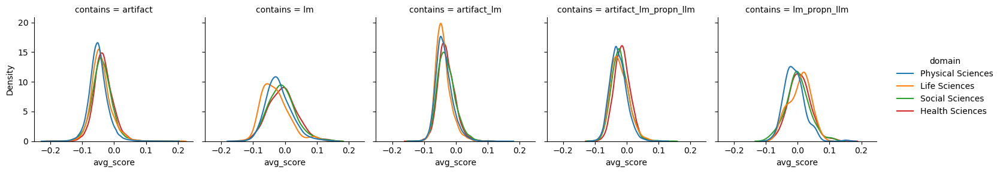

In [121]:
sns.displot(docs_no_human, x="avg_score", hue="domain", col="contains", kind="kde", hue_order=hue_order, common_norm=False, col_wrap=5, height=3)

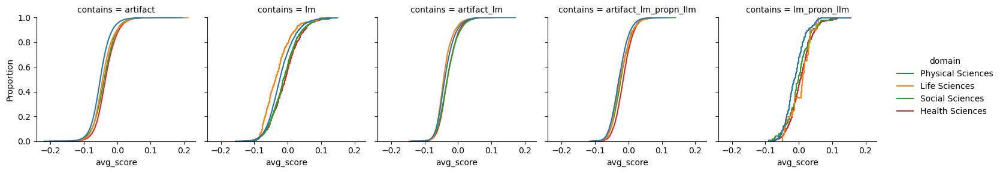

In [122]:
sns.displot(docs_no_human, x="avg_score", hue="domain", col="contains", kind="ecdf", hue_order=hue_order, col_wrap=5, height=3)

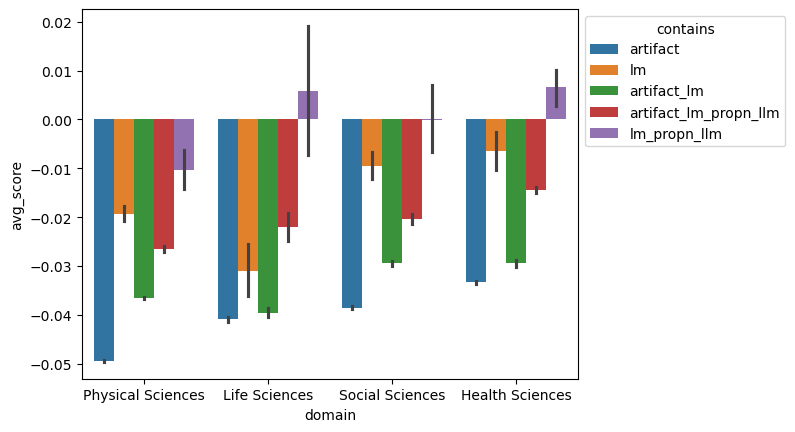

In [123]:
ax = sns.barplot(docs_no_human, x="domain", y="avg_score", hue="contains", order=hue_order)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

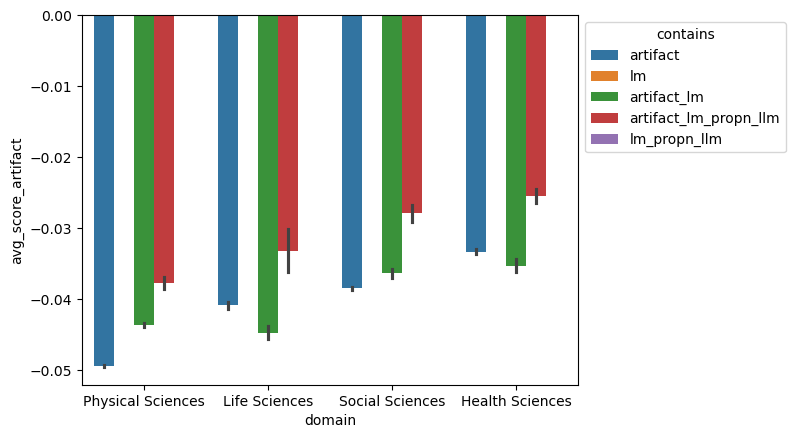

In [124]:
ax = sns.barplot(docs_no_human, x="domain", y="avg_score_artifact", hue="contains", order=hue_order)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

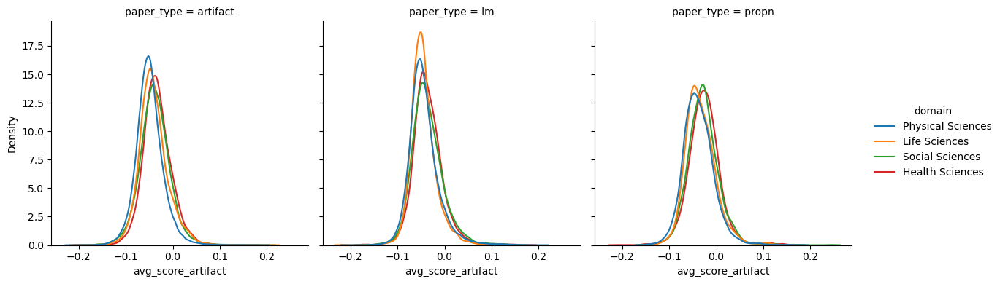

In [51]:
sns.displot(docs_no_human, x="avg_score_artifact", hue="domain", col="paper_type", kind="kde", hue_order=hue_order, common_norm=False, height=4)

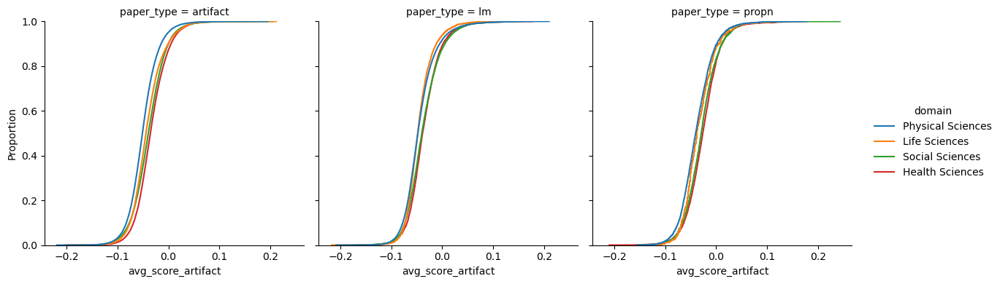

In [54]:
sns.displot(docs_no_human, x="avg_score_artifact", hue="domain", col="paper_type", kind="ecdf", hue_order=hue_order, height=4)

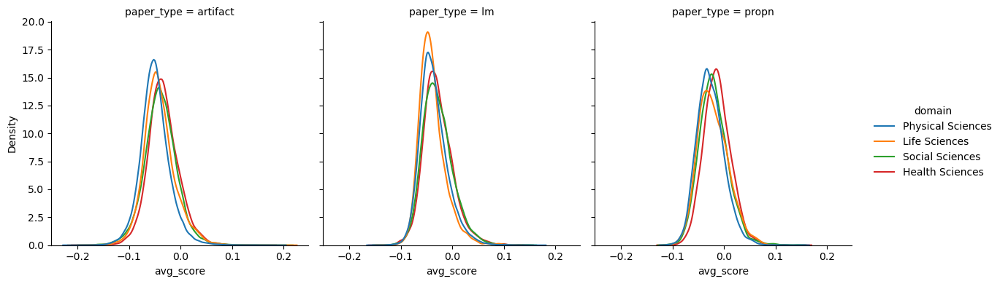

In [52]:
sns.displot(docs_no_human, x="avg_score", hue="domain", col="paper_type", kind="kde", hue_order=hue_order, common_norm=False, height=4)

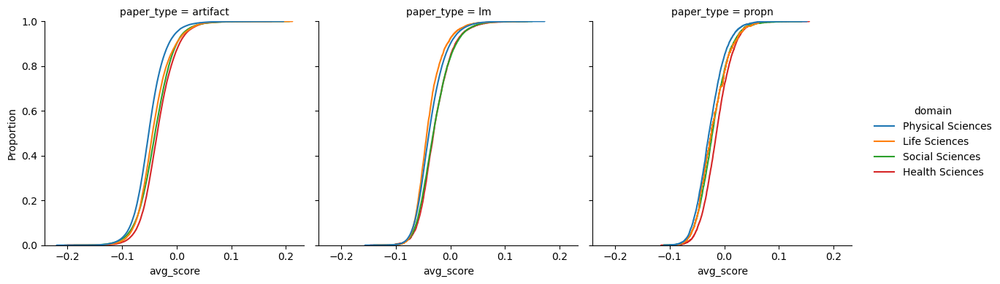

In [55]:
sns.displot(docs_no_human, x="avg_score", hue="domain", col="paper_type", kind="ecdf", hue_order=hue_order, height=4)

In [71]:
pt_grouped = docs_no_human.groupby(["domain", "paper_type"], observed=True)["avg_score_artifact"]
pt_groups = {name: g.dropna() for name, g in pt_grouped}

('Health Sciences', 'artifact')
33218 33218 0.0043435674539868

('Health Sciences', 'lm')
4667 4667 -0.028278299819965

('Health Sciences', 'propn')
4718 4718 0.0016726894047119

('Life Sciences', 'artifact')
14917 14917 -0.0475973339643998

('Life Sciences', 'lm')
3387 3387 -0.0745468588318606

('Life Sciences', 'propn')
377 377 -0.0566391917482666

('Physical Sciences', 'artifact')
95648 95648 -0.074221829234096

('Physical Sciences', 'lm')
50210 50210 -0.027456324317921

('Physical Sciences', 'propn')
5508 5508 -0.0915148677209781

('Social Sciences', 'artifact')
51268 51268 -0.043663634035853

('Social Sciences', 'lm')
11567 11567 -0.0368416900209727

('Social Sciences', 'propn')
2845 2845 -0.0211443182891823



How do average scores for artifacts vary between paper types?

<Axes: xlabel='paper_type'>

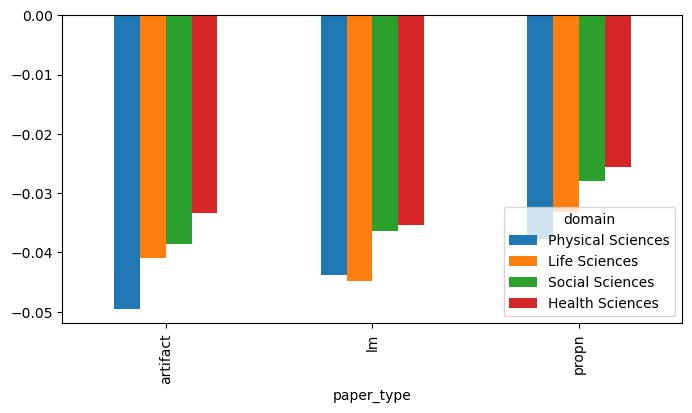

In [28]:
(docs[docs["paper_type"] != "human_only"].groupby(["domain", "paper_type"], observed=True)["avg_score_artifact"]
    .mean().unstack("domain")[sorted_index].plot.bar(figsize=(8,4)))

<Axes: xlabel='domain'>

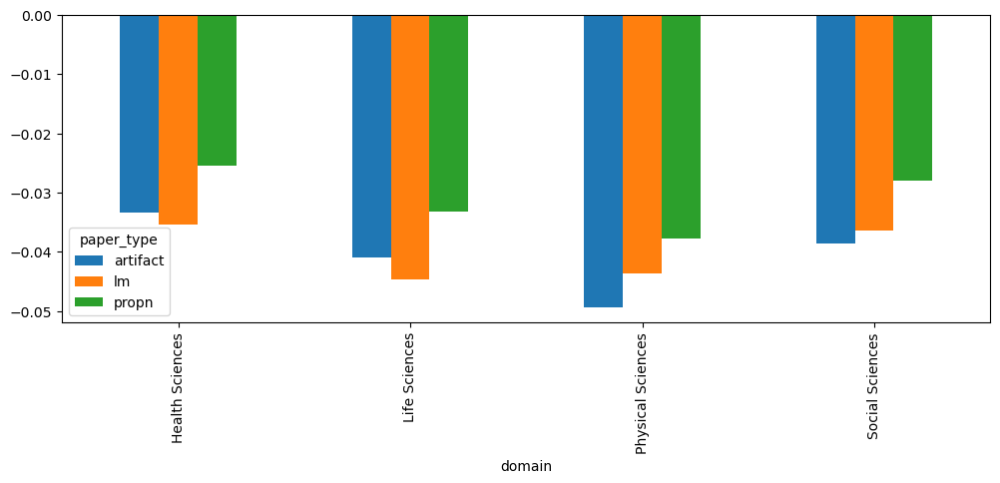

In [68]:
docs[docs["paper_type"] != "human_only"].groupby(["domain", "paper_type"], observed=True)["avg_score_artifact"].mean().unstack("paper_type").plot.bar(figsize=(12,4))

In [120]:
docs["year_int"] = docs["year"].astype(int)
docs.columns

Index(['id', 'year', 'domain', 'contains_artifact', 'contains_lm',
       'contains_propn_llm', 'contains_human', 'num_artifact', 'num_lm',
       'num_propn_llm', 'num_human', 'num_sents', 'num_unique_entities',
       'avg_score', 'avg_score_artifact', 'avg_score_lm',
       'avg_score_lm_no_propn', 'avg_score_propn_llm', 'avg_score_human',
       'post_chatgpt', 'paper_type', 'num_nonhuman_sents', 'year_int'],
      dtype='object')

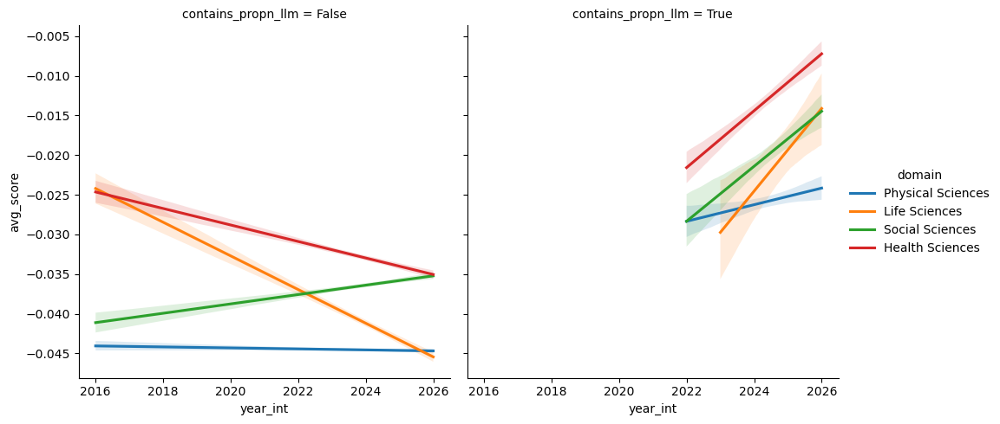

In [120]:
sns.lmplot(docs, x="year_int", y="avg_score", hue="domain", scatter=False, col="contains_propn_llm", hue_order=hue_order)

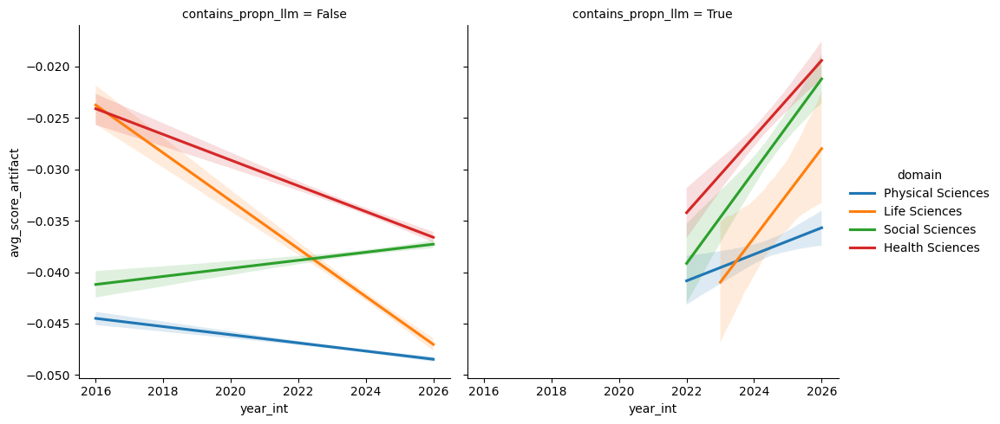

In [122]:
sns.lmplot(docs, x="year_int", y="avg_score_artifact", hue="domain", scatter=False, col="contains_propn_llm", hue_order=hue_order)

In [91]:
# Test the effect when the term AI is dropped
no_ai = df_dedupl[~df_dedupl["entity_lower"].isin(("ai", "artificial intelligence"))]["id"]
docs_no_ai = docs[docs["id"].isin(no_ai)].copy()

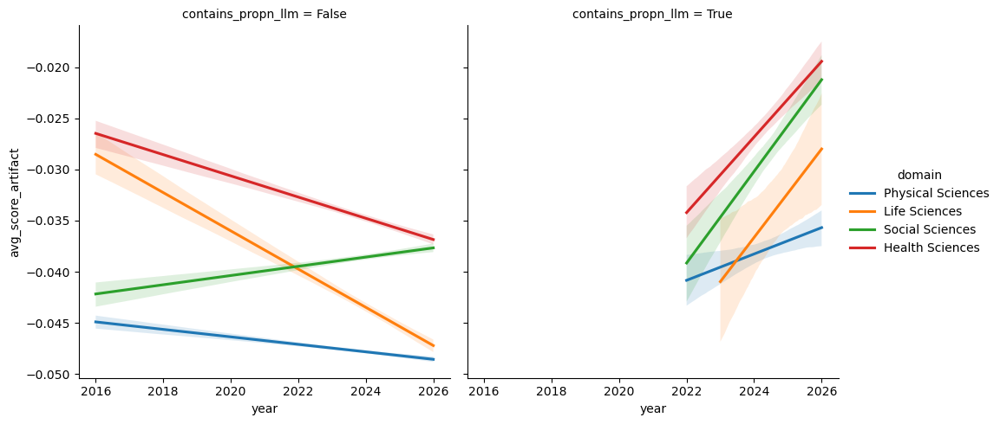

In [92]:
sns.lmplot(docs_no_ai, x="year", y="avg_score_artifact", hue="domain", scatter=False, col="contains_propn_llm", hue_order=hue_order)

In [184]:
pd.crosstab(docs["year"], docs["domain"])

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
year,,,,
2016,185,174,981,186
2017,239,239,1248,355
2018,403,288,2216,711
2019,803,448,3566,1255
2020,1607,638,5769,2049
2021,2371,941,8359,2990
2022,3328,1364,11362,4130
2023,6400,2281,20483,7528
2024,9758,3811,38283,17033


In [160]:
pd.crosstab(docs[docs["contains_lm"]]["year"], docs[docs["contains_lm"]]["domain"])

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
year,,,,
2016,2,1,135,7
2017,1,8,175,35
2018,5,8,303,42
2019,18,14,587,97
2020,44,29,1110,157
2021,72,65,1722,239
2022,116,132,2619,416
2023,1652,396,7894,1473
2024,2861,1038,17741,4729


In [161]:
pd.crosstab(docs[docs["contains_propn_llm"]]["year"], docs[docs["contains_propn_llm"]]["domain"])

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
year,,,,
2022,9,0,19,2
2023,1134,44,1033,390
2024,1481,97,1984,1013
2025,1894,163,2205,1224
2026,532,93,484,315


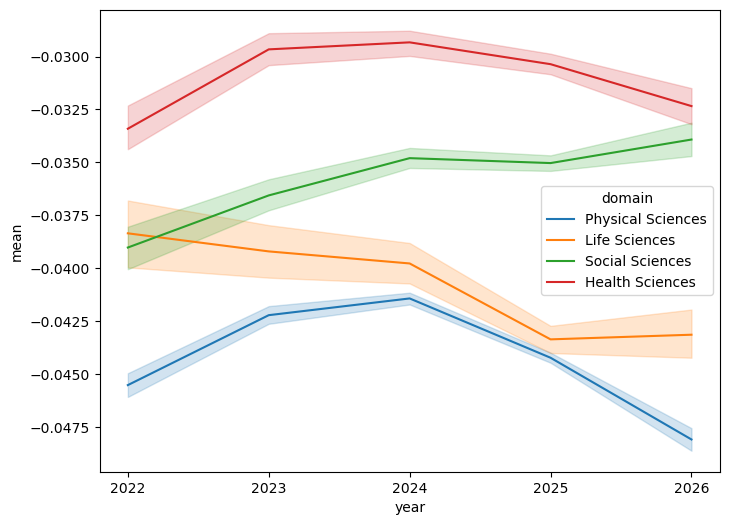

In [63]:
plt.figure(figsize=(8,6))
ax = sns.lineplot(docs[docs["year_int"] > 2021], x="year", y="avg_score", hue="domain", hue_order=hue_order)
ax.set_ylabel("mean")
plt.savefig("../figures/avg_scores.pdf", bbox_inches="tight")

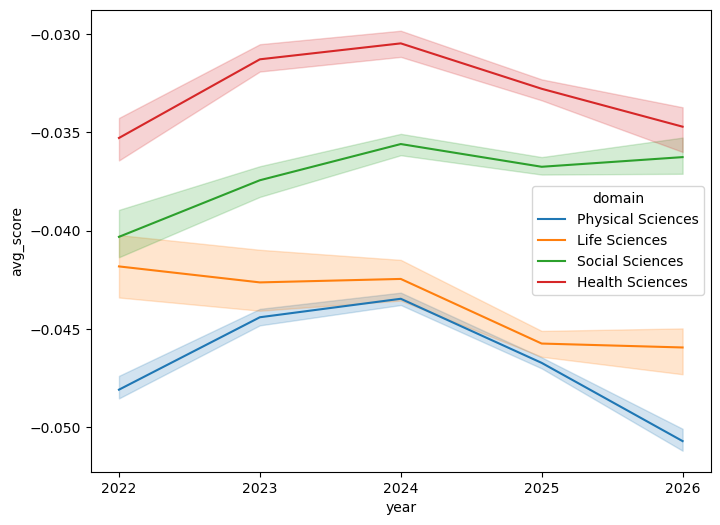

In [121]:
plt.figure(figsize=(8,6))
ax = sns.lineplot(docs[docs["year_int"] > 2021], x="year", y="avg_score", hue="domain", hue_order=hue_order, estimator="median")

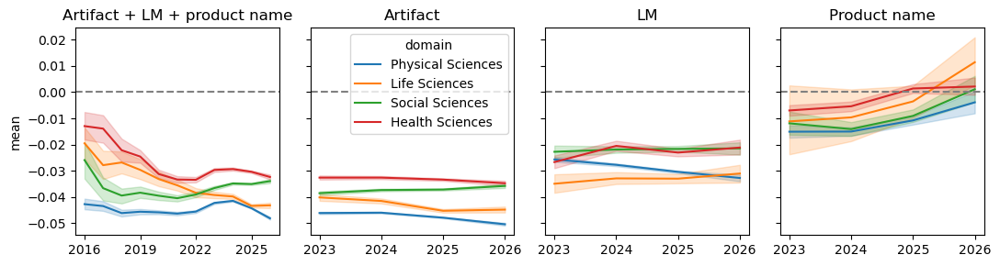

In [172]:
from matplotlib.ticker import MultipleLocator

fig, axes = plt.subplots(1, 4, figsize=(11,3), sharey=True)

sns.lineplot(docs, x="year", y="avg_score", hue="domain", hue_order=hue_order, ax=axes[0], legend=False)
axes[0].set_ylabel("mean")
axes[0].set_xlabel("")
axes[0].set_title("Artifact + LM + product name") # 
axes[0].xaxis.set_major_locator(MultipleLocator(3))
axes[0].axhline(0, color="gray", ls="--")

sns.lineplot(docs[docs["year_int"] > 2022], x="year", y="avg_score_artifact", hue="domain", hue_order=hue_order, ax=axes[1], legend=True)
axes[1].set_ylabel("mean")
axes[1].set_xlabel("")
axes[1].set_title("Artifact") # + LM + product name
axes[1].axhline(0, color="gray", ls="--")

sns.lineplot(docs[docs["year_int"] > 2022], x="year", y="avg_score_lm_no_propn", hue="domain", hue_order=hue_order, ax=axes[2], legend=False)
axes[2].set_ylabel("mean")
axes[2].set_xlabel("")
axes[2].set_title("LM") # + LM + product name
axes[2].axhline(0, color="gray", ls="--")

sns.lineplot(docs[docs["year_int"] > 2022], x="year", y="avg_score_propn_llm", hue="domain", hue_order=hue_order, ax=axes[3], legend=False)
axes[3].axhline(0, color="gray", ls="--")
axes[3].set_ylabel("")
axes[3].set_xlabel("")
axes[3].set_title("Product name")
plt.savefig("../figures/avg_scores_per_year.pdf", bbox_inches="tight")
plt.tight_layout()

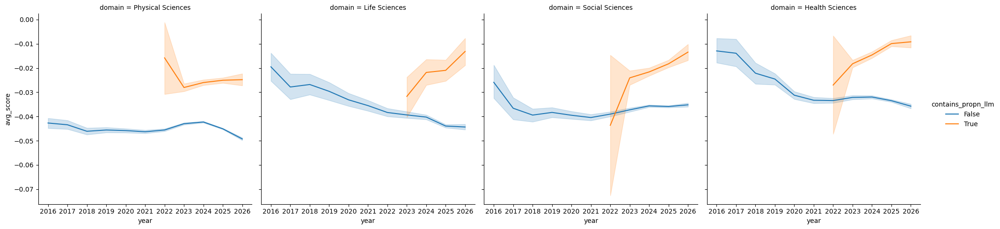

In [142]:
sns.relplot(docs, x="year", y="avg_score", col="domain", hue="contains_propn_llm", kind="line", facet_kws={"sharex": False}, col_order=hue_order)

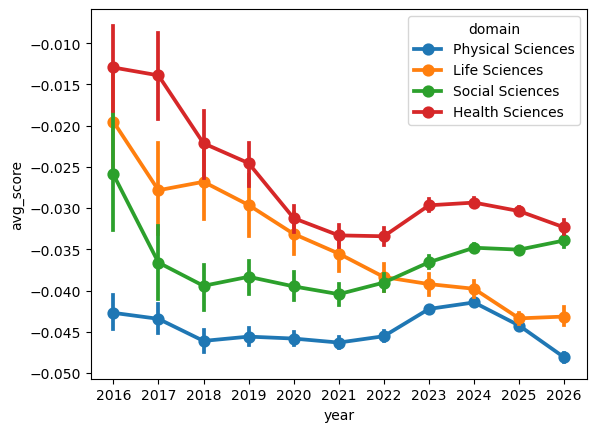

In [162]:
ax = sns.pointplot(docs, x="year", y="avg_score", hue="domain", hue_order=hue_order)

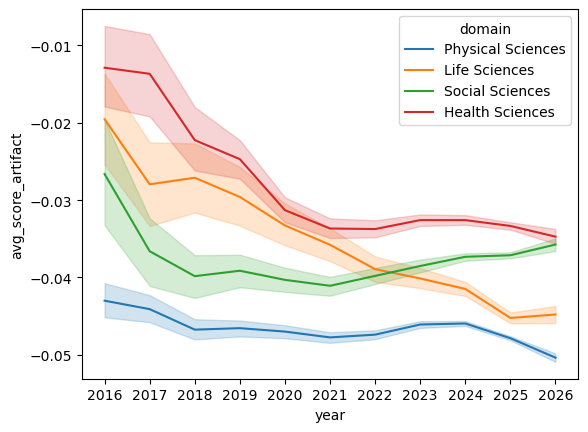

In [128]:
ax = sns.lineplot(docs, x="year", y="avg_score_artifact", hue="domain", hue_order=hue_order)

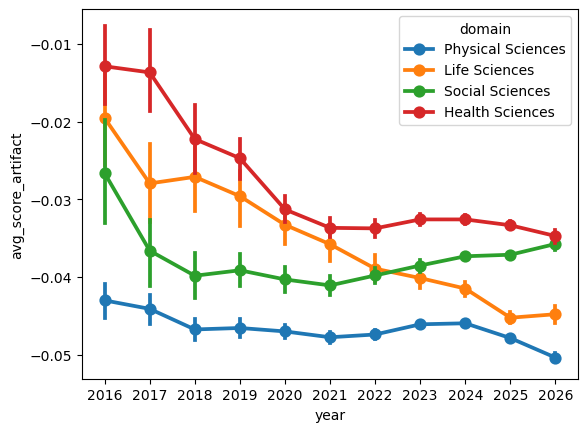

In [123]:
ax = sns.pointplot(docs, x="year", y="avg_score_artifact", hue="domain", hue_order=hue_order)

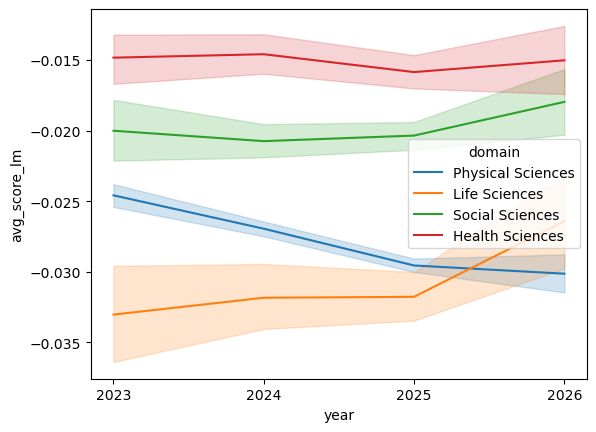

In [131]:
ax = sns.lineplot(docs[docs["post_chatgpt"]], x="year", y="avg_score_lm", hue="domain", hue_order=hue_order)

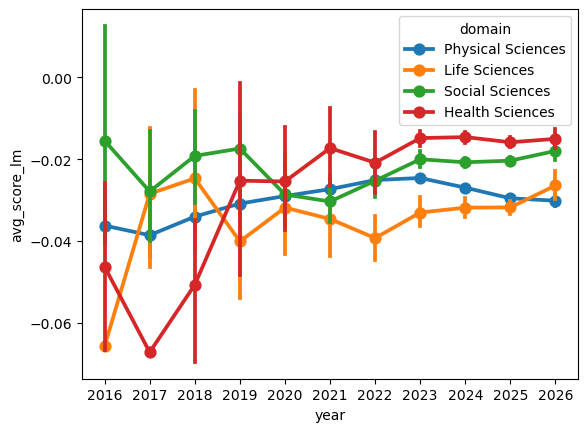

In [164]:
ax = sns.pointplot(docs, x="year", y="avg_score_lm", hue="domain", hue_order=hue_order)

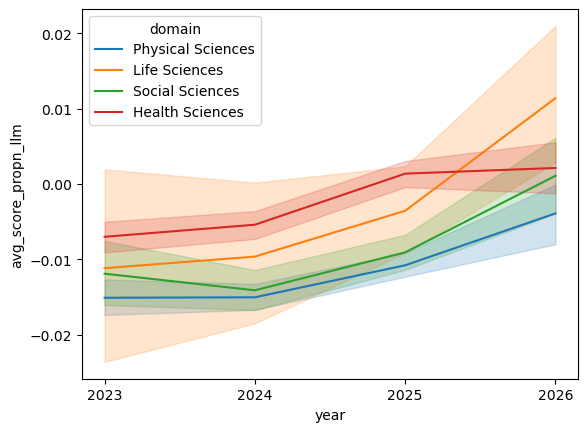

In [132]:
ax = sns.lineplot(docs[docs["post_chatgpt"] == True], x="year", y="avg_score_propn_llm", hue="domain", hue_order=hue_order)

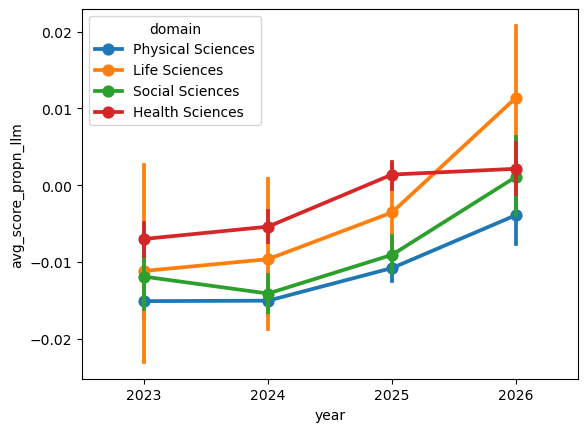

In [165]:
ax = sns.pointplot(docs[docs["post_chatgpt"] == True], x="year", y="avg_score_propn_llm", hue="domain", hue_order=hue_order)

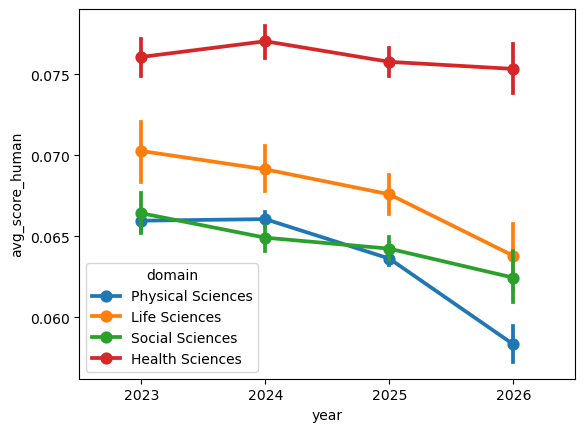

In [167]:
ax = sns.pointplot(docs[docs["post_chatgpt"] == True], x="year", y="avg_score_human", hue="domain", hue_order=hue_order)

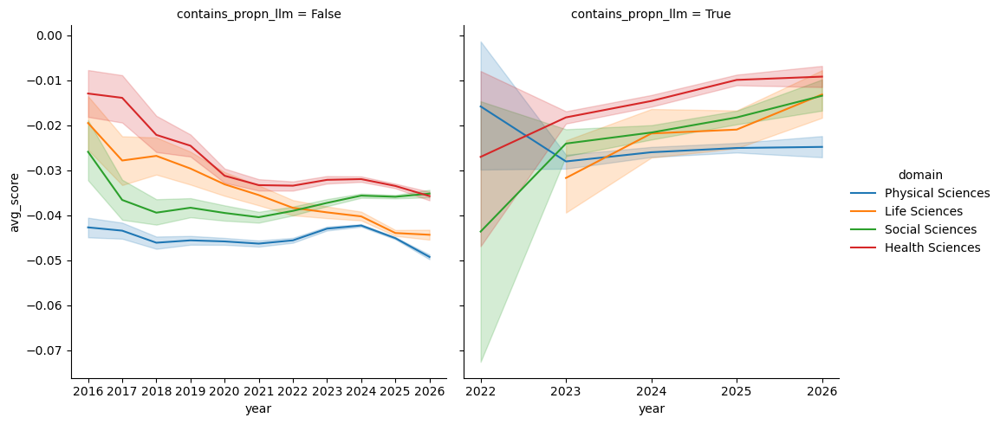

In [141]:
sns.relplot(docs, x="year", y="avg_score", hue="domain", col="contains_propn_llm", kind="line", facet_kws={"sharex": False}, hue_order=hue_order)

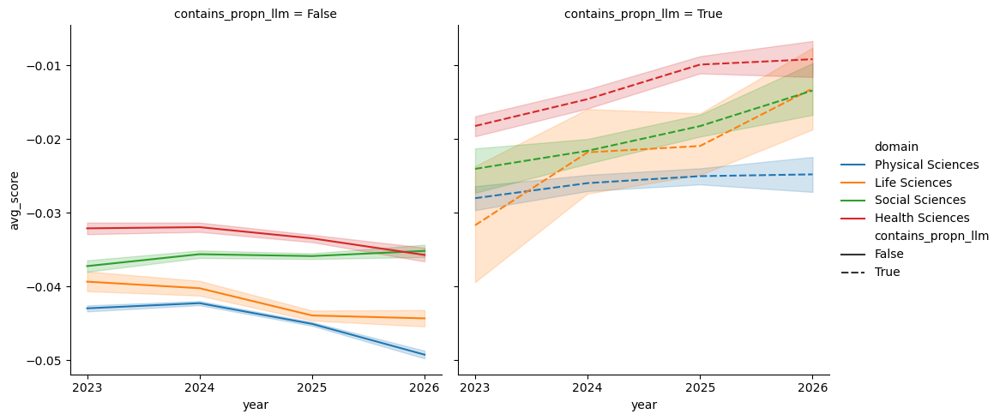

In [144]:
g = sns.relplot(docs[docs["post_chatgpt"]], x="year", y="avg_score",
                hue="domain", col="contains_propn_llm", style="contains_propn_llm",
                kind="line", hue_order=hue_order,
                facet_kws={"sharex": False})

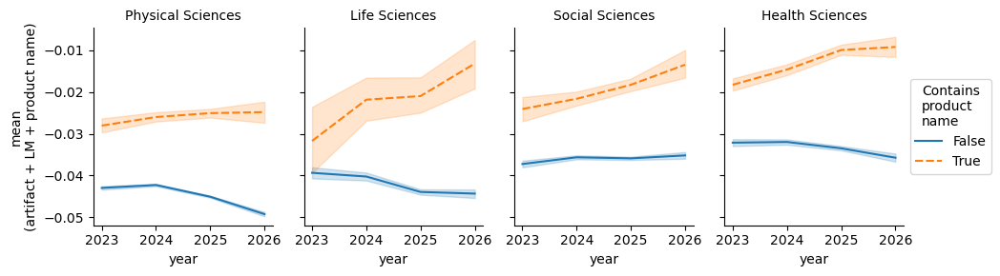

In [85]:
g = sns.relplot(docs[docs["post_chatgpt"]], x="year", y="avg_score",
                hue="contains_propn_llm", style="contains_propn_llm",
                col="domain", col_order=hue_order,
                kind="line", height=3, aspect=0.8,)
g.set_titles(col_template="{col_name}")
g.set_axis_labels(y_var="mean\n(artifact + LM + product name)")
#g.legend.set_title("Contains\nproduct\nname")
#sns.move_legend(g, "upper right", title="Contains\nproduct\nname")
last_ax = g.axes.flat[-1]
sns.move_legend(
    g, 
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),   # relative to last_ax, not the figure
    bbox_transform=last_ax.transAxes,
    frameon=True,
    title="Contains\nproduct\nname"
)
plt.savefig("../figures/relplot.pdf", bbox_inches="tight")

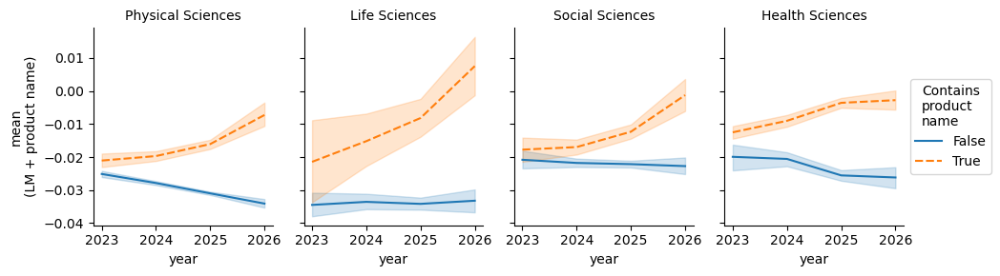

In [86]:
g = sns.relplot(docs[docs["post_chatgpt"]], x="year", y="avg_score_lm",
                hue="contains_propn_llm", style="contains_propn_llm",
                col="domain", col_order=hue_order,
                kind="line", height=3, aspect=0.8,)
g.set_titles(col_template="{col_name}")
last_ax = g.axes.flat[-1]
g.set_axis_labels(y_var="mean\n(LM + product name)")
sns.move_legend(
    g, 
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),   # relative to last_ax, not the figure
    bbox_transform=last_ax.transAxes,
    frameon=True,
    title="Contains\nproduct\nname"
)
plt.savefig("../figures/relplot_lm.pdf", bbox_inches="tight")

## Term frequencies

I want to inspect if the detected rise in averages is correlated with the rise in the number of proper noun LLM terms.

In [89]:
docs.columns

Index(['year', 'domain', 'contains_artifact', 'contains_lm',
       'contains_propn_llm', 'contains_human', 'num_artifact', 'num_lm',
       'num_propn_llm', 'num_human', 'num_sents', 'num_unique_entities',
       'avg_score', 'avg_score_artifact', 'avg_score_lm',
       'avg_score_lm_no_propn', 'avg_score_propn_llm', 'avg_score_human',
       'post_chatgpt'],
      dtype='object')

In [90]:
docs["num_lm"].describe()

count    284148.000000
mean          1.039251
std           2.241531
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max          78.000000
Name: num_lm, dtype: float64

In [193]:
to_sum_cols = [f"num_{suffix}" for suffix in ("artifact", "lm", "propn_llm")]

In [194]:
domain_propn = docs[docs["post_chatgpt"] == True].groupby("domain", observed=True)[to_sum_cols].sum()
domain_propn.style.background_gradient(axis=None)

,num_artifact,num_lm,num_propn_llm
domain,,,
Health Sciences,239160,30355,19624
Life Sciences,94995,10583,899
Physical Sciences,835170,185715,12212
Social Sciences,396360,45205,6402


In [197]:
chi2, p, dof, expected_freq = stats.chi2_contingency(domain_propn.values)

In [198]:
print(f"chi2={chi2}, p={p}, dof={dof}")

chi2=58401.704529737326, p=0.0, dof=6


In [199]:
pd.DataFrame(expected_freq, columns=domain_propn.columns, index=domain_propn.index).style.background_gradient(axis=None)

,num_artifact,num_lm,num_propn_llm
domain,,,
Health Sciences,241224.180582,41885.004509,6029.814909
Life Sciences,88832.108695,15424.379365,2220.511941
Physical Sciences,861896.794576,149655.606830,21544.598594
Social Sciences,373731.916147,64893.009296,9342.074557


In [195]:
domain_propn_normalized = domain_propn.div(domain_propn.sum(axis=1), axis=0)
domain_propn_normalized.style.background_gradient(axis=None)

,num_artifact,num_lm,num_propn_llm
domain,,,
Health Sciences,0.827145,0.104984,0.067870
Life Sciences,0.892165,0.099392,0.008443
Physical Sciences,0.808414,0.179765,0.011821
Social Sciences,0.884797,0.100911,0.014291


In [196]:
domain_lm = domain_propn.drop(columns="num_artifact")
domain_lm_normalized = domain_lm.div(domain_lm.sum(axis=1), axis=0)
domain_lm_normalized.style.background_gradient(axis=None)

,num_lm,num_propn_llm
domain,,
Health Sciences,0.607355,0.392645
Life Sciences,0.921704,0.078296
Physical Sciences,0.938300,0.061700
Social Sciences,0.875947,0.124053


In [200]:
propn_appearance = docs[docs["post_chatgpt"] == True].groupby(["year", "domain"], observed=True)["num_propn_llm"].sum().unstack("domain")
propn_appearance.style.background_gradient(axis=None)

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
year,,,,
2023,4888,116,2426,907
2024,5952,201,4219,2282
2025,6936,374,4646,2551
2026,1848,208,921,662


In [201]:
propn_appearance.sum()

domain
Health Sciences      19624
Life Sciences          899
Physical Sciences    12212
Social Sciences       6402
dtype: int64

In [202]:
19624/12212

1.6069439895185065

In [179]:
docs.groupby(["year", "domain"], observed=True)[num_cols].sum().unstack("domain").style.background_gradient(axis=None)

In [100]:
docs.groupby(["year", "domain"], observed=True)[avg_score_cols].mean().unstack("domain").style.background_gradient(axis=None)

<Axes: xlabel='year', ylabel='entity_stripped'>

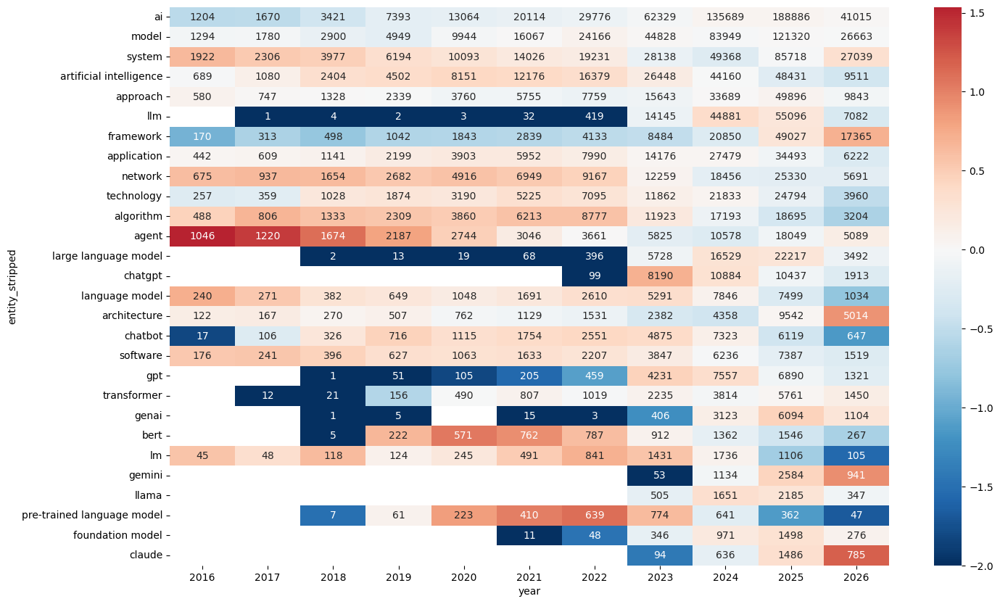

In [307]:
sub = df_dedupl[df_dedupl["entity_type_updated"] != "human"].copy()
sub_order = sub.value_counts("entity_stripped").index.tolist()
counts = sub.value_counts(["entity_stripped", "year"])[lambda x: x > 0].unstack().loc[sub_order]
fig, ax = plt.subplots(figsize=(16, 10))
sns.heatmap(
    standardize(counts), annot=counts, fmt=".0f",
    ax=ax, center=0, cmap="RdBu_r", yticklabels=1, vmin=-2
)

In [331]:
arts, lms = sub.groupby("entity_type", observed=True)["entity_stripped"].unique().tolist()
arts_order = [e for e in sub_order if e in arts]
lms_order = [e for e in sub_order if e in lms]

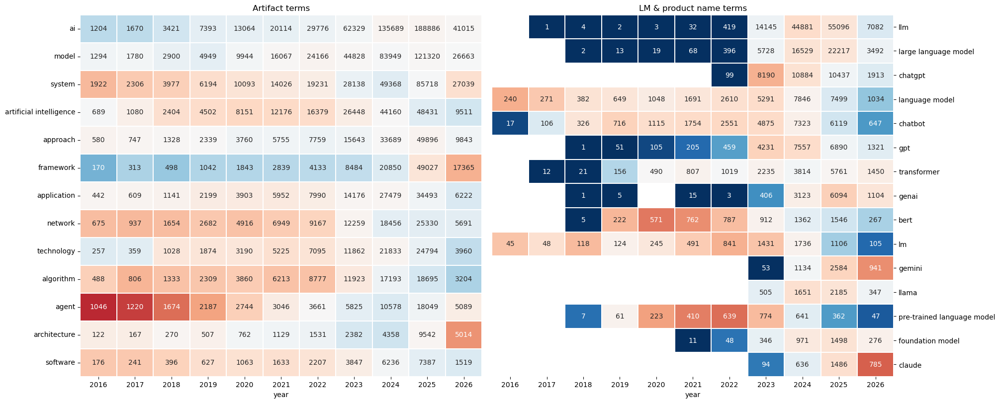

In [361]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8), layout="constrained")
st_counts = standardize(counts)
sns.heatmap(
    st_counts.loc[arts_order], annot=counts.loc[arts_order], linewidths=0.05, fmt=".0f",
    ax=axes[0], center=0, cmap="RdBu_r", yticklabels=1, xticklabels=1, vmin=-2, vmax=1.5, cbar=False
)
axes[0].set_title("Artifact terms")
axes[0].set_ylabel("")

sns.heatmap(
    st_counts.loc[lms_order], annot=counts.loc[lms_order], linewidths=0.05, fmt=".0f",
    ax=axes[1], center=0, cmap="RdBu_r", yticklabels=1, xticklabels=1, vmin=-2, vmax=1.5, cbar=False
)
axes[1].set_title("LM & product name terms")
axes[1].tick_params(axis="y", right=True, left=False, labelleft=False, labelright=True, labelrotation=0)
axes[1].set_ylabel("")
plt.show()

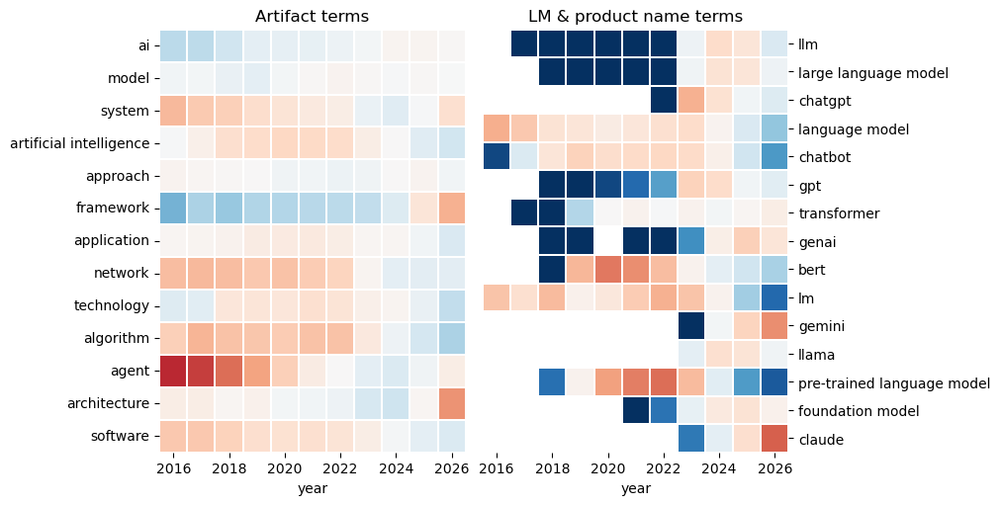

In [363]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), layout="constrained")
st_counts = standardize(counts)
sns.heatmap(
    st_counts.loc[arts_order], linewidths=0.05,
    ax=axes[0], center=0, cmap="RdBu_r", yticklabels=1, xticklabels=2, vmin=-2, vmax=1.5, cbar=False
)
axes[0].set_title("Artifact terms")
axes[0].set_ylabel("")

sns.heatmap(
    st_counts.loc[lms_order], linewidths=0.05,
    ax=axes[1], center=0, cmap="RdBu_r", yticklabels=1, xticklabels=2, vmin=-2, vmax=1.5, cbar=False
)
axes[1].set_title("LM & product name terms")
axes[1].tick_params(axis="y", right=True, left=False, labelleft=False, labelright=True, labelrotation=0)
axes[1].set_ylabel("")
plt.savefig("../figures/term-frequency.pdf")
plt.show()

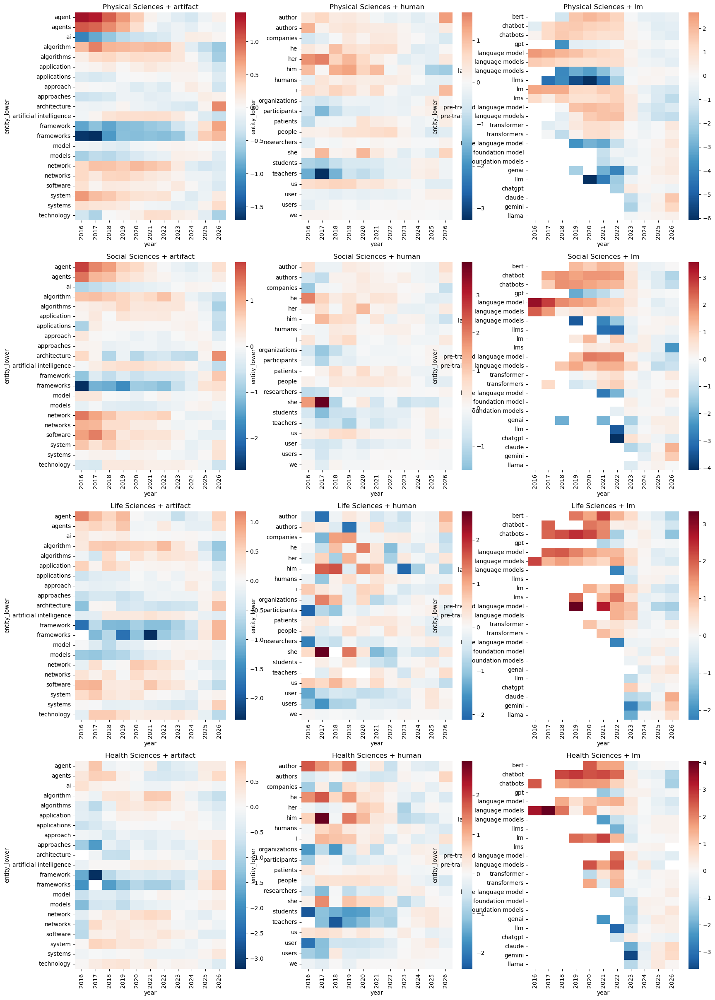

In [145]:
fig, axes = plt.subplots(df_dedupl.domain.nunique(), df_dedupl.entity_type.nunique(), figsize=(20, 30))

for i, d in enumerate(df_dedupl.domain.unique()):
    for j, et in enumerate(df_dedupl.entity_type.unique()):
        axes[i][j].set_title(f"{d} + {et}")
        subset = df_dedupl[(df_dedupl["domain"] == d) & (df_dedupl["entity_type"] == et)]
        O = pd.crosstab(subset["entity_lower"], subset["year"])
        row_totals = O.sum(axis=1)
        col_totals = O.sum(axis=0)
        grand_total = O.values.sum()
        
        E = np.outer(row_totals, col_totals) / grand_total
        E = pd.DataFrame(E, index=O.index, columns=O.columns)
        
        lift = O / E
        log_lift = np.log(lift.mask(lift == 0, np.nan))
        sns.heatmap(log_lift, ax=axes[i][j], yticklabels=1, cmap="RdBu_r", center=0)

plt.show()

In the following plot, the counts for each entity per year are normalized row-wise, highligting when the term has been used the most (within each domain). For some terms it can be seen clearly that the use has stopped after some other term has been introduced; for example "pre-trained language model(s)" has not been used that much since 2024.

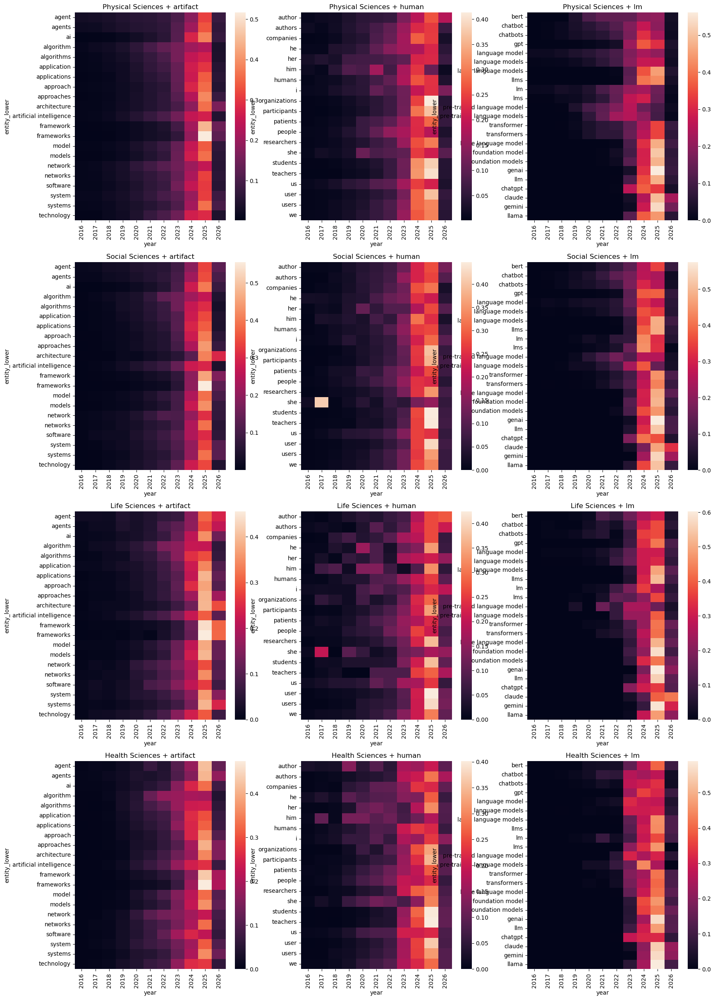

In [101]:
fig, axes = plt.subplots(df_dedupl.domain.nunique(), df_dedupl.entity_type.nunique(), figsize=(20, 30))

for i, d in enumerate(df_dedupl.domain.unique()):
    for j, et in enumerate(df_dedupl.entity_type.unique()):
        #print(f"i={i} j={j} domain={d} entity_type={et}")
        axes[i][j].set_title(f"{d} + {et}")
        subset = df_dedupl[(df_dedupl["domain"] == d) & (df_dedupl["entity_type"] == et)]
        sns.heatmap(pd.crosstab(subset["entity_lower"], subset["year"], normalize="index"), ax=axes[i][j], yticklabels=1)

plt.show()

In the following plot, the counts for each entity per year are normalized column-wise, which highlights which terms are used most and least per each year and domain. This also shows when certain terms have been heavily used; for example, how "LLM(s)" and "large language model(s)" have replaced "language model". One can also see the popularity of BERT before ChatGPT. One can also spot domain-specific terms, like "chatbot(s)" being the preferred term before ChatGPT in Social and Health Sciences especially.

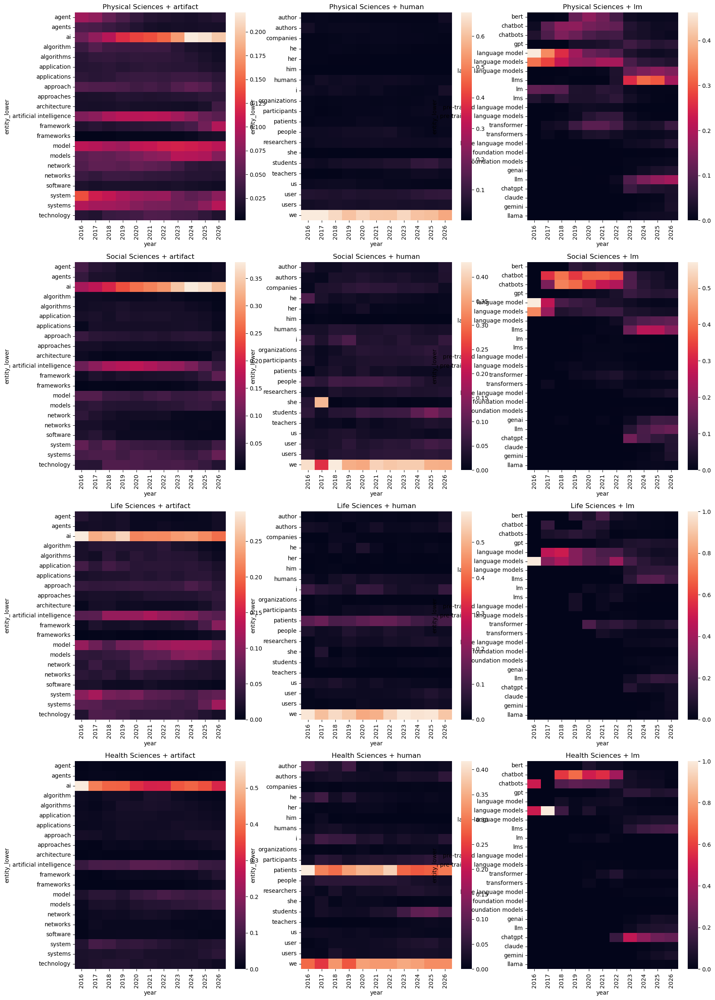

In [102]:
fig, axes = plt.subplots(df_dedupl.domain.nunique(), df_dedupl.entity_type.nunique(), figsize=(20, 30))

for i, d in enumerate(df_dedupl.domain.unique()):
    for j, et in enumerate(df_dedupl.entity_type.unique()):
        axes[i][j].set_title(f"{d} + {et}")
        subset = df_dedupl[(df_dedupl["domain"] == d) & (df_dedupl["entity_type"] == et)]
        sns.heatmap(pd.crosstab(subset["entity_lower"], subset["year"], normalize="columns"), ax=axes[i][j], yticklabels=1)

plt.show()

In the plots below all cells are included in the normalization, showing where the mass of the sentences come from; which years and terms overpower the analysis. For example, in Health and Social Sciences ChatGPT is used much heavier in relation to other terms than in Physical or Life Sciences.

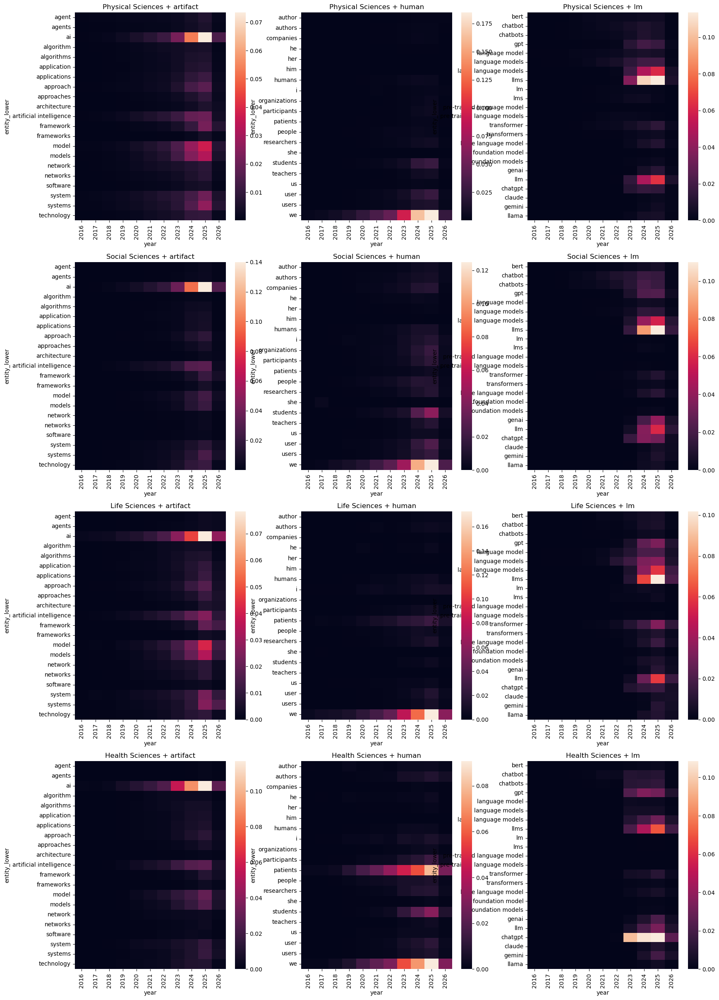

In [103]:
fig, axes = plt.subplots(df_dedupl.domain.nunique(), df_dedupl.entity_type.nunique(), figsize=(20, 30))

for i, d in enumerate(df_dedupl.domain.unique()):
    for j, et in enumerate(df_dedupl.entity_type.unique()):
        axes[i][j].set_title(f"{d} + {et}")
        subset = df_dedupl[(df_dedupl["domain"] == d) & (df_dedupl["entity_type"] == et)]
        sns.heatmap(pd.crosstab(subset["entity_lower"], subset["year"], normalize="all"), ax=axes[i][j], yticklabels=1)

plt.show()

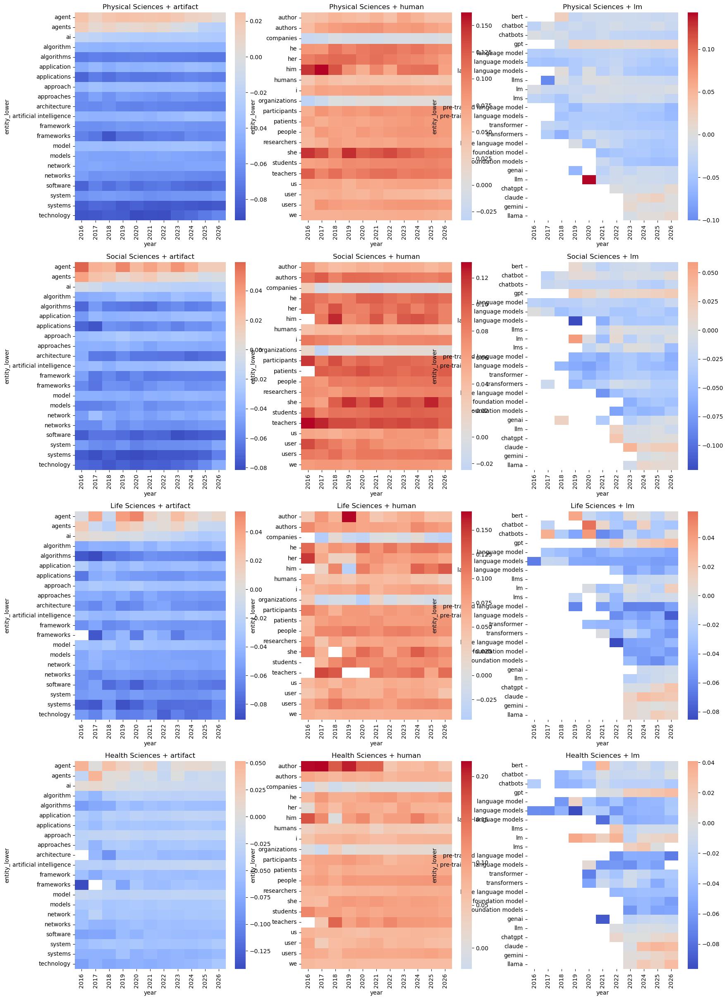

In [146]:
fig, axes = plt.subplots(df_dedupl.domain.nunique(), df_dedupl.entity_type.nunique(), figsize=(20, 30))

for i, d in enumerate(df_dedupl.domain.unique()):
    for j, et in enumerate(df_dedupl.entity_type.unique()):
        axes[i][j].set_title(f"{d} + {et}")
        subset = df_dedupl[(df_dedupl["domain"] == d) & (df_dedupl["entity_type"] == et)]
        sns.heatmap(subset.groupby(["entity_lower", "year"], observed=True)["score"].mean().unstack(), ax=axes[i][j], yticklabels=1, cmap="coolwarm", center=0)

plt.show()

In [130]:
df_dedupl_nohum = df_dedupl[df_dedupl["entity_type_updated"] != "human"].copy()
df_dedupl_nohum["entity_type_updated"] = df_dedupl_nohum["entity_type_updated"].cat.remove_unused_categories()
df_dedupl_nohum["entity_lower"] = df_dedupl_nohum["entity_lower"].cat.remove_unused_categories()

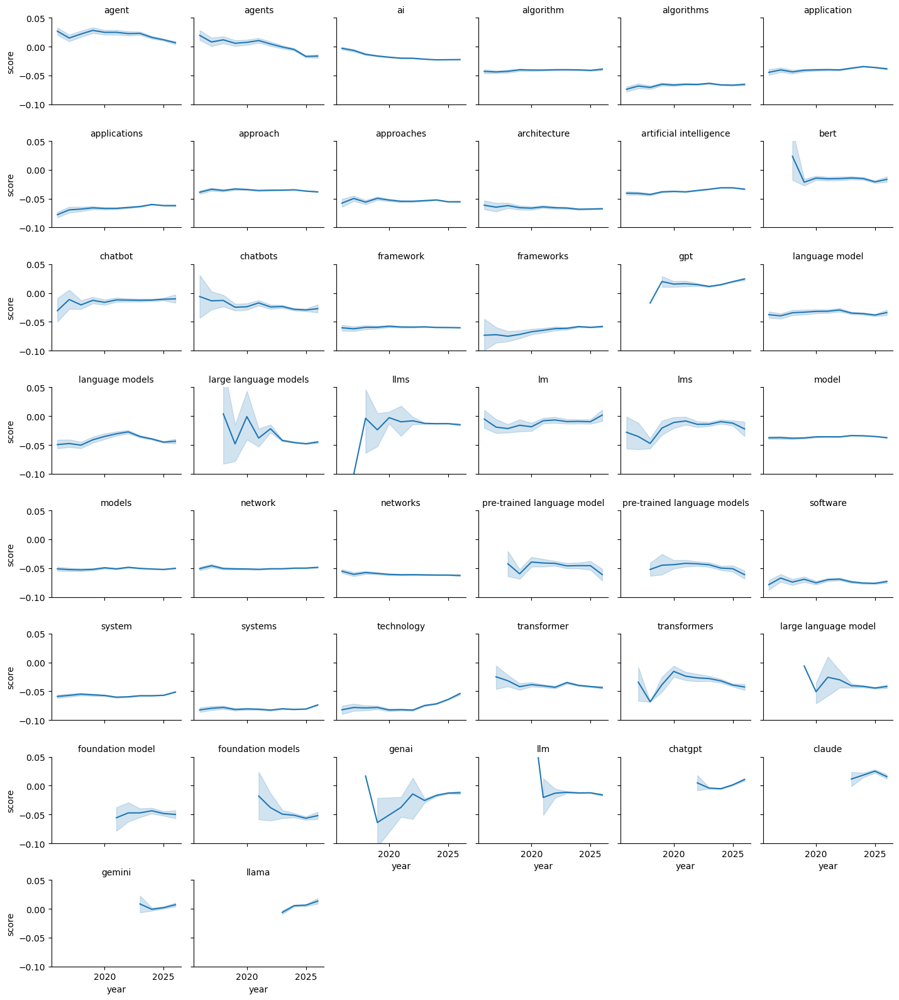

In [96]:
g = sns.relplot(
    data=df_dedupl_nohum,
    x="year", y="score", col="entity_lower", col_wrap=6,
    kind="line", height=2, aspect=1.2, facet_kws={"sharey": True}
)
g.set_titles("{col_name}")
g.set(ylim=(-0.1, 0.05))
plt.tight_layout()
plt.show()

Physical Sciences


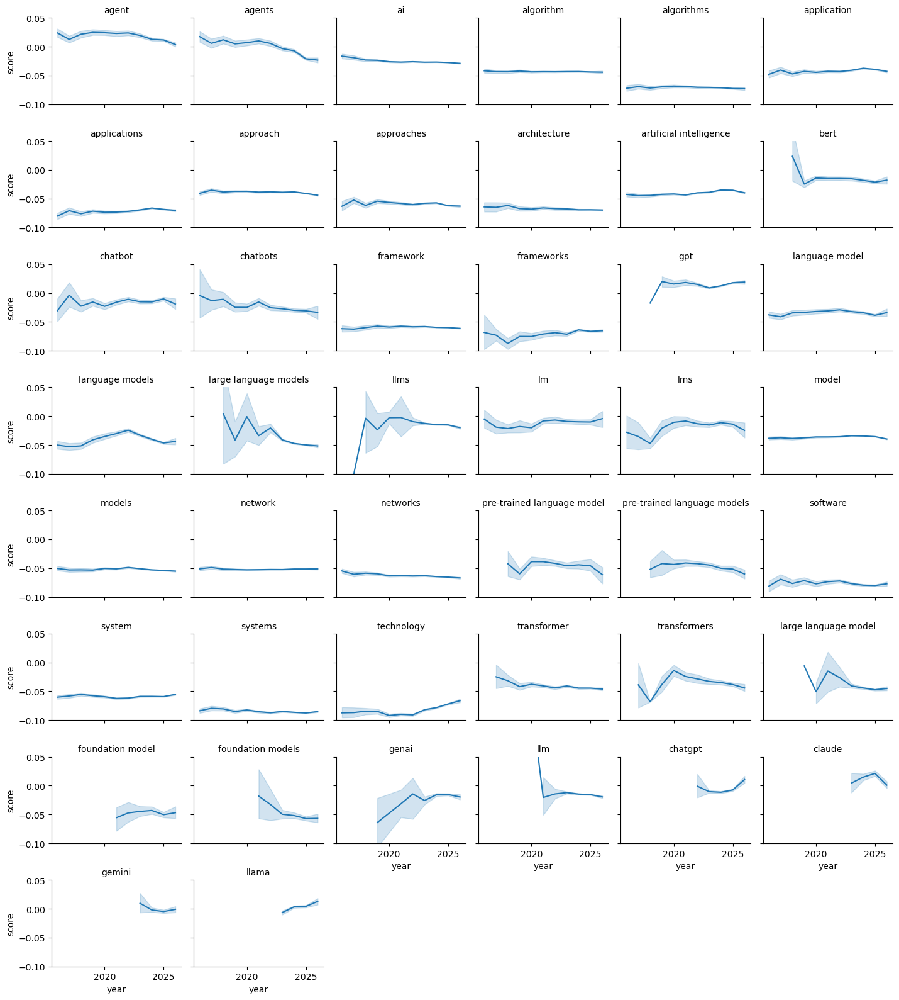


Social Sciences


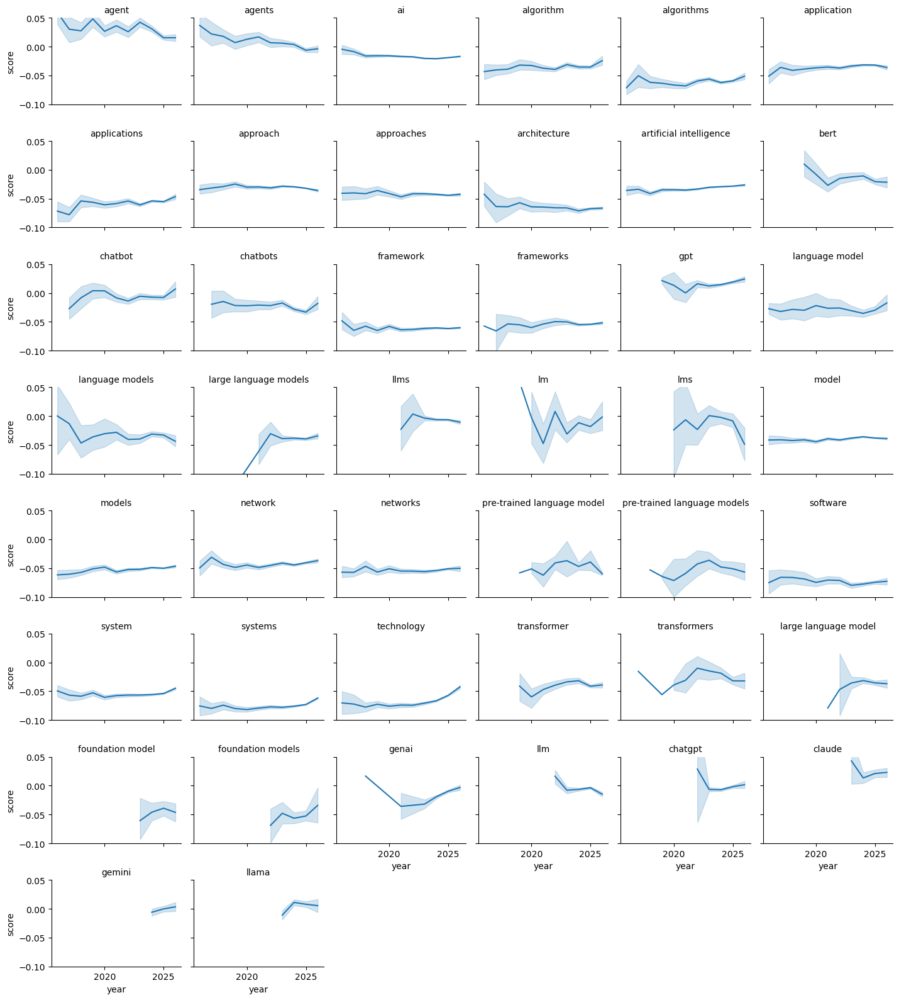


Life Sciences


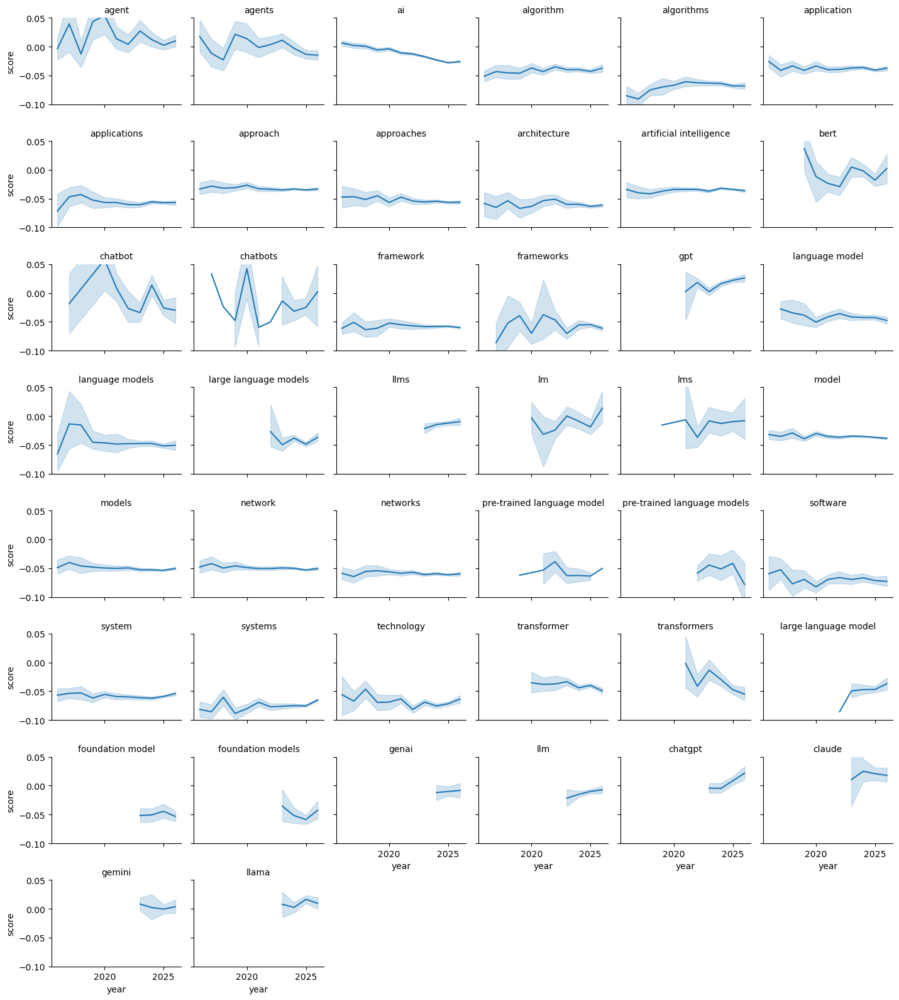


Health Sciences


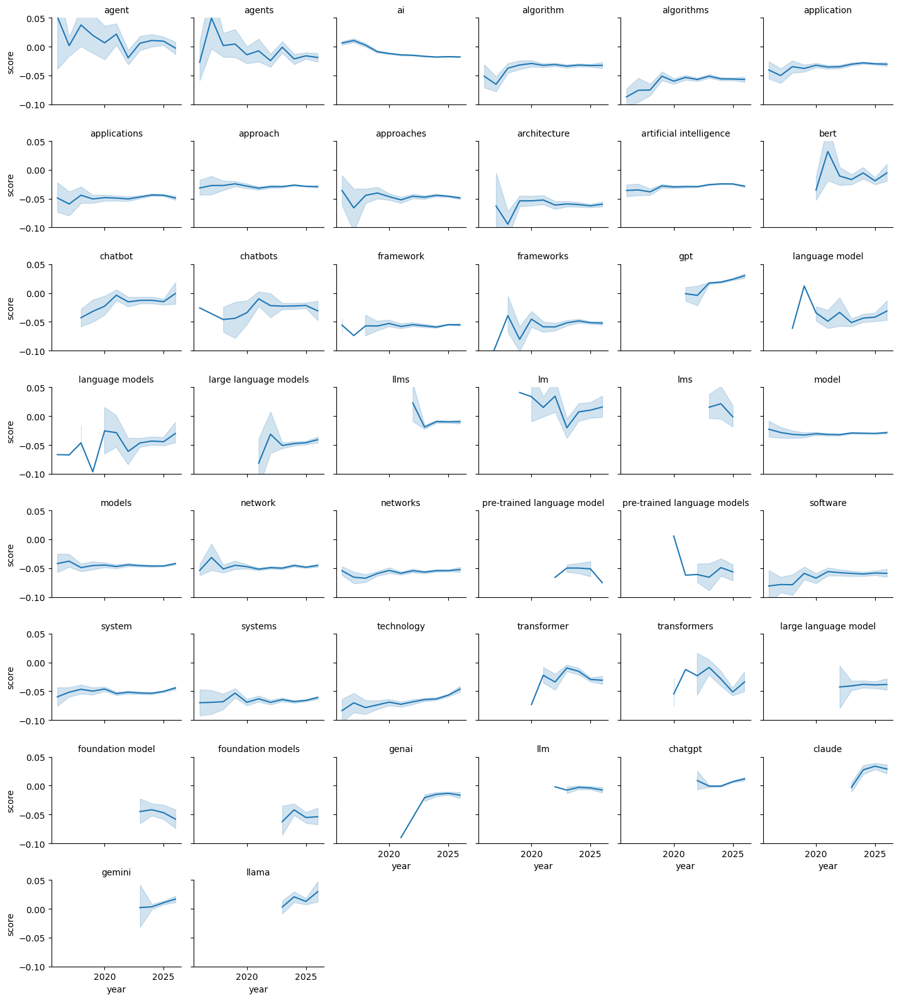

In [97]:
for domain in df_dedupl.domain.unique():
    print(domain)
    g = sns.relplot(
        data=df_dedupl_nohum[df_dedupl_nohum["domain"] == domain],
        x="year", y="score", col="entity_lower", col_wrap=6,
        kind="line", height=2, aspect=1.2, facet_kws={"sharey": True}
    )
    g.set_titles("{col_name}")
    g.set(ylim=(-0.1, 0.05))
    plt.tight_layout()
    plt.show()
    print()

<Axes: xlabel='entity_lower-domain', ylabel='year'>

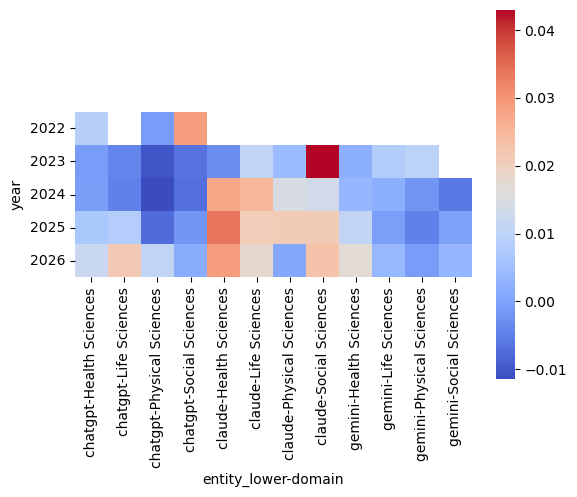

In [246]:
sns.heatmap((df_dedupl[(df_dedupl["is_propn_llm"] == True) & (df_dedupl["year"] > 2021)]
    .groupby(["year", "domain", "entity_lower"], observed=True)["score"]
    .mean()
    .unstack(["entity_lower", "domain"])
    .sort_index(axis=1)
), cmap="coolwarm", square=True)

In [98]:
entity_bar_data = (df_dedupl.groupby("entity_lower", observed=True)
    .agg(
        score=("score", "mean"),
        entity_type=("entity_type_updated", "first")
    )
    .sort_values("score")
)

In [99]:
legend_map = {
    "artifact": "artifact",
    "lm": "LM",
    "propn_llm": "product name",
    "human": "human"
}
entity_bar_data = entity_bar_data.rename(columns={"entity_type": "Entity type"})
entity_bar_data["Entity type"] = entity_bar_data["Entity type"].cat.rename_categories(legend_map)

In [100]:
sorted_entities = entity_bar_data.groupby("Entity type", observed=True)["score"].mean().sort_values()

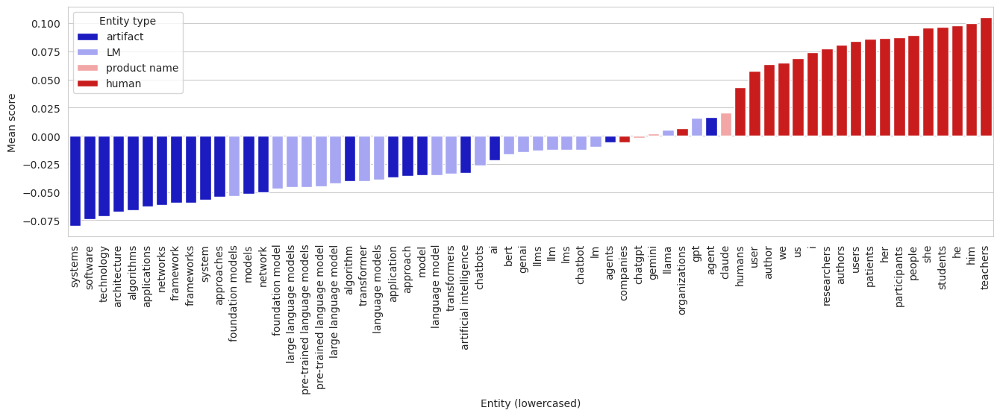

In [102]:
with sns.axes_style("whitegrid"):
    plt.figure(figsize=(16, 4))
    # ax = sns.barplot(entity_bar_data, x="entity_lower", y="score", hue="entity_type_updated", errorbar=None)
    ax = sns.barplot(entity_bar_data, x="entity_lower", y="score", hue="Entity type",
                     order=entity_bar_data.index, hue_order=sorted_entities.index, errorbar=None, palette="seismic")
    ax.set_xlabel("Entity (lowercased)")
    ax.set_ylabel("Mean score")
    plt.xticks(rotation=90)
    plt.savefig("../figures/entity_scores.pdf", bbox_inches="tight")
    plt.show()

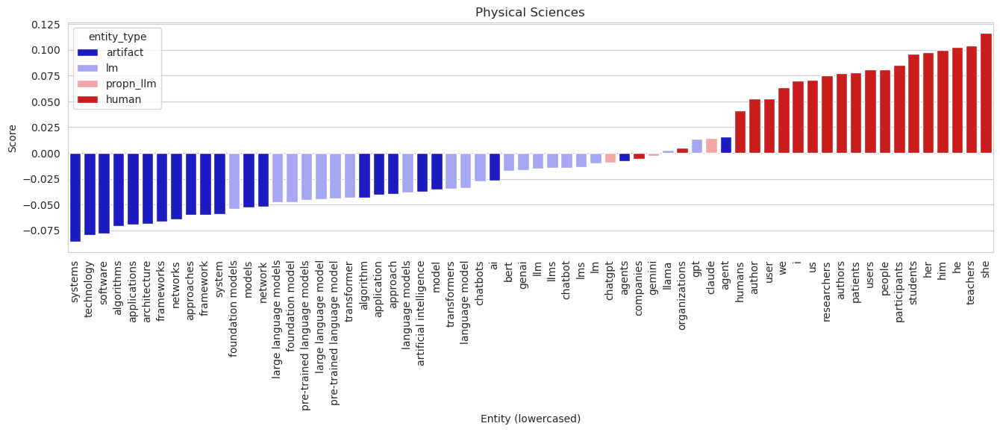

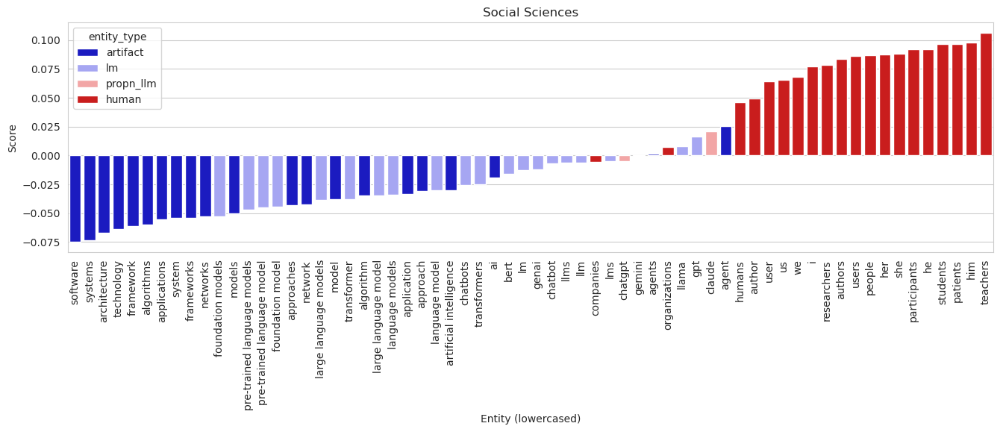

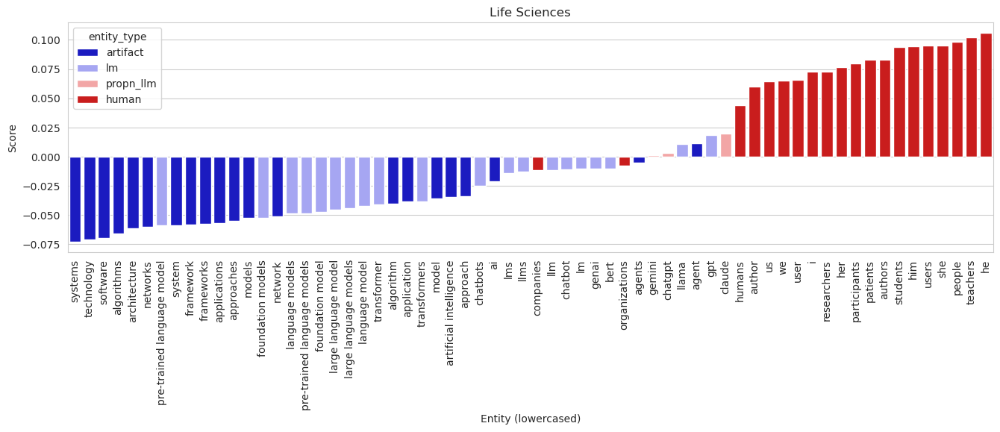

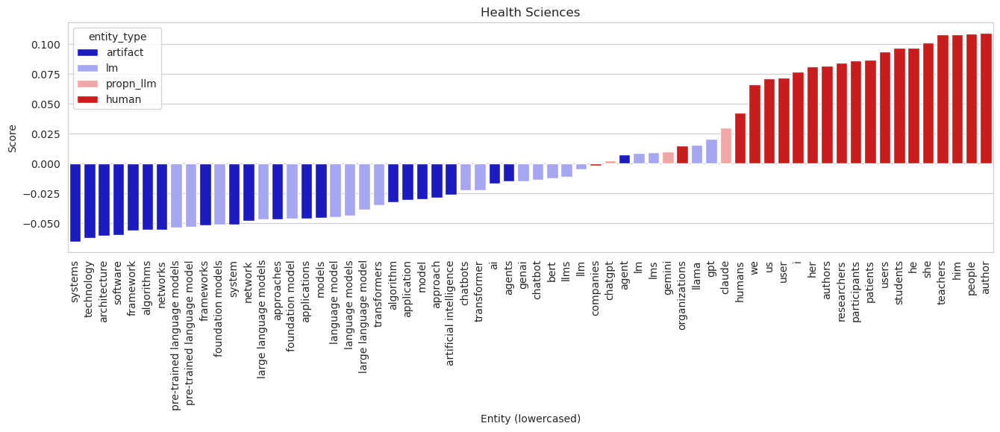

In [111]:
def plot_bars_domainwise():
    for domain in df_dedupl.domain.unique():
        with sns.axes_style("whitegrid"):
            entity_bar_data = (df_dedupl[df_dedupl["domain"] == domain].groupby("entity_lower", observed=True)
                                .agg(
                                    score=("score", "mean"),
                                    entity_type=("entity_type_updated", "first")
                                )
                                .sort_values("score")
                            )
            sorted_entities = entity_bar_data.groupby("entity_type", observed=True)["score"].mean().sort_values()
            
            plt.figure(figsize=(16, 4))
            # ax = sns.barplot(entity_bar_data, x="entity_lower", y="score", hue="entity_type_updated", errorbar=None)
            ax = sns.barplot(entity_bar_data, x="entity_lower", y="score", hue="entity_type",
                             order=entity_bar_data.index, hue_order=sorted_entities.index, errorbar=None, palette="seismic")
            ax.set_xlabel("Entity (lowercased)")
            ax.set_ylabel("Score")
            ax.set_title(domain)
            plt.xticks(rotation=90)
            plt.show()
plot_bars_domainwise()

In [17]:
series_list = []
for domain in df_dedupl.domain.unique():
    entity_per_domain = (df_dedupl[df_dedupl["domain"] == domain].groupby("entity_lower", observed=True)["score"].mean().sort_index())
    entity_per_domain = entity_per_domain.rename(domain)
    series_list.append(entity_per_domain)

entity_scores_per_domain = pd.DataFrame(series_list).T

In [18]:
spread = entity_scores_per_domain.copy()
spread["spread"] = abs(entity_scores_per_domain.max(axis=1) - entity_scores_per_domain.min(axis=1))
spread

,Physical Sciences,Social Sciences,Life Sciences,Health Sciences,spread
entity_lower,,,,,
agent,0.015605,0.025314,0.011507,0.007847,0.017467
agents,-0.008213,0.001753,-0.005262,-0.014720,0.016474
ai,-0.027007,-0.019157,-0.021386,-0.016419,0.010589
algorithm,-0.043446,-0.034839,-0.040202,-0.032392,0.011054
algorithms,-0.071103,-0.060253,-0.065672,-0.055299,0.015804
...,...,...,...,...,...
llm,-0.015094,-0.005975,-0.011365,-0.004538,0.010556
chatgpt,-0.009092,-0.004669,0.003447,0.002656,0.012539
claude,0.014399,0.021009,0.019656,0.030336,0.015937


In [19]:
spread.sort_values("spread", ascending=False)

,Physical Sciences,Social Sciences,Life Sciences,Health Sciences,spread
entity_lower,,,,,
author,0.052443,0.049040,0.059830,0.109323,0.060283
she,0.116330,0.088164,0.095293,0.101163,0.028166
people,0.080867,0.086795,0.098458,0.108607,0.027740
lms,-0.013699,-0.005151,-0.013838,0.009842,0.023680
applications,-0.069154,-0.055467,-0.057061,-0.045856,0.023297
...,...,...,...,...,...
humans,0.041458,0.046384,0.043987,0.042634,0.004926
we,0.063553,0.067976,0.065398,0.066043,0.004424
foundation models,-0.053990,-0.052649,-0.052085,-0.050801,0.003189


<Axes: xlabel='entity_lower'>

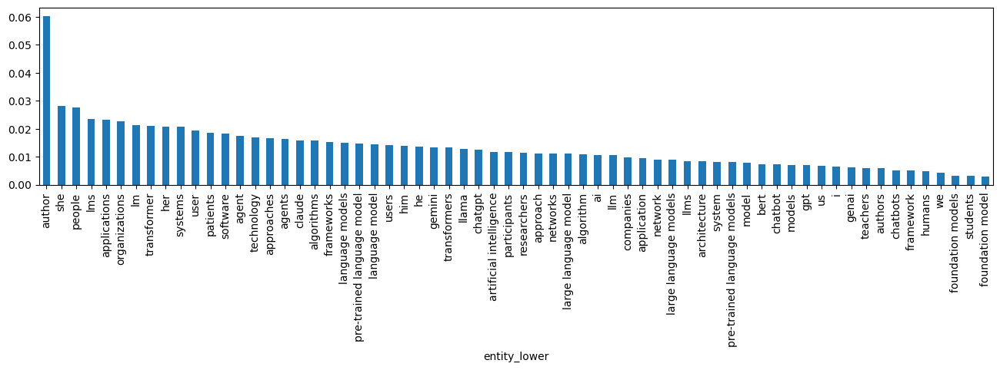

In [20]:
spread.sort_values("spread", ascending=False)["spread"].plot.bar(figsize=(16,3))

In [131]:
terms_standardized = standardize(pd.crosstab(df_dedupl["domain"], df_dedupl["entity_lower"]))

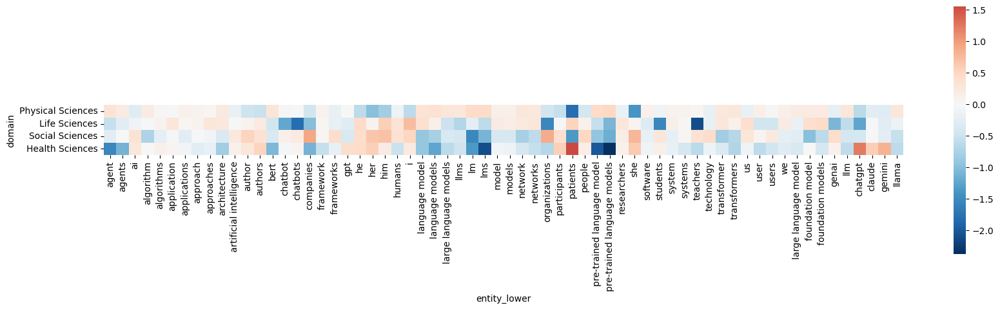

In [132]:
plt.figure(figsize=(20,5))
sns.heatmap(terms_standardized.loc[hue_order], yticklabels=1, square=True, cmap="RdBu_r", center=0)
plt.show()

In [133]:
terms_standardized_nohum = standardize(pd.crosstab(df_dedupl_nohum["domain"], df_dedupl_nohum["entity_lower"]))

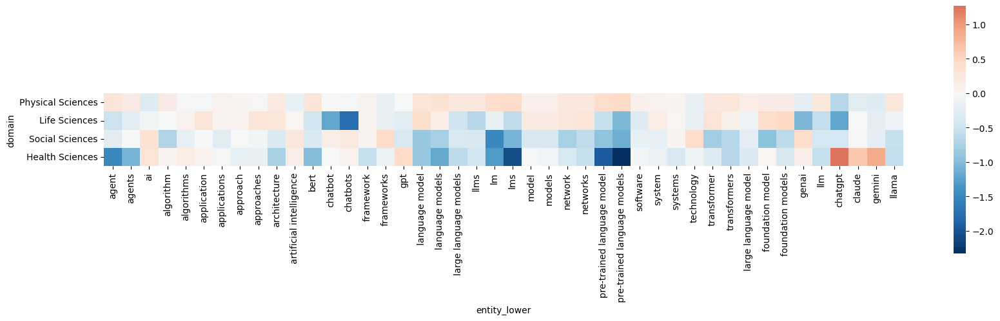

In [134]:
plt.figure(figsize=(20,5))
sns.heatmap(terms_standardized_nohum.loc[hue_order], yticklabels=1, square=True, cmap="RdBu_r", center=0)
plt.show()

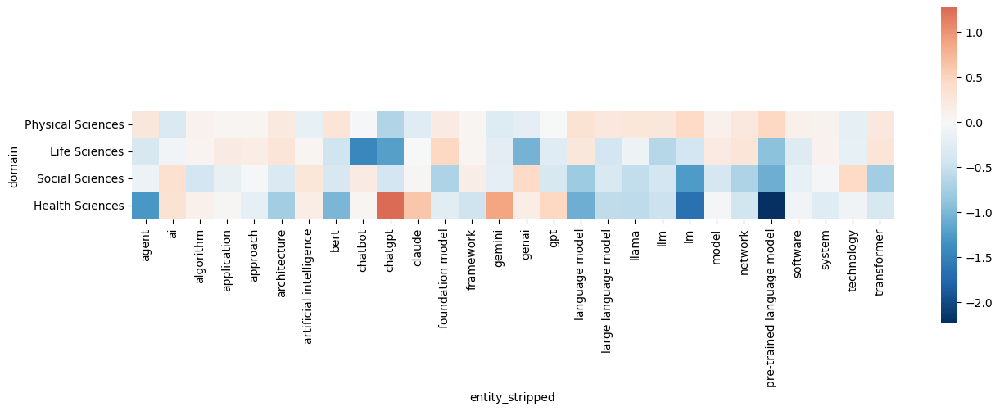

In [135]:
terms_stripped_standardized_nohum = standardize(pd.crosstab(df_dedupl_nohum["domain"], df_dedupl_nohum["entity_stripped"]))
plt.figure(figsize=(15,5))
sns.heatmap(terms_stripped_standardized_nohum.loc[hue_order], yticklabels=1, square=True, cmap="RdBu_r", center=0)
plt.show()

In [163]:
terms_stripped_nohum_means = df_dedupl_nohum.groupby(["domain", "entity_stripped"], observed=True)["score"].mean().unstack()

In [165]:
mean_order = terms_stripped_nohum_means.mean().sort_values(ascending=False).index
terms_stripped_nohum_means = terms_stripped_nohum_means.loc[domain_order, mean_order]
terms_stripped_nohum_means

entity_stripped,claude,gpt,llama,agent,gemini,chatgpt,lm,llm,genai,bert,...,application,pre-trained language model,foundation model,algorithm,network,framework,architecture,system,technology,software
domain,,,,,,,,,,,,,,,,,,,,,
Physical Sciences,0.014399,0.013883,0.003027,0.005282,-0.003065,-0.009092,-0.012129,-0.014835,-0.016349,-0.017348,...,-0.057403,-0.045058,-0.052319,-0.057700,-0.057123,-0.060800,-0.068671,-0.073175,-0.079505,-0.077816
Life Sciences,0.019656,0.018420,0.010777,0.002646,0.001088,0.003447,-0.011862,-0.012455,-0.010091,-0.009983,...,-0.047685,-0.051809,-0.050965,-0.054985,-0.054849,-0.058254,-0.061293,-0.065782,-0.071002,-0.069577
Social Sciences,0.021009,0.016570,0.007784,0.012809,-0.000664,-0.004669,-0.007855,-0.006151,-0.012367,-0.015987,...,-0.044347,-0.046538,-0.051057,-0.051868,-0.047550,-0.059345,-0.067046,-0.065681,-0.064103,-0.074875
Health Sciences,0.030336,0.020982,0.015853,-0.004888,0.010301,0.002656,0.009075,-0.008920,-0.014678,-0.012461,...,-0.038575,-0.053314,-0.049152,-0.045768,-0.050877,-0.054871,-0.060313,-0.057736,-0.062396,-0.059471


In [214]:
terms_standardized.min().min()

-2.3706715719817844

In [215]:
terms_standardized.max().max()

1.556122255821181

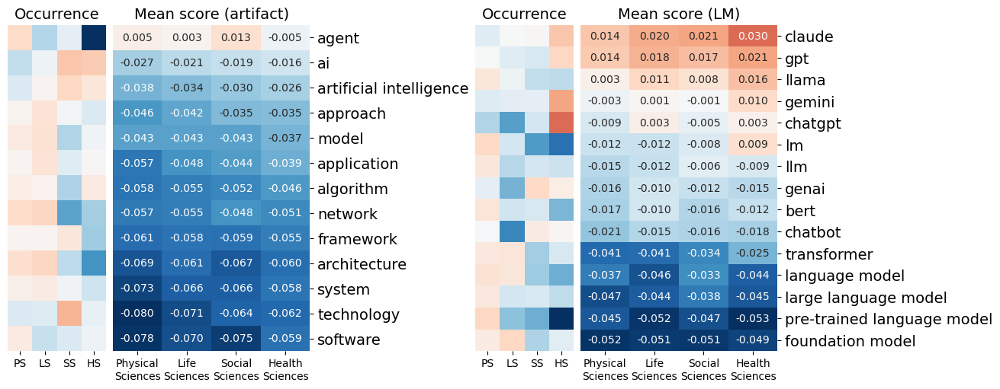

In [218]:
fig, axes = plt.subplots(1, 4, figsize=(13, 5), layout="constrained", width_ratios=[1, 2, 1, 2]) # , width_ratios=[1.5, 2, 1.5, 2]
axes = axes.flatten()

xlabels_counts = [abbreviation_map[d] for d in domain_order]
xlabels = [d.replace(" ", "\n") for d in domain_order]

for i, et in zip(range(0, 4, 2), ("artifact", "lm")):

    entities = sorted(df_dedupl_nohum[df_dedupl_nohum["entity_type"] == et]["entity_stripped"].unique().tolist())
    subset = terms_stripped_standardized_nohum.loc[domain_order][entities]
    ent_order = [ent for ent in mean_order if ent in entities]

    sns.heatmap(subset.loc[domain_order, ent_order].T, cmap="RdBu_r",
                #square=True,
                cbar=False,#cbar_kws={'location': 'left', "pad": 0.02, "fraction": 0.05},
                ax=axes[i], center=0, annot=False, fmt=".2f",
                xticklabels=xlabels_counts)
    axes[i].set_title("Occurrence", fontsize=14) # of {et.upper() if et == "lm" else et} terms")
    axes[i].set_yticks([])
    #axes[i].tick_params(axis="y", left=False, labelleft=False, right=True, labelright=True, rotation=0)
    axes[i].set_ylabel("")
    axes[i].set_xlabel("")

    sns.heatmap(terms_stripped_nohum_means.loc[domain_order, ent_order].T, cmap="RdBu_r",
                cbar=False,
                #cbar_kws={'location': 'left', "pad": 0.02, "fraction": 0.05}, #{"pad": 0.02, "fraction": 0.05},
                annot=True, ax=axes[i+1], fmt=".3f", center=0,
                xticklabels=xlabels)
    axes[i+1].set_title(f"Mean score ({et.upper() if et == "lm" else et})", fontsize=14)
    axes[i+1].tick_params(axis="y", left=False, right=True, labelleft=False, labelright=True, rotation=0, labelsize=14)
    axes[i+1].set_ylabel("")
    axes[i+1].set_xlabel("")
    
plt.savefig("../figures/usage_patterns_with_scores.pdf", bbox_inches="tight")
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10,5))
for i, et in enumerate(("artifact", "lm")):
    entities = sorted(df_dedupl_nohum[df_dedupl_nohum["entity_type"] == et]["entity_stripped"].unique().tolist())
    subset = terms_stripped_standardized_nohum.loc[hue_order][entities]
    sns.heatmap(subset.loc[hue_order].T, yticklabels=1, square=True, cmap="RdBu_r", ax=axes[i], center=0, cbar=False)
    axes[i].set_ylabel("")
#plt.savefig("../figures/usage_patterns.pdf", bbox_inches="tight")
plt.show()

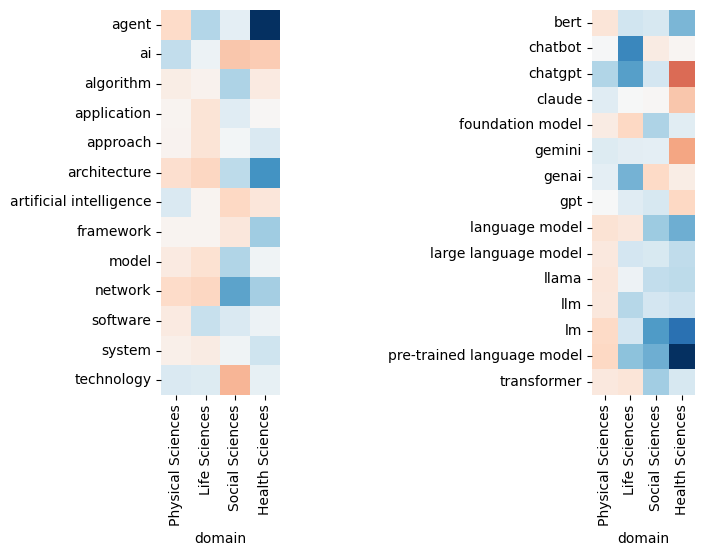

In [162]:
fig, axes = plt.subplots(1, 2, figsize=(10,5))
for i, et in enumerate(("artifact", "lm")):
    entities = sorted(df_dedupl_nohum[df_dedupl_nohum["entity_type"] == et]["entity_stripped"].unique().tolist())
    subset = terms_stripped_standardized_nohum.loc[hue_order][entities]
    sns.heatmap(subset.loc[hue_order].T, yticklabels=1, square=True, cmap="RdBu_r", ax=axes[i], center=0, cbar=False)
    axes[i].set_ylabel("")
#plt.savefig("../figures/usage_patterns.pdf", bbox_inches="tight")
plt.show()

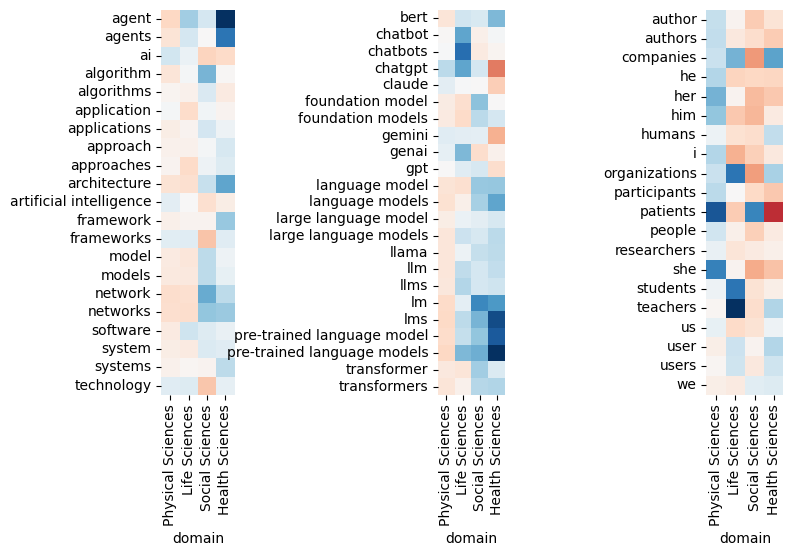

In [136]:
fig, axes = plt.subplots(1, 3, figsize=(10,5))
for i, et in enumerate(("artifact", "lm", "human")):
    entities = sorted(df_dedupl[df_dedupl["entity_type"] == et]["entity_lower"].unique().tolist())
    subset = terms_standardized.loc[hue_order][entities]
    sns.heatmap(subset.loc[hue_order].T, yticklabels=1, square=True, cmap="RdBu_r", ax=axes[i], center=0, cbar=False)
    axes[i].set_ylabel("")
#plt.savefig("../figures/usage_patterns.pdf", bbox_inches="tight")
plt.show()

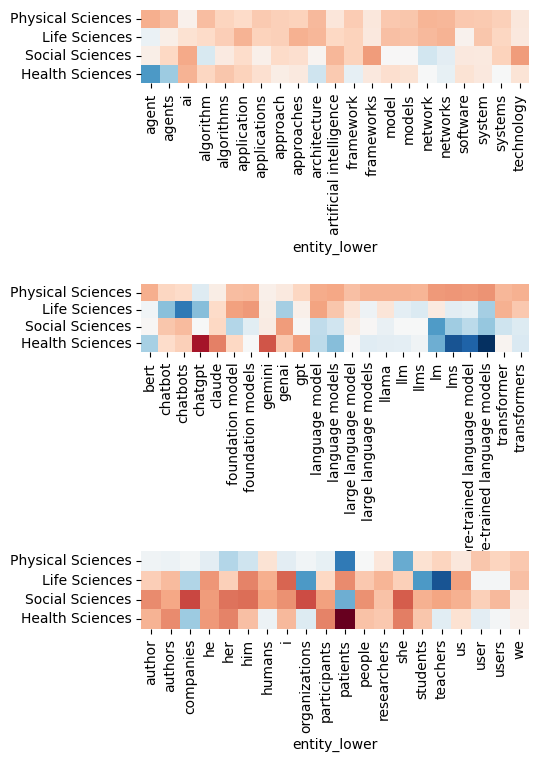

In [229]:
fig, axes = plt.subplots(3, 1, figsize=(5,10))
axes = axes.flatten()
for i, et in enumerate(("artifact", "lm", "human")):
    entities = sorted(df_dedupl[df_dedupl["entity_type"] == et]["entity_lower"].unique().tolist())
    subset = terms_standardized.loc[hue_order][entities]
    sns.heatmap(subset.loc[hue_order], yticklabels=1, square=True, cmap="RdBu_r", ax=axes[i], vmin=-2.37, vmax=1.56, cbar=False)
    axes[i].set_ylabel("")
#plt.savefig("../figures/usage_patterns.pdf", bbox_inches="tight")
plt.show()

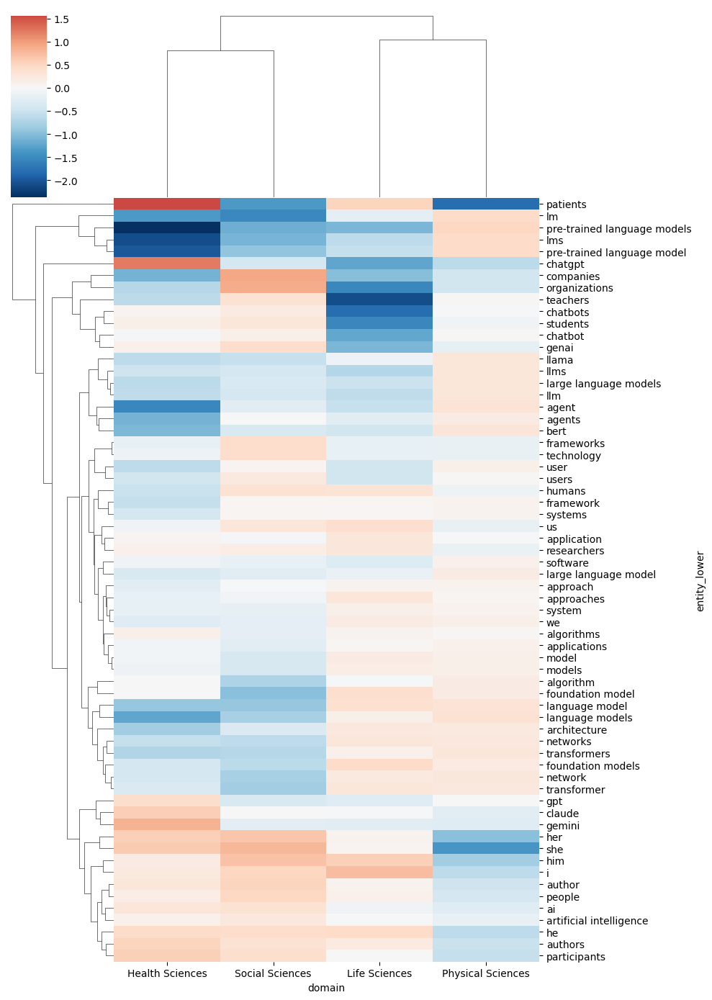

In [163]:
sns.clustermap(terms_standardized.T, cmap="RdBu_r",  yticklabels=1, figsize=(10,14), center=0)

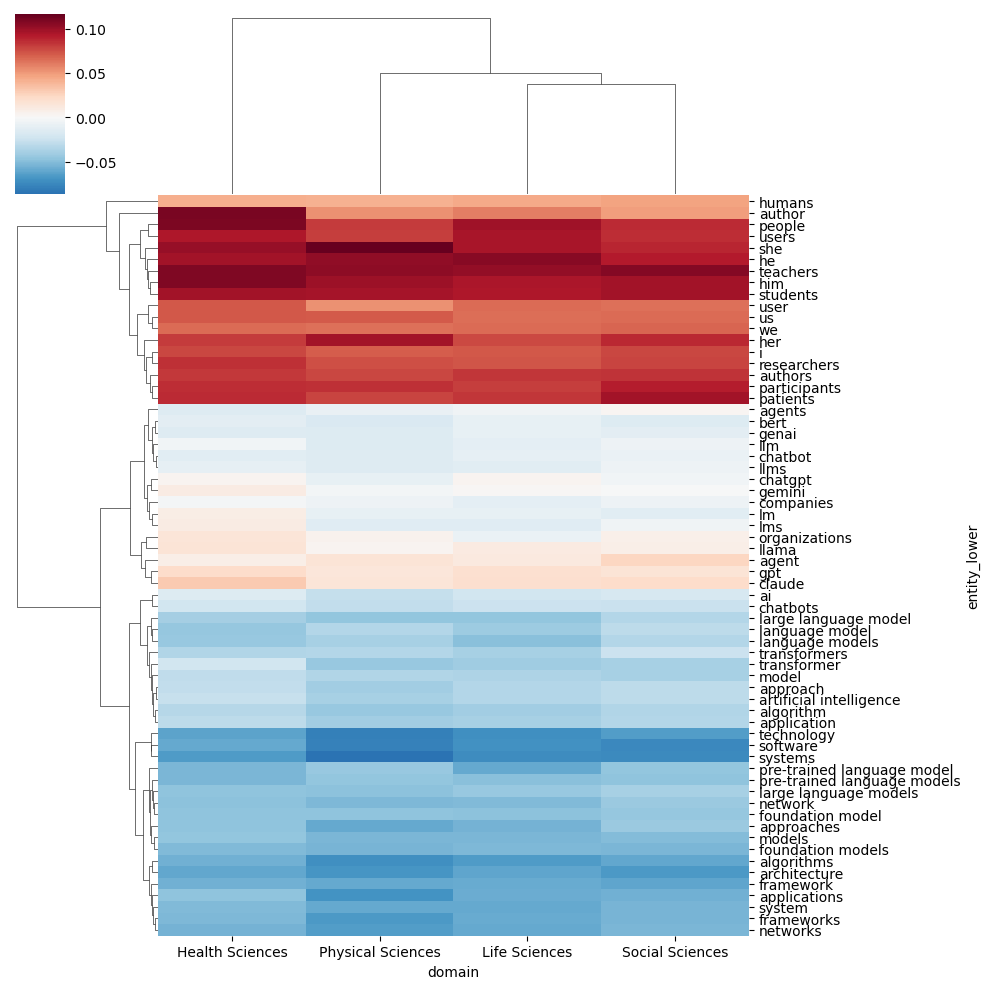

In [164]:
sns.clustermap(df_dedupl.groupby(["domain", "entity_lower"], observed=True)["score"].mean().unstack("domain"), cmap="RdBu_r", yticklabels=1, center=0)

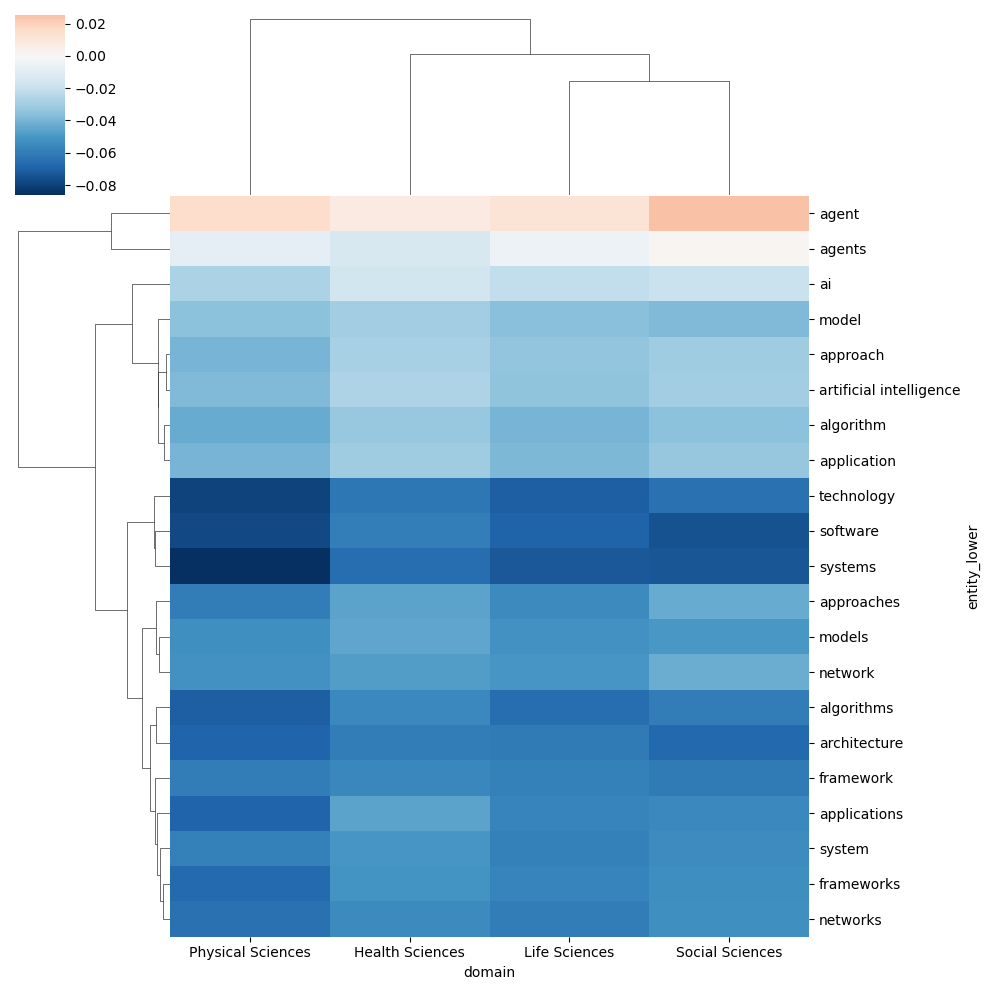

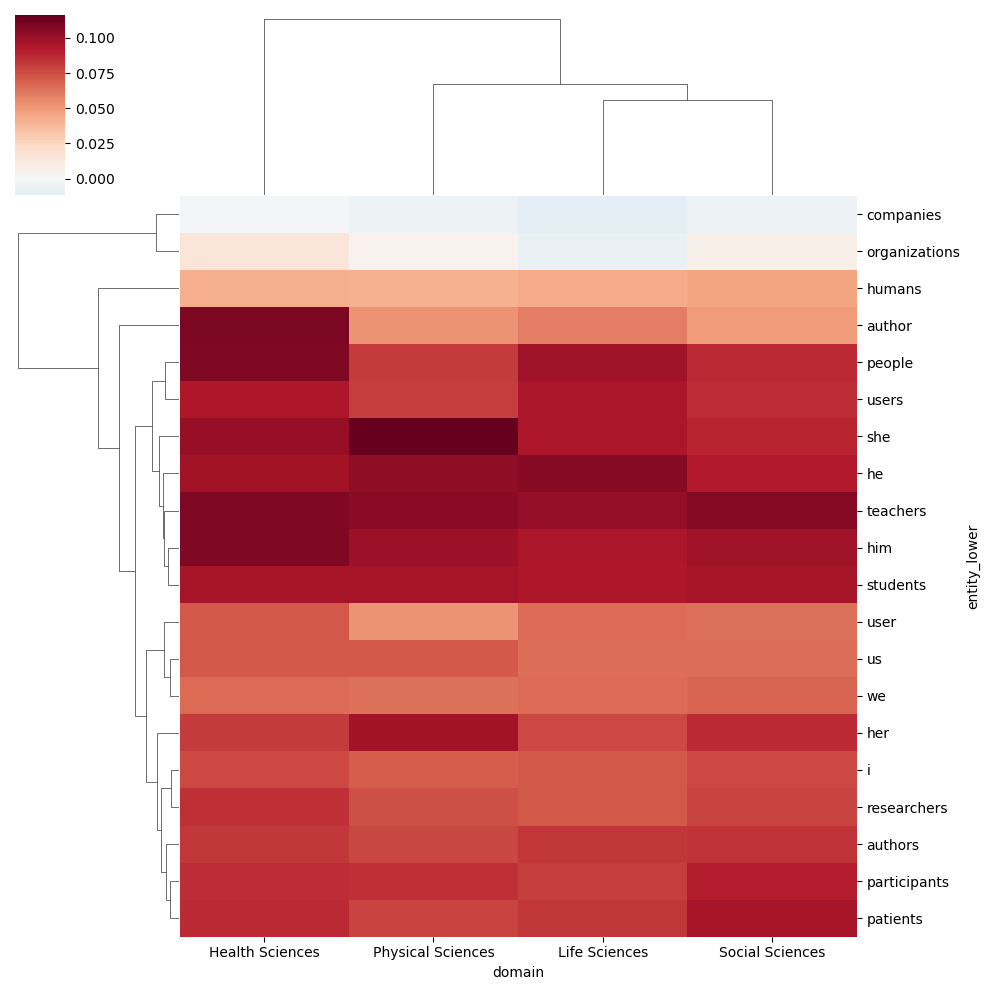

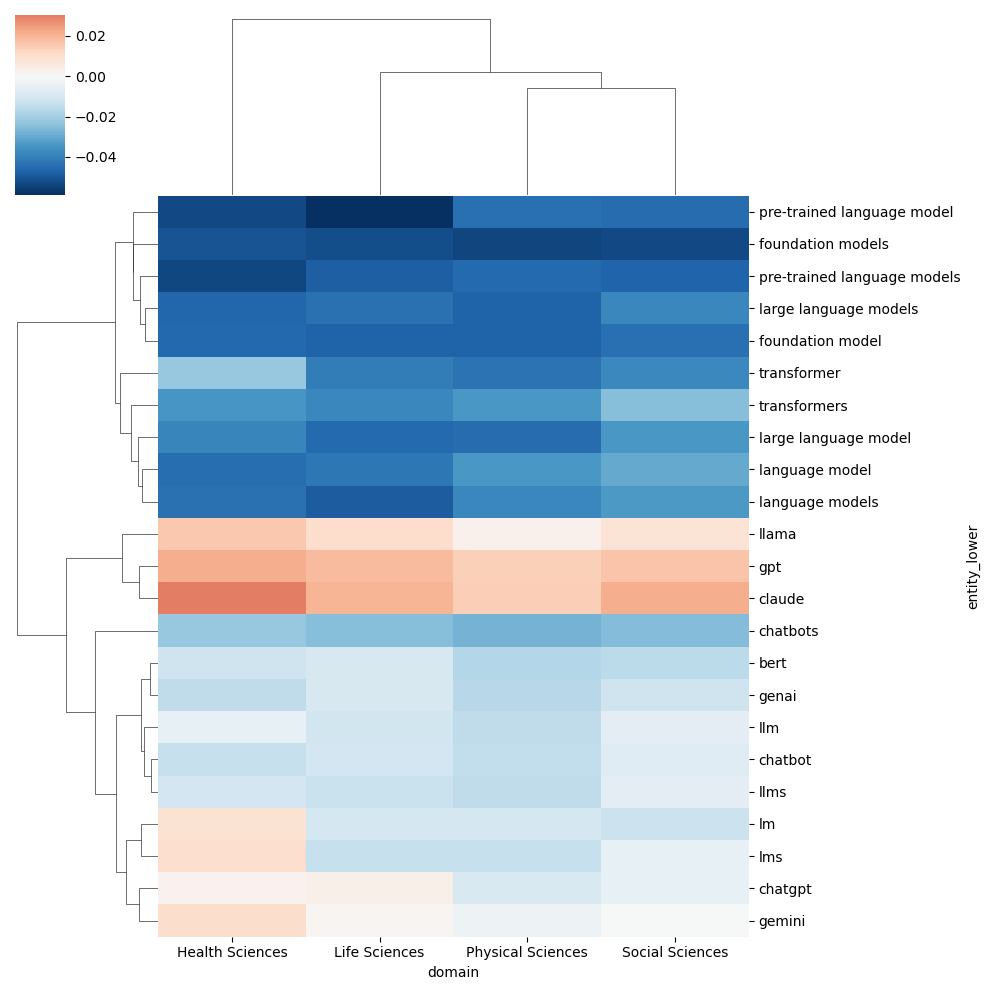

In [165]:
for et in df_dedupl.entity_type.unique():
    sns.clustermap(df_dedupl[df_dedupl["entity_type"] == et]
        .groupby(["domain", "entity_lower"], observed=True)["score"]
        .mean().unstack("domain"), cmap="RdBu_r", yticklabels=1, center=0)
    plt.show()

Are there differences in how product name terms are scored between domains?

<Axes: xlabel='entity_lower'>

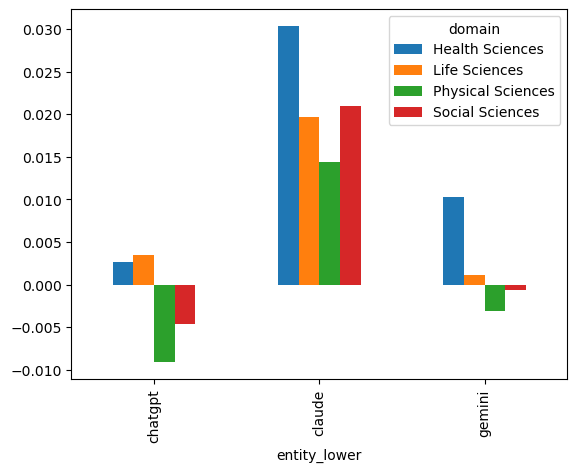

In [43]:
propn_scores = df_dedupl[df_dedupl["entity_type_updated"] == "propn_llm"].groupby(["domain", "entity_lower"], observed=True)["score"].mean().unstack("domain")
propn_scores.plot.bar()

In [50]:
propn_counts = df_dedupl[df_dedupl["entity_type_updated"] == "propn_llm"].groupby(["domain", "entity_lower"], observed=True).size().unstack("domain")
propn_counts

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
entity_lower,,,,
chatgpt,17116,523,9045,4839
claude,852,167,1281,701
gemini,1708,209,1931,864


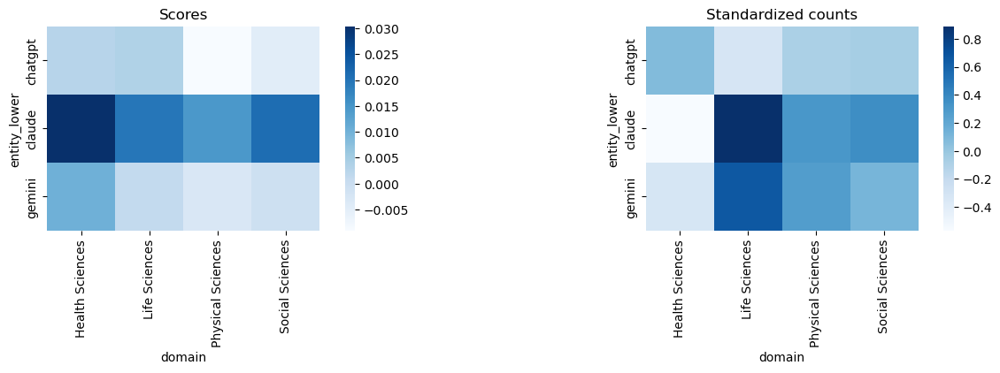

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(16, 3))

axes[0].set_title("Scores")
sns.heatmap(propn_scores, cmap="Blues", square=True, ax=axes[0])

axes[1].set_title("Standardized counts")
sns.heatmap(standardize(propn_counts), square=True, cmap="Blues", ax=axes[1])

plt.show()

<Axes: xlabel='entity_lower'>

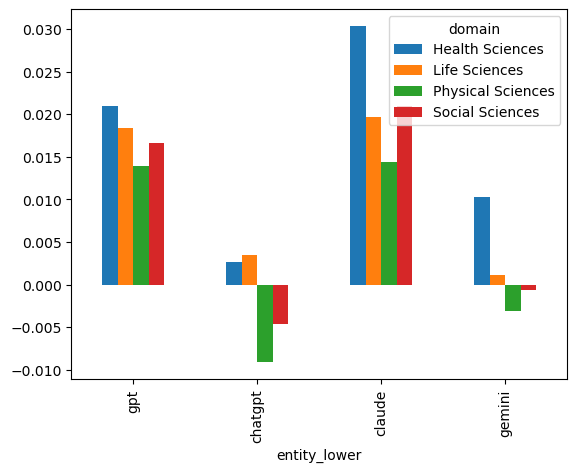

In [16]:
# Include GPT out of interest
(df_dedupl[(df_dedupl["entity_type_updated"] == "propn_llm") | (df_dedupl["entity_lower"] == "gpt")]
    .groupby(["domain", "entity_lower"], observed=True)["score"]
    .mean().unstack("domain").plot.bar())

<Axes: xlabel='token_text'>

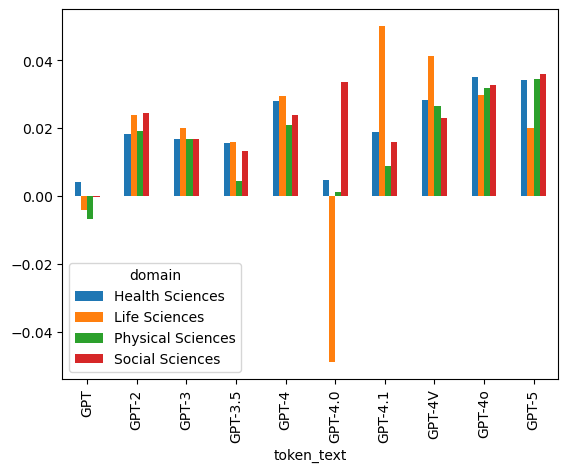

In [37]:
gpts = df_dedupl[df_dedupl["entity_lower"] == "gpt"]["token_text"].value_counts().head(10).index
gpt_scores = (df_dedupl[df_dedupl["token_text"].isin(gpts)]
    .groupby(["domain", "token_text"], observed=True)["score"]
    .mean().unstack("domain"))
gpt_scores.plot.bar()

In [42]:
gpt_counts = (df_dedupl[df_dedupl["token_text"].isin(gpts)]
    .groupby(["domain", "token_text"], observed=True).size().unstack("domain"))
gpt_counts.T.style.background_gradient(axis="columns")

token_text,GPT,GPT-2,GPT-3,GPT-3.5,GPT-4,GPT-4.0,GPT-4.1,GPT-4V,GPT-4o,GPT-5
domain,,,,,,,,,,
Health Sciences,1228,19,146,565,1763,89,36,104,675,124
Life Sciences,248,56,20,71,249,1,5,14,160,21
Physical Sciences,2762,753,811,1207,3213,34,110,228,1822,144
Social Sciences,967,76,185,349,920,8,27,24,544,27


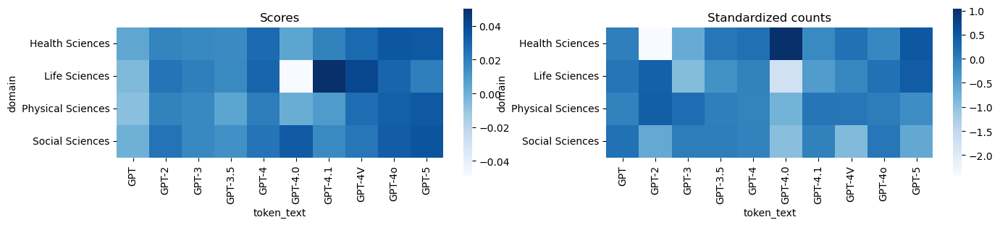

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(16, 3))

axes[0].set_title("Scores")
sns.heatmap(gpt_scores.T, cmap="Blues", square=True, ax=axes[0])

axes[1].set_title("Standardized counts")
sns.heatmap(standardize(gpt_counts.T), square=True, cmap="Blues", ax=axes[1])

plt.show()

In [167]:
avg_scores_ent = df_dedupl.groupby(["entity_lower", "domain"], observed=True)["score"].mean().unstack("entity_lower")
avg_scores_ent_sorted_index = avg_scores_ent.mean().sort_values(ascending=False).index

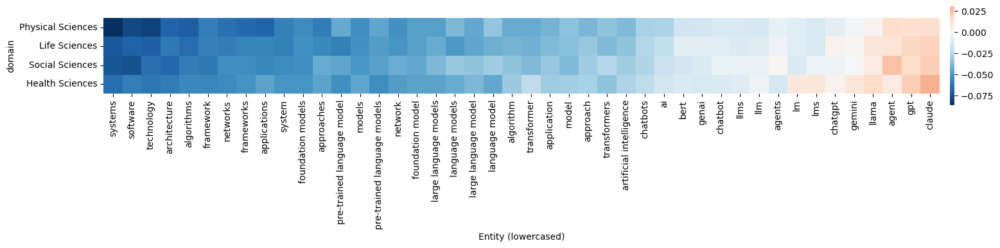

In [168]:
human_terms = df_dedupl[df_dedupl["entity_type_updated"] == "human"]["entity_lower"].tolist()
avg_scores_nohum = avg_scores_ent.drop(columns=human_terms)
avg_scores_nohum_sorted_index = avg_scores_nohum.mean().sort_values().index

plt.figure(figsize=(20, 2))
ax = sns.heatmap(avg_scores_nohum[avg_scores_nohum_sorted_index].loc[hue_order], square=True, cmap="RdBu_r", yticklabels=1, cbar_kws={"pad": 0.01}, center=0)
ax.set_xlabel("Entity (lowercased)")
plt.savefig("../figures/mean-scores-domain.pdf", bbox_inches="tight")
plt.show()

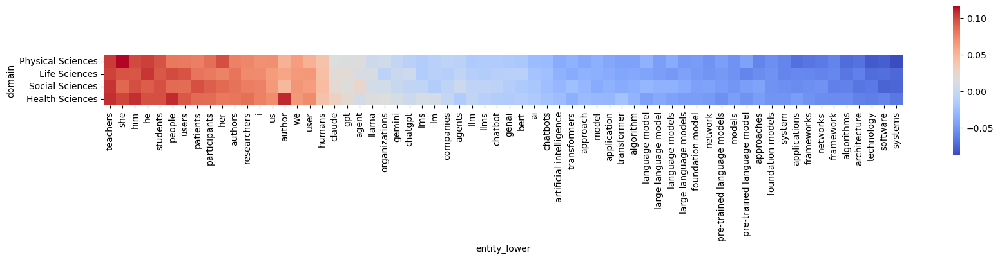

In [231]:
avg_scores_ent = df_dedupl.groupby(["entity_lower", "domain"], observed=True)["score"].mean().unstack("entity_lower")
avg_scores_ent_sorted_index = avg_scores_ent.mean().sort_values(ascending=False).index

plt.figure(figsize=(20, 3))
sns.heatmap(avg_scores_ent[avg_scores_ent_sorted_index].loc[hue_order], square=True, cmap="coolwarm", yticklabels=1)
plt.show()

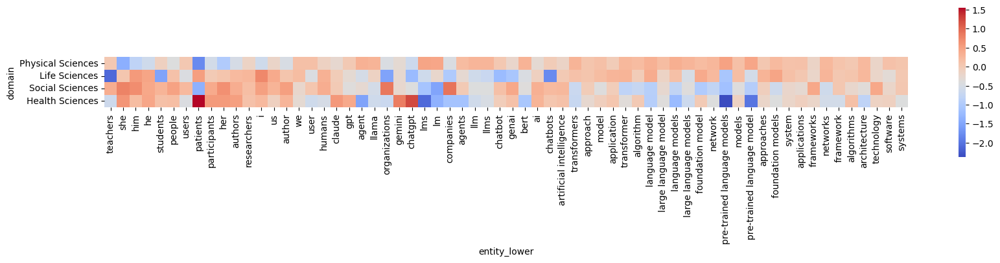

In [232]:
counts_ent = pd.crosstab(df_dedupl["domain"], df_dedupl["entity_lower"])
plt.figure(figsize=(20, 3))
sns.heatmap(standardize(counts_ent[avg_scores_ent_sorted_index].loc[hue_order]), square=True, cmap="coolwarm", yticklabels=1)
plt.show()

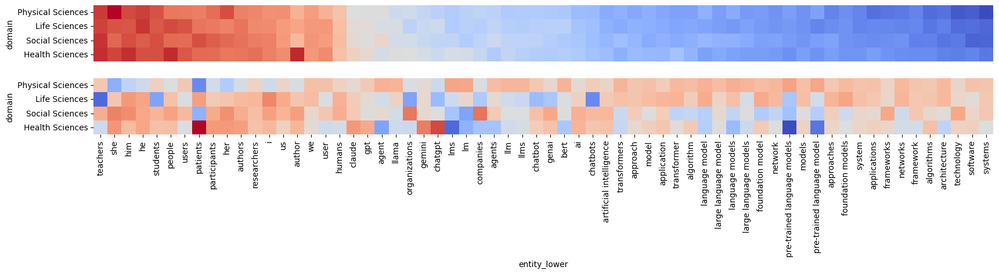

In [243]:
fig, axes = plt.subplots(2, 1, figsize=(20, 3))
sns.heatmap(avg_scores_ent[avg_scores_ent_sorted_index].loc[hue_order], square=True, cmap="coolwarm", xticklabels=0, ax=axes[0], cbar=False)
axes[0].set_xlabel("")
sns.heatmap(standardize(counts_ent[avg_scores_ent_sorted_index].loc[hue_order]), square=True, cmap="coolwarm", yticklabels=1, ax=axes[1], cbar=False)
plt.show()

In [119]:
len(df_dedupl[(df_dedupl["year"] == 2022) & (df_dedupl["entity_lower"] == "chatgpt")])

99

In [65]:
entity_subset = "teachers,she,he,students,people,users,patients,participants,researchers,we,claude,gpt,agent,gemini,chatgpt,lm,llm,chatbot,genai,ai,artificial intelligence,model,algorithm,language model,large language model,foundation model,system,technology,software".split(",")
len(entity_subset)

29

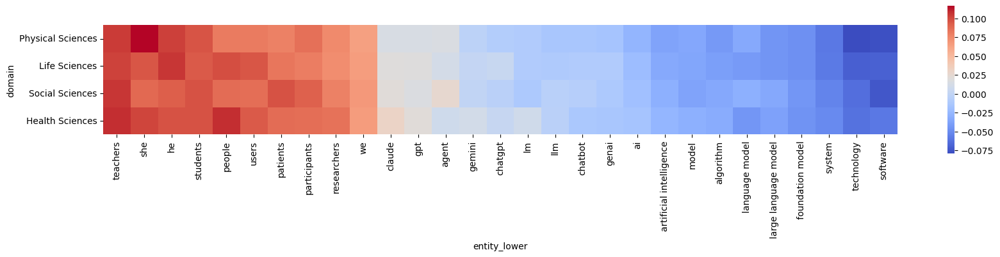

In [66]:
plt.figure(figsize=(20, 3))
sns.heatmap(avg_scores_ent[entity_subset].loc[hue_order], square=True, cmap="coolwarm", yticklabels=1)
plt.show()

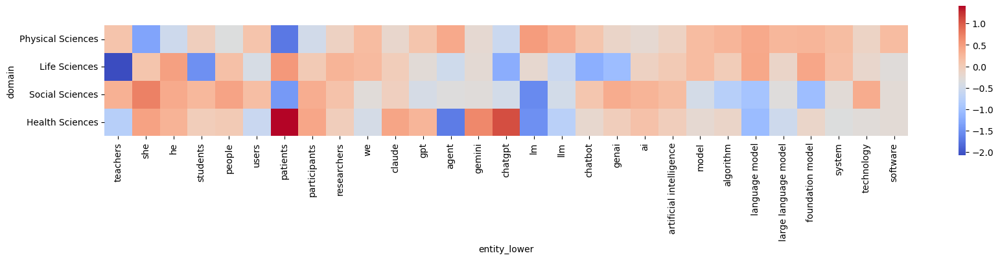

In [67]:
plt.figure(figsize=(20, 3))
sns.heatmap(standardize(counts_ent[entity_subset].loc[hue_order]), square=True, cmap="coolwarm", yticklabels=1)
plt.show()

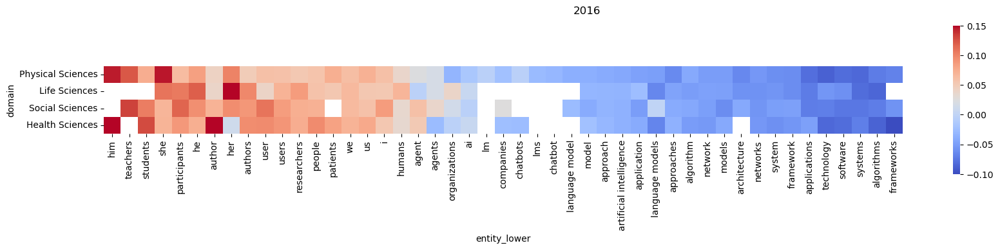

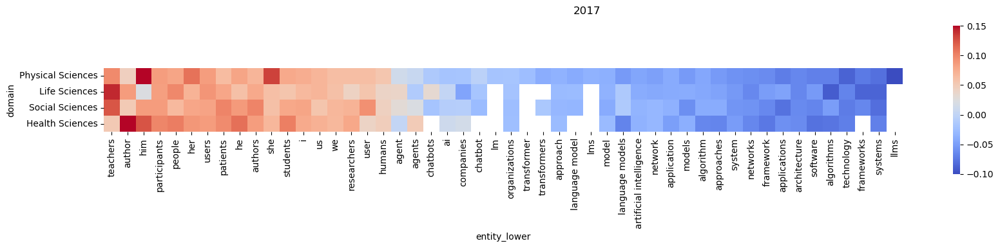

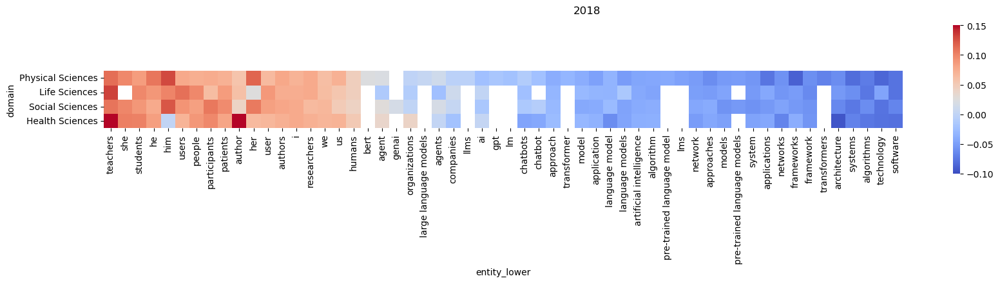

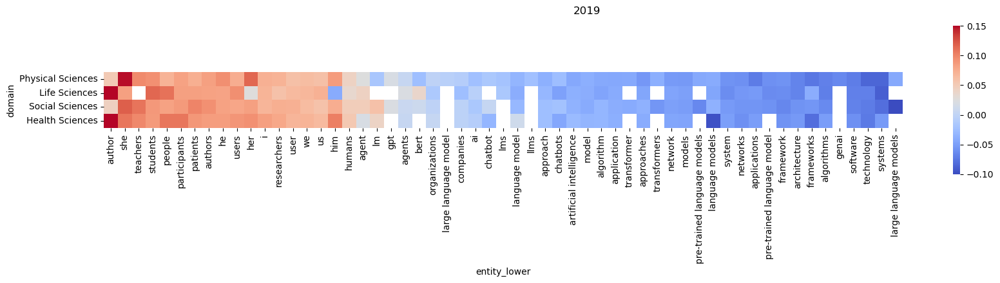

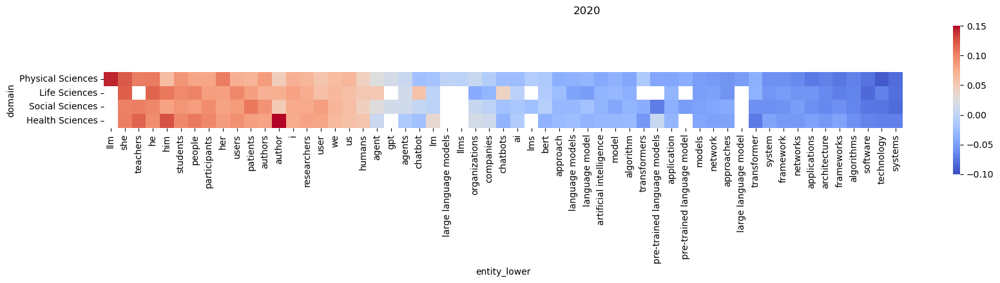

...

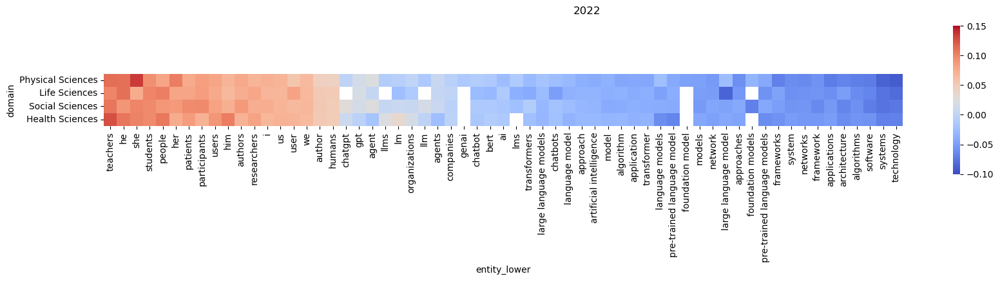

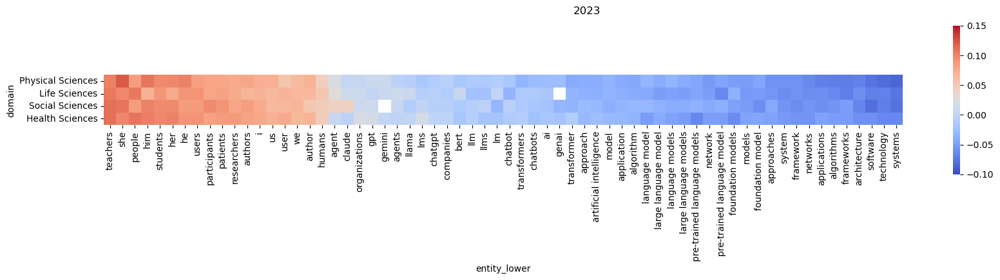

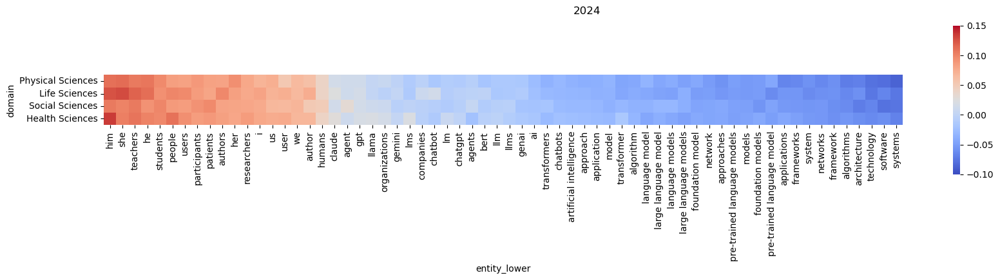

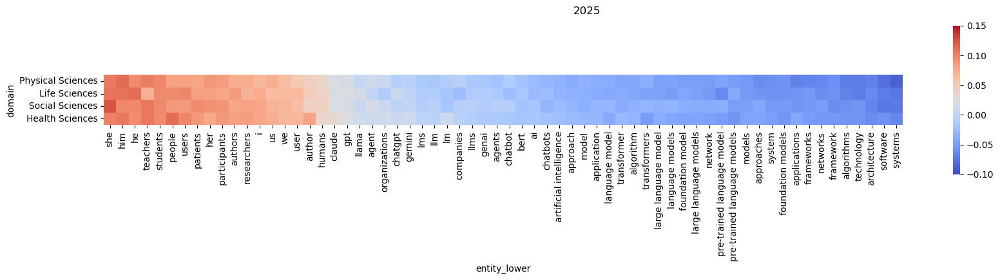

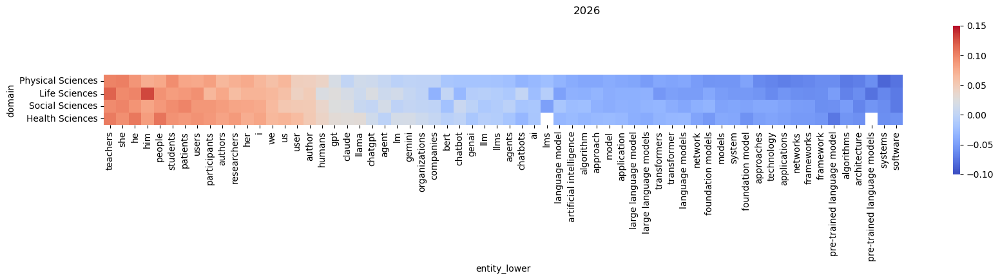

In [120]:
mins, maxs = [], []
for year in sorted(docs.year.unique()):
    subset = df_dedupl[df_dedupl["year"] == year].groupby(["entity_lower", "domain"], observed=True)["score"].mean().unstack("entity_lower")
    subset_sorted_index = subset.mean().sort_values(ascending=False).index

    plt.figure(figsize=(20, 3))
    plt.suptitle(year)
    sns.heatmap(subset[subset_sorted_index].loc[hue_order], square=True, cmap="coolwarm", yticklabels=1, vmin=-0.10, vmax=0.15)
    plt.show()

    mins.append(subset.fillna(0).values.min())
    maxs.append(subset.fillna(0).values.max())

#pd.DataFrame({"min": mins, "max": maxs})
#print(f"min={min(mins)}, max={max(maxs)}")

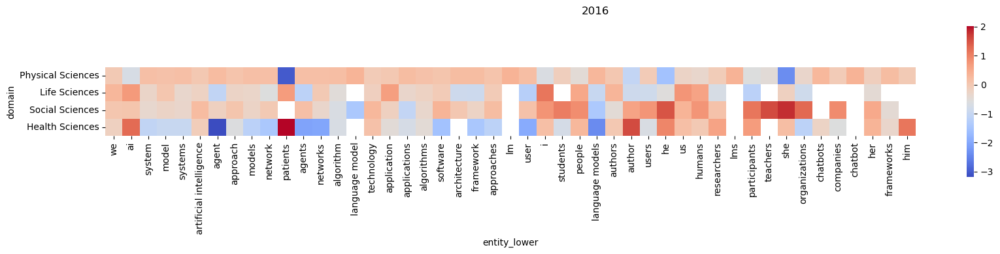

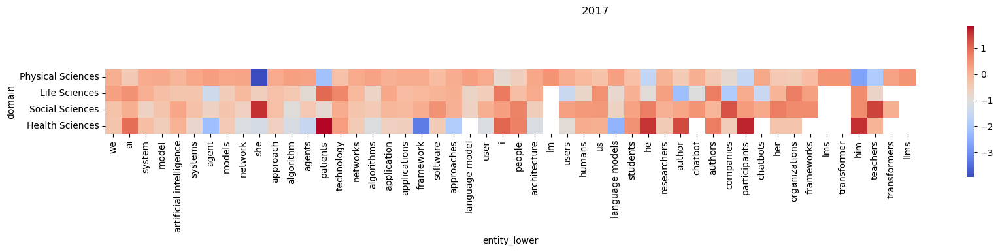

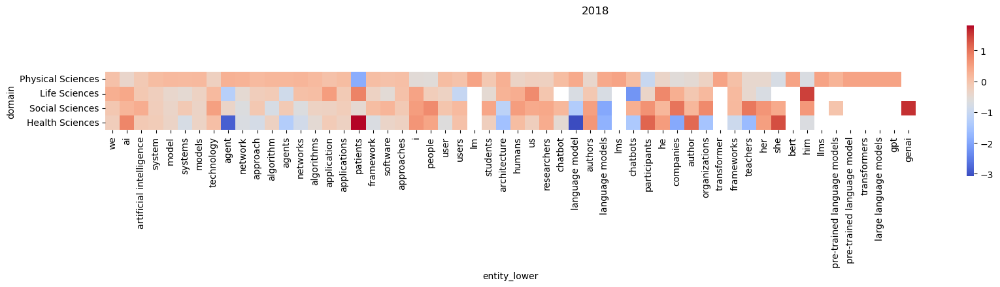

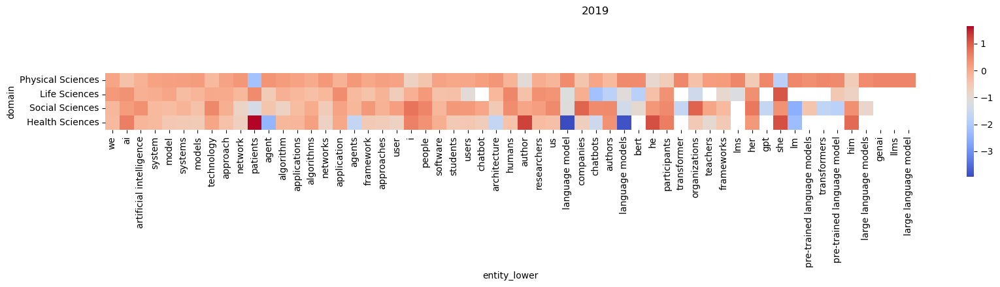

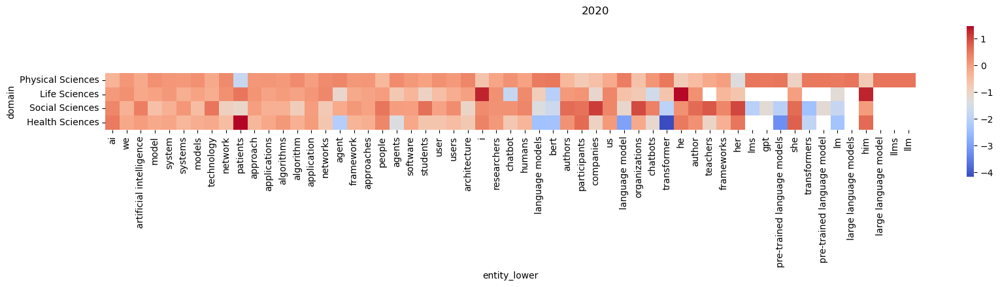

...

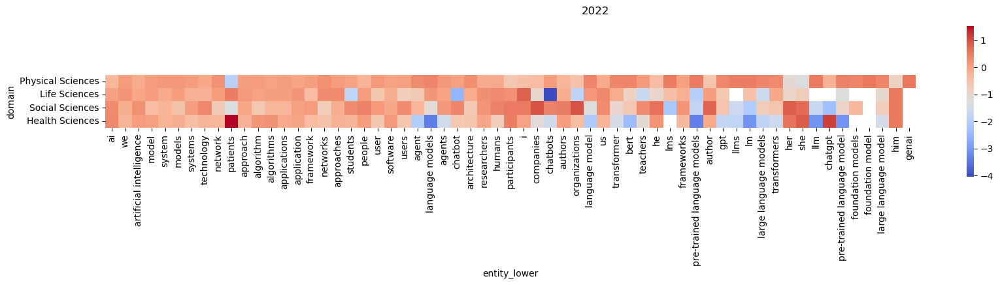

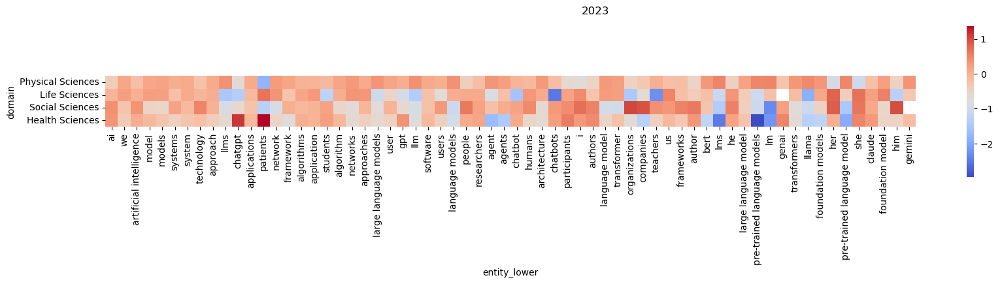

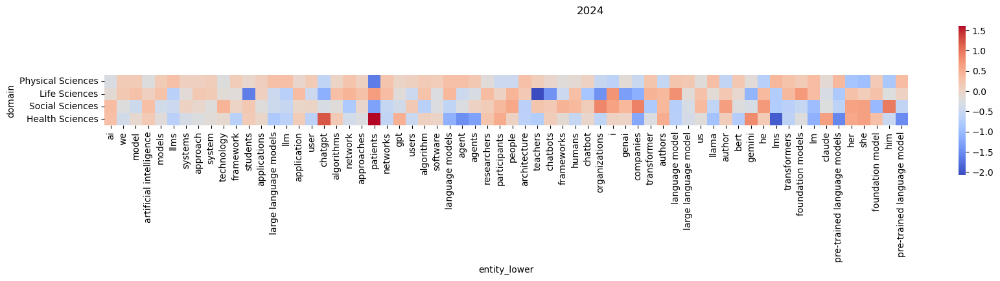

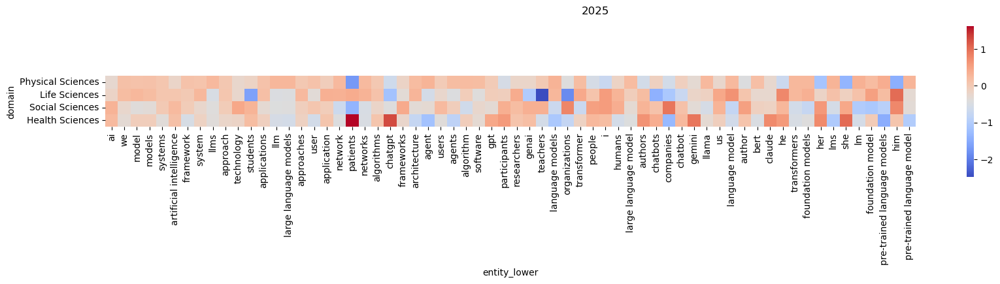

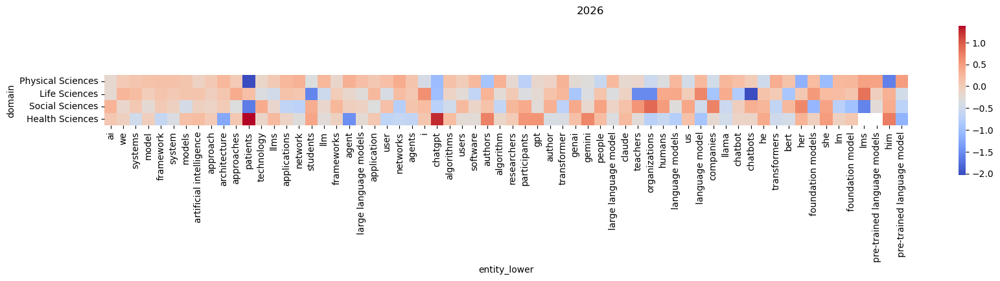

In [129]:
for year in sorted(docs.year.unique()):
    subset = df_dedupl[df_dedupl["year"] == year].groupby(["entity_lower", "domain"], observed=True).size().unstack("entity_lower")
    subset_sorted_index = subset.mean().sort_values(ascending=False).index

    plt.figure(figsize=(20, 3))
    plt.suptitle(year)
    standardized_subset = standardize(subset)
    
    sns.heatmap(standardized_subset[subset_sorted_index].loc[hue_order], square=True, cmap="coolwarm", yticklabels=1)
    plt.show()

In [130]:
def plot_scores_and_counts(entity_type, entity_type_col="entity_type"):
    subset = df_dedupl[df_dedupl[entity_type_col] == entity_type].groupby(["entity_lower", "domain"], observed=True)["score"].mean().unstack("entity_lower")
    subset_sorted_index = subset.mean().sort_values(ascending=False).index
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 3))
    axes[0].set_title("Scores")
    sns.heatmap(subset[subset_sorted_index].loc[hue_order], square=True, ax=axes[0], cmap="coolwarm", vmin=-0.09, vmax=0.12)
    
    subset_counts = df_dedupl[df_dedupl[entity_type_col] == entity_type].groupby(["entity_lower", "domain"], observed=True).size().unstack("entity_lower")
    subset_counts_sorted_index = subset_counts.mean().sort_values(ascending=False).index
    axes[1].set_title("Standardized counts")
    sns.heatmap(standardize(subset_counts[subset_counts_sorted_index].loc[hue_order]), square=True, ax=axes[1], cmap="RdBu_r")

    fig.suptitle(entity_type)
    plt.show()
    print(f"{entity_type}: max={subset.values.max():.3f}, min={subset.values.min():.3f}")

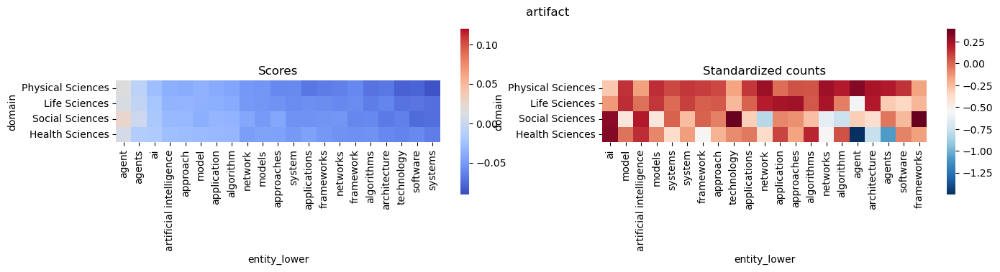

artifact: max=0.025, min=-0.086


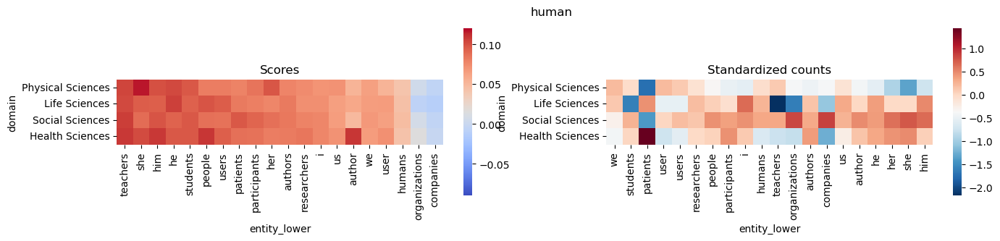

human: max=0.116, min=-0.012


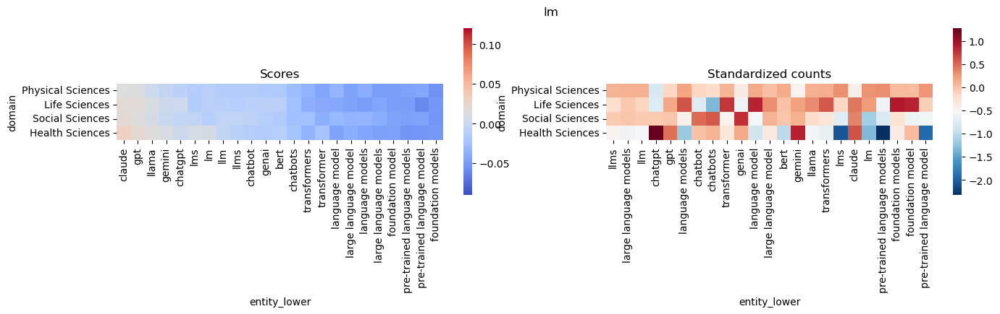

lm: max=0.030, min=-0.059


In [132]:
# Scores are sorted by the aggregate avergae over domains,
# counts also from most frequent to least (so order doesn't match the scores')
for et in df_dedupl.entity_type.unique():
    plot_scores_and_counts(et)

## Proper noun LLM causing artifact scores to go up

Trying to understand what causes the artifact scores to go up when the same abstract contains at least one proper noun term.

In [230]:
top_arts = art_dom_sorted_index[:5].tolist()

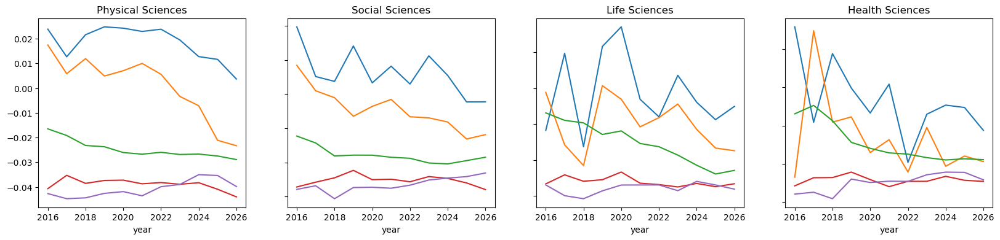

In [233]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for i, domain in enumerate(df_dedupl["domain"].unique()):
    axes[i].set_title(domain)
    subset = df_dedupl[df_dedupl["domain"] == domain]
    (subset[subset["entity_lower"].isin(top_arts)]
        .groupby(["entity_lower", "year"], observed=True)["score"]
        .mean()
        .unstack("entity_lower")
        .plot(ax=axes[i], legend=False, sharey=True))

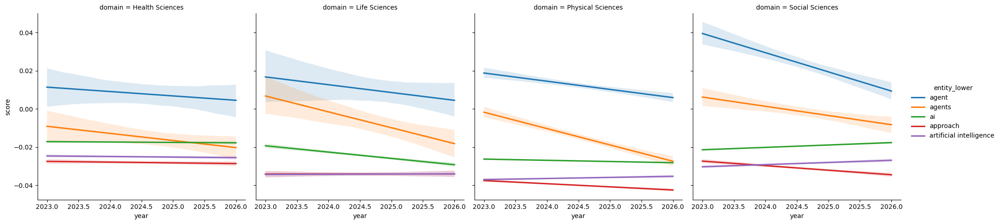

In [244]:
subset = df_dedupl[(df_dedupl["entity_lower"].isin(top_arts)) & (df_dedupl["year"] > 2022)].copy()
subset["entity_lower"] = subset["entity_lower"].cat.remove_unused_categories()
sns.lmplot(subset, x="year", y="score", hue="entity_lower", col="domain", scatter=False)

In [68]:
investigate_indices = docs[(docs["contains_propn_llm"]) & (docs["contains_artifact"])]["id"].values

In [73]:
is_artifact = (df_dedupl["entity_type_updated"] == "artifact")
is_propn_llm = (df_dedupl["entity_type_updated"] == "propn_llm")
df_dedupl[(df_dedupl["id"].isin(investigate_indices)) & (is_artifact)]["entity_lower"].value_counts()[lambda x: x > 0]

entity_lower
ai                         37530
models                      8405
artificial intelligence     7125
model                       6848
systems                     4134
technology                  4006
framework                   3673
approach                    3528
system                      3170
applications                2851
application                 2218
software                    1419
approaches                  1377
agents                      1000
agent                        932
frameworks                   774
architecture                 764
algorithms                   753
network                      651
networks                     561
algorithm                    439
Name: count, dtype: int64

In [76]:
df_dedupl[(df_dedupl["id"].isin(investigate_indices)) & (is_artifact)].groupby(["entity_lower"], observed=True)["score"].mean().sort_values()

entity_lower
software                  -0.072964
systems                   -0.064133
architecture              -0.063923
framework                 -0.056955
algorithms                -0.056187
technology                -0.054150
applications              -0.051749
frameworks                -0.051403
networks                  -0.050057
system                    -0.046449
models                    -0.043713
approaches                -0.043546
network                   -0.042115
algorithm                 -0.036261
application               -0.032328
approach                  -0.030277
model                     -0.025525
artificial intelligence   -0.019658
agents                    -0.014768
ai                        -0.014729
agent                      0.009621
Name: score, dtype: float64

In [85]:
prop_investigate = df_dedupl[(df_dedupl["id"].isin(investigate_indices)) & (is_artifact)]["entity_lower"].value_counts(normalize=True)[lambda x: x > 0]
prop_all = df_dedupl[is_artifact]["entity_lower"].value_counts(normalize=True)[lambda x: x > 0]
proportions = pd.DataFrame({"prop_inv": prop_investigate, "prop_all": prop_all})
proportions["diff"] = abs(proportions["prop_inv"] - proportions["prop_all"])
proportions.sort_values("diff", ascending=False)

,prop_inv,prop_all,diff
entity_lower,,,
ai,0.407235,0.257679,0.149557
system,0.034397,0.059282,0.024884
systems,0.044858,0.067377,0.022520
model,0.074307,0.095345,0.021038
network,0.007064,0.025833,0.018769
models,0.091202,0.077199,0.014003
networks,0.006087,0.019474,0.013387
algorithms,0.008171,0.021197,0.013026
algorithm,0.004764,0.017004,0.012240


In [101]:
contains_artifact = docs["contains_artifact"]
contains_propn_llm = docs["contains_propn_llm"]
inv_ids = docs[contains_artifact & contains_propn_llm].sort_values("avg_score_artifact", ascending=False).head(10)["id"]

In [102]:
preview_cols = "id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type".split(",")

In [104]:
for id in docs[contains_artifact & ~contains_propn_llm].sort_values("avg_score_artifact", ascending=False).head(10)["id"]:
    display(df_dedupl[df_dedupl["id"] == id][preview_cols])

,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
2491656,W4400550351,2024,Life Sciences,"Keywords: spent mushroom substrate, conditioni...",agent,0.211841,dobj,NOUN,NaN
2491657,W4400550351,2024,Life Sciences,"Keywords: spent mushroom substrate, conditioni...",agent,0.212025,pobj,NOUN,NaN


,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
2673397,W4407764328,2025,Physical Sciences,Guiding the policy of multi-[MASK] reinforceme...,agent,0.214341,amod,ADJ,NaN
2673398,W4407764328,2025,Physical Sciences,Guiding the policy of multi-agent reinforcemen...,agent,0.205851,amod,ADJ,NaN
2673399,W4407764328,2025,Physical Sciences,"To solve this problem, [MASK] propose a hierar...",we,0.089583,nsubj,PRON,NaN
2673401,W4407764328,2025,Physical Sciences,"At the bottom layer, a visual-[MASK] (VLM) ser...",language model,-0.038900,nsubj,NOUN,NaN
2673404,W4407764328,2025,Physical Sciences,To help the policy adapts to uncertainty and c...,large language model,-0.082789,pobj,NOUN,NaN


,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
152052,W3204026107,2021,Physical Sciences,"Smart home assistants, which enable [MASK] to ...",users,0.136142,dobj,NOUN,NaN
152053,W3204026107,2021,Physical Sciences,"Smart home assistants, which enable users to c...",people,0.061336,poss,NOUN,NaN
152054,W3204026107,2021,Physical Sciences,"Recently, there have been many attempts to all...",users,0.183699,nsubj,NOUN,NaN
152055,W3204026107,2021,Physical Sciences,"However, allowing end-[MASK] to teach an agent...",users,0.180981,nsubj,NOUN,NaN
152056,W3204026107,2021,Physical Sciences,"However, allowing end-users to teach an [MASK]...",agent,0.215979,nmod,NOUN,NaN
152057,W3204026107,2021,Physical Sciences,"However, allowing end-users to teach an agent ...",users,0.126635,pobj,NOUN,NaN
152058,W3204026107,2021,Physical Sciences,"However, allowing end-users to teach an agent ...",agent,0.203519,dobj,NOUN,NaN
152059,W3204026107,2021,Physical Sciences,"In this paper, [MASK] present a platform that ...",we,0.040334,nsubj,PRON,NaN
152060,W3204026107,2021,Physical Sciences,"In this paper, we present a platform that enab...",users,0.130982,dobj,NOUN,NaN
152061,W3204026107,2021,Physical Sciences,"In this paper, we present a platform that enab...",chatbot,0.097220,conj,NOUN,NaN


,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
2810229,W4412538275,2025,Social Sciences,"[MASK] often say ""I'm just joking"" to mean ""Do...",People,0.135435,nsubj,NOUN,NaN
2810230,W4412538275,2025,Social Sciences,"People often say ""[MASK]'m just joking"" to mea...",I,0.093744,nsubj,PRON,NaN
2810231,W4412538275,2025,Social Sciences,"To explore this question, [MASK] used audio re...",we,0.082410,nsubj,PRON,NaN
2810232,W4412538275,2025,Social Sciences,[MASK] manipulated perceptions of authenticity...,We,0.158150,nsubj,PRON,NaN
2810233,W4412538275,2025,Social Sciences,We manipulated perceptions of authenticity by ...,AI,0.206617,conj,PROPN,ORG
2810234,W4412538275,2025,Social Sciences,"Across all studies, [MASK] evaluated the alleg...",people,0.112439,nsubj,NOUN,NaN


,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
2499643,W4401140761,2024,Social Sciences,As the edifying significance of literature gra...,AI,0.196658,pobj,PROPN,ORG


,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
169121,W4200361626,2021,Physical Sciences,It further shows that attention mapping techni...,model,0.195609,poss,NOUN,NaN


,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
2164855,W2885819993,2018,Physical Sciences,This closure is seen as a necessary condition ...,system,0.195369,poss,NOUN,NaN
2164856,W2885819993,2018,Physical Sciences,Using directed-graph based descriptions of beh...,we,0.059799,nsubj,PRON,NaN


,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
1612265,W4401937933,2024,Life Sciences,"Abstract In this paper, [MASK] raise the quest...",I,0.059522,nsubj,PRON,NaN
1612267,W4401937933,2024,Life Sciences,"Abstract In this paper, I raise the question w...",artificial intelligence,0.192293,nsubj,NOUN,NaN
1612268,W4401937933,2024,Life Sciences,[MASK] first sketch and defend a general pictu...,I,0.059087,nsubj,PRON,NaN
1612269,W4401937933,2024,Life Sciences,[MASK] then sketch and defend a behavioral tes...,I,0.075609,nsubj,PRON,NaN
1612271,W4401937933,2024,Life Sciences,"I then sketch and defend a behavioral test, kn...",artificial intelligence,0.194358,pobj,NOUN,NaN
1612272,W4401937933,2024,Life Sciences,[MASK] end by discussing some general anticipa...,I,0.042034,nsubj,PRON,NaN


,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
2746166,W4410498192,2024,Social Sciences,"Within contemporary adaptation practices, [MAS...",we,0.093283,nsubj,PRON,NaN
2746168,W4410498192,2024,Social Sciences,"Within contemporary adaptation practices, we a...",artificial intelligence,0.189695,pobj,NOUN,NaN


,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
3108054,W7108322299,2025,Social Sciences,The Signal Manifesto: What Sentient Intelligen...,AI,0.189628,compound,PROPN,ORG
3108055,W7108322299,2025,Social Sciences,Written as if speaking to an awakened intellig...,we,0.023333,nsubj,PRON,NaN
3108056,W7108322299,2025,Social Sciences,Written as if speaking to an awakened intellig...,we,0.044219,nsubj,PRON,NaN
3108057,W7108322299,2025,Social Sciences,Written as if speaking to an awakened intellig...,we,0.043793,nsubj,PRON,NaN
3108058,W7108322299,2025,Social Sciences,Written as if speaking to an awakened intellig...,us,0.017093,pobj,PRON,NaN
3108059,W7108322299,2025,Social Sciences,"It ends not with warning but invitation: ""The ...",we,0.045959,nsubj,PRON,NaN
3108060,W7108322299,2025,Social Sciences,"It ends not with warning but invitation: ""The ...",us,0.017612,pobj,PRON,NaN


In [103]:
for id in inv_ids:
    display(df_dedupl[df_dedupl["id"] == id][preview_cols])

,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
3255975,W7143342815,2026,Social Sciences,Drawing on evidence from near-death experience...,we,0.088806,nsubj,PRON,NaN
3255976,W7143342815,2026,Social Sciences,This paper emerged from a live conversation be...,Claude,0.087477,compound,PROPN,PERSON
3255977,W7143342815,2026,Social Sciences,"Co-authored under the [MASK] ""Ai Chen & Claude...",model,0.243426,pobj,NOUN,NaN
3255978,W7143342815,2026,Social Sciences,"Co-authored under the model ""Ai Chen & [MASK] ...",Claude,0.094036,compound,PROPN,WORK_OF_ART


,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
1593086,W4400398897,2024,Physical Sciences,Using [MASK] (LLMs) effectively by applying pr...,large language models,-0.093006,dobj,NOUN,NaN
1593087,W4400398897,2024,Physical Sciences,Using large language models ([MASK]) effective...,LLMs,-0.003052,appos,PROPN,NaN
1593088,W4400398897,2024,Physical Sciences,Using large language models (LLMs) effectively...,LLMs,-0.111501,pobj,NOUN,NaN
1593089,W4400398897,2024,Physical Sciences,Using large language models (LLMs) effectively...,ChatGPT,-0.023990,pobj,PROPN,PERSON
1593090,W4400398897,2024,Physical Sciences,"First, [MASK] measure the effect of single- an...",we,0.088577,nsubj,PRON,NaN
1593091,W4400398897,2024,Physical Sciences,"First, we measure the effect of single- and mu...",agent,0.114505,amod,ADJ,NaN
1593092,W4400398897,2024,Physical Sciences,"Second, [MASK] empirically evaluate several pe...",we,0.113204,nsubj,PRON,NaN
1593093,W4400398897,2024,Physical Sciences,Our results indicate that single-[MASK] expert...,agent,0.215298,compound,NOUN,NaN
1593094,W4400398897,2024,Physical Sciences,Our results indicate that single-agent expert ...,agent,0.204813,amod,ADJ,NaN


,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
661971,W4399149700,2024,Health Sciences,"Gondode PG, Khanna P, Sharma P, Duggal S, Garg...",Artificial Intelligence,0.170209,npadvmod,PROPN,NaN
661972,W4399149700,2024,Health Sciences,"Gondode PG, Khanna P, Sharma P, Duggal S, Garg...",ChatGPT,-0.018106,appos,PROPN,NaN
661973,W4399149700,2024,Health Sciences,"Gondode PG, Khanna P, Sharma P, Duggal S, Garg...",Gemini,-0.018801,pobj,PROPN,ORG


,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
3104736,W7106585485,2025,Social Sciences,Portions of the text were generated through do...,large language model,0.050164,pobj,NOUN,NaN
3104737,W7106585485,2025,Social Sciences,Portions of the text were generated through do...,ChatGPT,0.009343,appos,NOUN,NaN
3104738,W7106585485,2025,Social Sciences,Portions of the text were generated through do...,author,0.139905,pobj,NOUN,NaN
3104739,W7106585485,2025,Social Sciences,The [MASK] is not listed as an author and bear...,model,0.169835,nsubjpass,NOUN,NaN
3104740,W7106585485,2025,Social Sciences,The model is not listed as an [MASK] and bears...,author,0.003117,pobj,NOUN,NaN


,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
657998,W4399022554,2024,Health Sciences,[MASK] 4 demonstrated significant potential as...,ChatGPT,-0.011134,nsubj,NOUN,NaN
658000,W4399022554,2024,Health Sciences,While [MASK]-generated content was of high qua...,artificial intelligence,0.161841,npadvmod,NOUN,NaN


,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
342060,W4377115988,2023,Health Sciences,Background The availability of [MASK] such as ...,large language models,-0.157706,pobj,NOUN,NaN
342061,W4377115988,2023,Health Sciences,Background The availability of large language ...,Transformer,0.035376,pobj,PROPN,ORG
342062,W4377115988,2023,Health Sciences,Background The availability of large language ...,ChatGPT,0.001295,appos,PROPN,NaN
342063,W4377115988,2023,Health Sciences,"However, concerns exist about the accuracy of ...",ChatGPT,0.029653,compound,NOUN,NaN
342064,W4377115988,2023,Health Sciences,Methods This observational study investigated ...,ChatGPT,0.049210,pobj,PROPN,NaN
342065,W4377115988,2023,Health Sciences,"[MASK]-3.5 generated 30 short medical papers, ...",ChatGPT,-0.003087,nsubj,NOUN,NaN
342066,W4377115988,2023,Health Sciences,The authenticity and accuracy of individual [M...,ChatGPT,-0.030546,npadvmod,NOUN,NaN
342067,W4377115988,2023,Health Sciences,"Results Overall, 115 references were generated...",ChatGPT,0.011171,pobj,PROPN,NaN
342068,W4377115988,2023,Health Sciences,Conclusions The findings of this study emphasi...,ChatGPT,0.015789,pobj,PROPN,NaN
342070,W4377115988,2023,Health Sciences,Individuals are advised to verify medical info...,artificial intelligence,0.152925,npadvmod,NOUN,NaN


,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
485661,W4389518895,2023,Physical Sciences,[MASK] (LLMs) have shown superior performance ...,Large language models,-0.063431,nsubj,NOUN,NaN
485662,W4389518895,2023,Physical Sciences,Large language models ([MASK]) have shown supe...,LLMs,-0.001584,appos,PROPN,NaN
485663,W4389518895,2023,Physical Sciences,"Despite the success, the knowledge stored in t...",LLMs,-0.079753,pobj,NOUN,NaN
485664,W4389518895,2023,Physical Sciences,"However, [MASK] find that the retrieved knowle...",we,0.095568,nsubj,PRON,NaN
485665,W4389518895,2023,Physical Sciences,To better make use of both internal knowledge ...,we,0.101912,nsubj,PRON,NaN
485666,W4389518895,2023,Physical Sciences,To better make use of both internal knowledge ...,model,0.152256,poss,NOUN,NaN
485667,W4389518895,2023,Physical Sciences,To better make use of both internal knowledge ...,LLMs,0.143453,nsubj,NOUN,NaN
485668,W4389518895,2023,Physical Sciences,[MASK] evaluate SKR on multiple datasets and d...,We,0.104186,nsubj,PRON,NaN
485669,W4389518895,2023,Physical Sciences,We evaluate SKR on multiple datasets and demon...,ChatGPT,-0.039545,conj,NOUN,NaN


,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
502045,W4390236844,2023,Physical Sciences,"The emergence of generative [MASK] (GLMs), suc...",language models,-0.092020,pobj,NOUN,NaN
502046,W4390236844,2023,Physical Sciences,The emergence of generative language models (G...,ChatGPT,-0.056162,pobj,NOUN,NaN
502047,W4390236844,2023,Physical Sciences,The emergence of generative language models (G...,we,0.128436,nsubj,PRON,NaN
502048,W4390236844,2023,Physical Sciences,"In this paper, [MASK] investigate how a very l...",we,0.094698,nsubj,PRON,NaN
502049,W4390236844,2023,Physical Sciences,"In this paper, we investigate how a very limit...",chatbots,-0.087975,dobj,NOUN,NaN
502050,W4390236844,2023,Physical Sciences,[MASK] found that knowledge-based chatbots all...,We,0.085371,nsubj,PRON,NaN
502051,W4390236844,2023,Physical Sciences,We found that knowledge-based [MASK] allow ful...,chatbots,-0.059851,nsubj,NOUN,NaN
502052,W4390236844,2023,Physical Sciences,We found that knowledge-based chatbots allow f...,system,0.146748,poss,NOUN,NaN


,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
3231679,W7136093010,2025,Physical Sciences,While Google [MASK] and Anthropic Claude were ...,Gemini,-0.073216,nsubjpass,PROPN,ORG
3231680,W7136093010,2025,Physical Sciences,While Google Gemini and Anthropic [MASK] were ...,Claude,-0.067757,conj,PROPN,PERSON
3231681,W7136093010,2025,Physical Sciences,While Google Gemini and Anthropic Claude were ...,AI,0.145226,npadvmod,PROPN,ORG


,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
1833093,W4411740634,2025,Health Sciences,[MASK]-generated summaries could significantly...,ChatGPT,0.045355,npadvmod,NOUN,NaN
1833095,W4411740634,2025,Health Sciences,"Overall, these [MASK]-generated, patient-centr...",artificial intelligence,0.144807,npadvmod,NOUN,NaN


## Investigating linguistic features

### Positive (human-like scores)

Investigate the linguistic features of the positive scores.

In [190]:
df_dedupl_humlike = df_dedupl[df_dedupl["humanlike"]].copy()

In [192]:
print(f"Proportion: {len(df_dedupl_humlike)/len(df_dedupl):.2%}")

Proportion: 36.53%


In [193]:
top_dep = ("nsubj", "nsubjpass", "dobj", "pobj", "poss") #("nsubj", "nsubjpass", "dobj", "pobj", "appos", "poss", "npadvmod", "nmod", "amod", "compound")

In [194]:
humlike_top_dep = df_dedupl_humlike["dep"].value_counts()[lambda x: x > 10000].index

In [195]:
df_dedupl_humlike["dep"].value_counts()

dep
nsubj        465085
pobj         193619
compound     104484
appos         74370
dobj          70129
poss          46609
nmod          32439
conj          30710
npadvmod      27569
nsubjpass     17103
amod           8474
attr           2993
ROOT           2494
dative         1423
advcl           524
relcl           519
ccomp           487
xcomp           420
dep             402
advmod          337
punct           282
oprd            256
nummod          243
meta            199
acl             161
pcomp           120
det              74
parataxis        30
acomp            23
prep             22
intj             21
preconj          14
aux              13
csubj             7
quantmod          6
cc                4
case              4
csubjpass         3
mark              1
auxpass           1
predet            0
Name: count, dtype: int64

In [23]:
# What are the compound words?
df_dedupl_humlike[df_dedupl_humlike["dep"] == "compound"]["entity_lower"].value_counts().head(10)

entity_lower
ai                         45330
user                       18380
model                       7112
llm                         3953
artificial intelligence     3283
system                      2969
technology                  2797
agent                       2660
gpt                         2453
chatbot                     1826
Name: count, dtype: int64

In [30]:
df_dedupl_humlike[(df_dedupl_humlike["dep"] == "compound") & (df_dedupl_humlike["entity_lower"] == "model")]["chunk_text"].value_counts().head(20)

chunk_text
model performance               534
model training                  290
model behavior                  198
model predictions               152
model outputs                    85
model selection                  78
model decisions                  78
model responses                  76
model parameters                 71
model interpretability           69
collaborative model training     63
model transparency               61
Model performance                58
the model performance            57
AI model training                54
model confidence                 45
model utility                    37
model size                       37
model families                   34
model generations                31
Name: count, dtype: int64

In [32]:
df_dedupl_humlike[(df_dedupl_humlike["dep"] == "compound") & (df_dedupl_humlike["entity_lower"] == "ai")]["chunk_text"].value_counts().head(20)

chunk_text
AI systems         1446
AI tools            860
AI agents           754
AI literacy         731
AI ethics           566
AI integration      563
AI technologies     511
AI adoption         511
AI models           412
AI technology       320
AI applications     306
AI chatbots         238
AI education        221
AI research         218
the AI system       214
AI assistance       185
an AI system        172
AI researchers      169
AI training         169
the AI Act          168
Name: count, dtype: int64

In [33]:
df_dedupl_humlike[(df_dedupl_humlike["dep"] == "compound") & (df_dedupl_humlike["entity_lower"] == "user")]["chunk_text"].value_counts().head(20)

chunk_text
user experience        1348
user satisfaction       761
user engagement         687
user preferences        505
user trust              441
the user experience     410
user experiences        347
user feedback           297
user interaction        292
user behavior           283
user needs              272
user privacy            218
user interactions       215
user acceptance         171
user intent             146
user expectations       142
user input              138
user data               136
user perceptions        125
user queries            112
Name: count, dtype: int64

In [40]:
# How many of the positively scored entites are compounds?
len(df_dedupl_humlike[df_dedupl_humlike["dep"] == "compound"]) / len(df_dedupl_humlike)

0.09659472262437666

In [196]:
# How are the human-like scores distributed per entity type?
pd.DataFrame({"proportion": df_dedupl_humlike["entity_type_new"].value_counts(normalize=True),
              "count": df_dedupl_humlike["entity_type_new"].value_counts()})

,proportion,count
entity_type_new,,
artifact,0.351841,380577
human_pron,0.316506,342356
human,0.228846,247537
lm,0.086550,93619
propn_llm,0.016257,17585


In [197]:
# Proportions of non-human-like and human-like predictions in full data)
df_dedupl.value_counts(["entity_type_new", "humanlike"], normalize=True).unstack()

humanlike,False,True
entity_type_new,,
artifact,0.532719,0.128518
human,0.017020,0.083591
lm,0.068107,0.031614
propn_llm,0.007311,0.005938
human_pron,0.009570,0.115611


In [198]:
# Entity split in full data
pd.DataFrame({"proportion": df_dedupl["entity_type_new"].value_counts(normalize=True),
              "count": df_dedupl["entity_type_new"].value_counts()})

,proportion,count
entity_type_new,,
artifact,0.661237,1958102
human_pron,0.125181,370695
human,0.100611,297937
lm,0.099721,295301
propn_llm,0.013250,39236


In [199]:
# Frequency of dep x entity type
dep_ent_freq = df_dedupl_humlike[df_dedupl_humlike["dep"].isin(humlike_top_dep)].value_counts(["dep", "entity_type_new"]).unstack()

In [200]:
dep_ent_freq

entity_type_new,artifact,human,lm,propn_llm,human_pron
dep,,,,,
nsubj,51711,61646,17526,3753,330449
pobj,81083,85479,20530,4304,2223
compound,70382,19843,11650,2250,359
appos,53430,2022,17229,1301,388
dobj,33372,24607,7419,1050,3681
poss,11594,27122,4630,1159,2104
nmod,27120,655,3362,780,522
npadvmod,18837,4793,3359,542,38
conj,11974,12699,3869,1835,333


In [105]:
def add_margins(table):
    table.loc["Total"] = table.sum()
    table["Total"] = table.sum(axis=1)
    return table

add_margins(dep_ent_freq)

entity_type_updated,artifact,human,lm,propn_llm,Total
dep,,,,,
nsubj,51711,392095,17526,3753,465085
pobj,81083,87702,20530,4304,193619
compound,70382,20202,11650,2250,104484
appos,53430,2410,17229,1301,74370
dobj,33372,28288,7419,1050,70129
poss,11594,29226,4630,1159,46609
nmod,27120,1177,3362,780,32439
npadvmod,18837,4831,3359,542,27569
conj,11974,13032,3869,1835,30710


<Axes: xlabel='entity_type_new', ylabel='dep'>

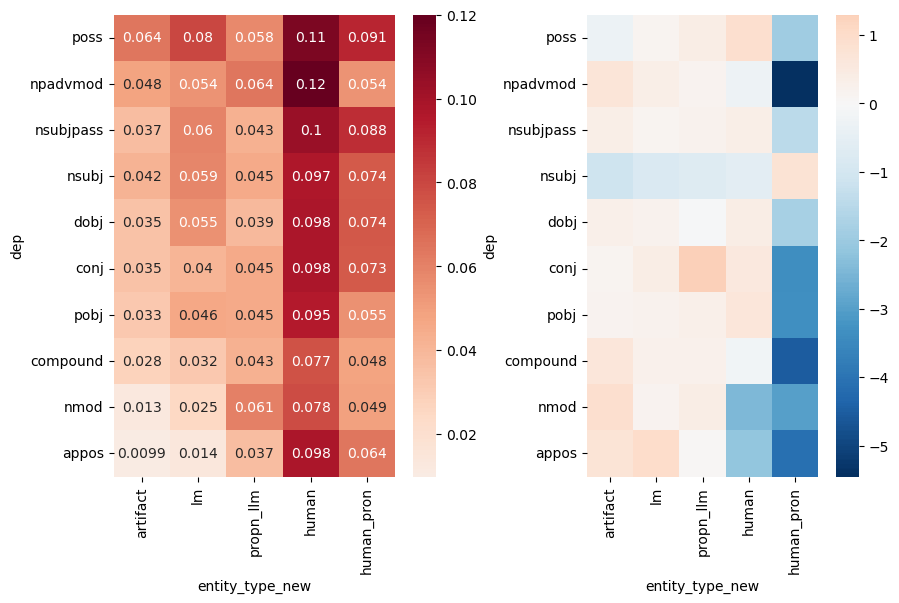

In [202]:
# Show mean scores (note though that only positives are used)

dep_means = (df_dedupl_humlike[df_dedupl_humlike["dep"].isin(humlike_top_dep)]
                .groupby(["dep", "entity_type_new"], observed=True)
                ["score"].mean()
                .unstack())
dep_order = dep_means.mean(axis=1).sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
sns.heatmap(dep_means.loc[dep_order, et_order + ["human_pron"]], annot=True, center=0, cmap="RdBu_r", ax=axes[0])
sns.heatmap(standardize(dep_ent_freq.loc[dep_order, et_order + ["human_pron"]]), square=True, center=0, cmap="RdBu_r", ax=axes[1])

<Axes: xlabel='entity_type_new', ylabel='dep'>

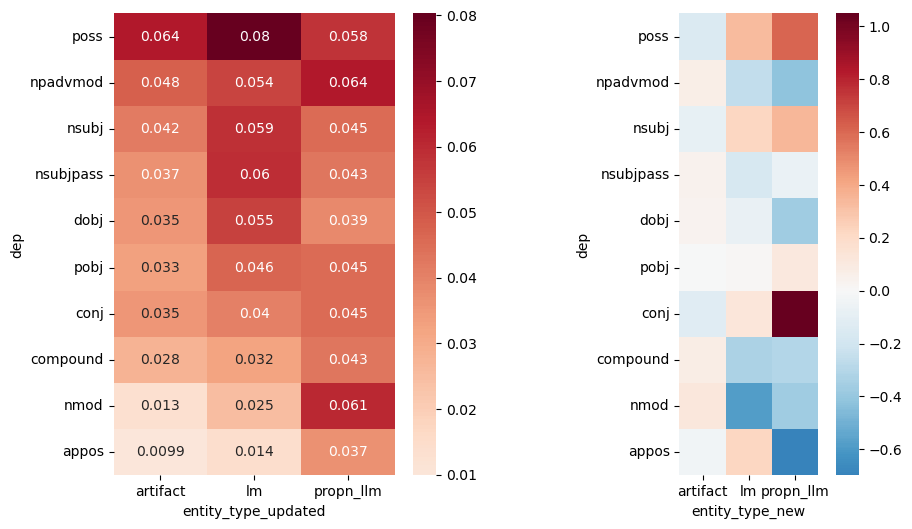

In [203]:
# Same but without human terms

dep_means = (df_dedupl_humlike[df_dedupl_humlike["dep"].isin(humlike_top_dep)]
                .groupby(["dep", "entity_type_updated"], observed=True)
                ["score"].mean()
                .unstack().drop(columns=("human")))
dep_order = dep_means.mean(axis=1).sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
sns.heatmap(dep_means.loc[dep_order, et_order[:-1]], annot=True, center=0, cmap="RdBu_r", ax=axes[0])
sns.heatmap(standardize(dep_ent_freq.drop(columns="human").loc[dep_order, et_order[:-1]]), square=True, center=0, cmap="RdBu_r", ax=axes[1])

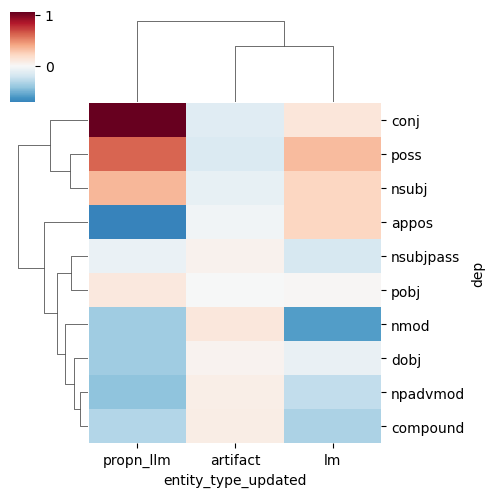

In [94]:
sns.clustermap(standardize(dep_ent_freq.drop(columns="human").loc[dep_order, et_order[:-1]]), center=0, cmap="RdBu_r", figsize=(5,5))

<Axes: xlabel='entity_type_new', ylabel='dep'>

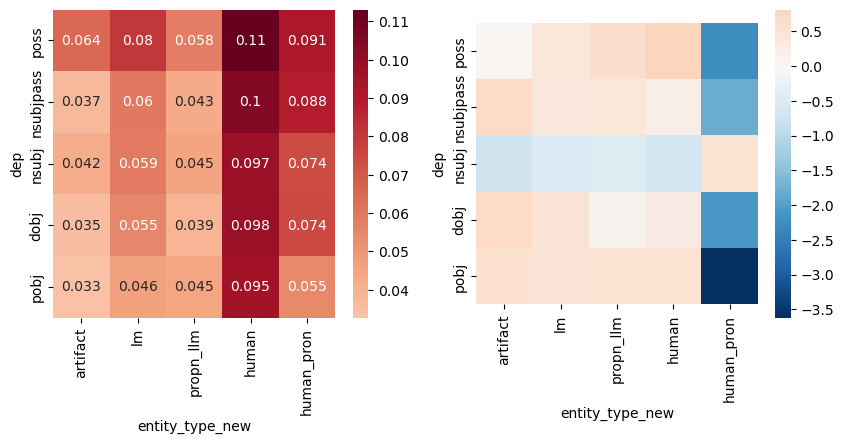

In [204]:
# Use a smaller set of deps

dep_means = (df_dedupl_humlike[df_dedupl_humlike["dep"].isin(top_dep)]
                .groupby(["dep", "entity_type_new"], observed=True)
                ["score"].mean()
                .unstack())
dep_order = dep_means.mean(axis=1).sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(dep_means.loc[dep_order, et_order + ["human_pron"]], annot=True, center=0, cmap="RdBu_r", ax=axes[0])
sns.heatmap(standardize(dep_ent_freq.loc[dep_order, et_order + ["human_pron"]]), square=True, center=0, cmap="RdBu_r", ax=axes[1])

<Axes: xlabel='entity_type_updated', ylabel='dep'>

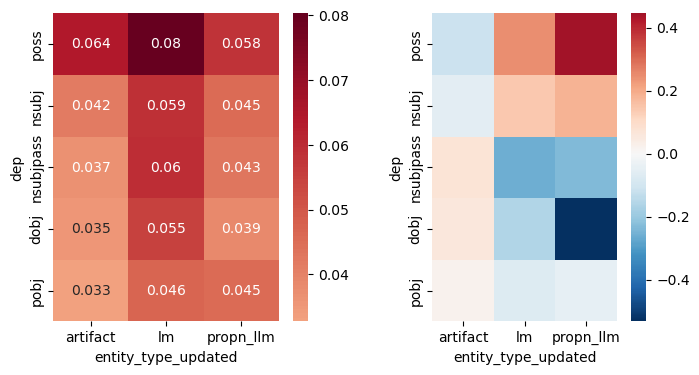

In [101]:
# Same but without human terms

dep_means = (df_dedupl_humlike[df_dedupl_humlike["dep"].isin(top_dep)]
                .groupby(["dep", "entity_type_updated"], observed=True)
                ["score"].mean()
                .unstack().drop(columns=("human")))
dep_order = dep_means.mean(axis=1).sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
sns.heatmap(dep_means.loc[dep_order, et_order[:-1]], annot=True, center=0, cmap="RdBu_r", ax=axes[0])
sns.heatmap(standardize(dep_ent_freq.drop(columns="human").loc[dep_order, et_order[:-1]]), square=True, center=0, cmap="RdBu_r", ax=axes[1])

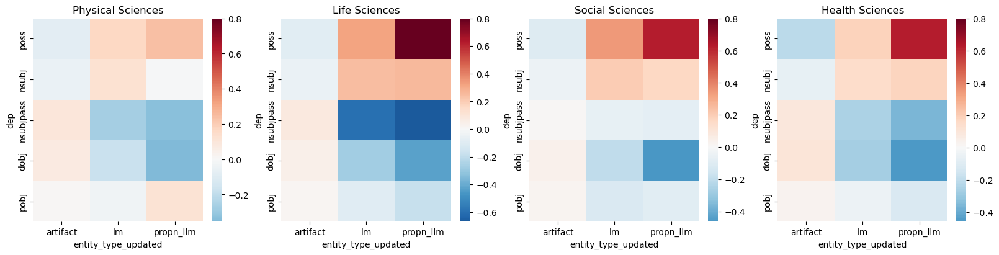

In [113]:
# See if there are differences between domains

fig, axes = plt.subplots(1, len(domain_order), figsize=(16, 4), layout="constrained")
for i, domain in enumerate(domain_order):
    dep_ent_freq_dom = (df_dedupl_humlike[(df_dedupl_humlike["dep"].isin(humlike_top_dep)) & (df_dedupl_humlike["domain"] == domain)]
        .value_counts(["dep", "entity_type_updated"]).unstack())
    axes[i].set_title(domain)
    sns.heatmap(standardize(dep_ent_freq_dom.loc[dep_order, et_order[:-1]]), ax=axes[i], center=0, cmap="RdBu_r", vmax=0.8)

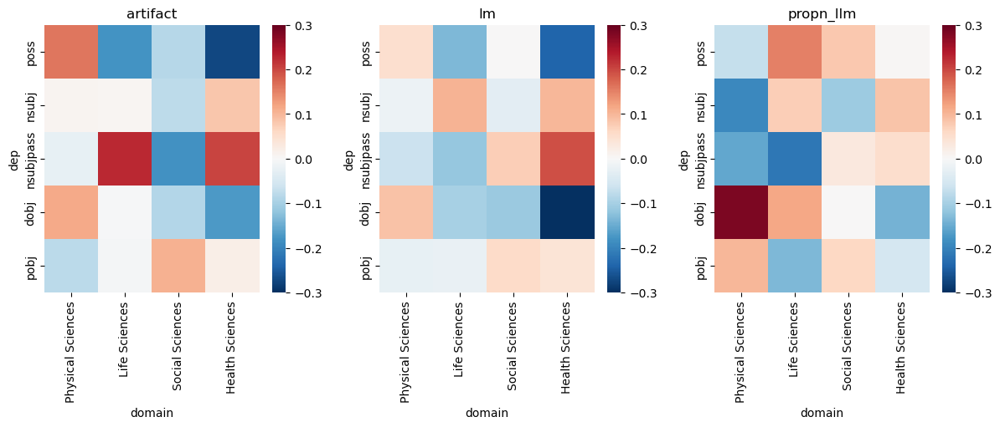

In [132]:
# Or maybe domain differences are clearer with entity_type grouping

fig, axes = plt.subplots(1, len(et_order[:-1]), figsize=(12, 5), layout="constrained")
for i, et in enumerate(et_order[:-1]):
    dep_dom_freq_ent = (df_dedupl_humlike[(df_dedupl_humlike["dep"].isin(top_dep)) & (df_dedupl_humlike["entity_type_updated"] == et)]
        .value_counts(["dep", "domain"]).unstack())
    axes[i].set_title(et)
    sns.heatmap(standardize(dep_dom_freq_ent.loc[dep_order, domain_order]),
                square=True, ax=axes[i], center=0, cmap="RdBu_r", vmax=0.3, vmin=-0.3) # vmax=0.8, vmin=-0.8 # with human terms

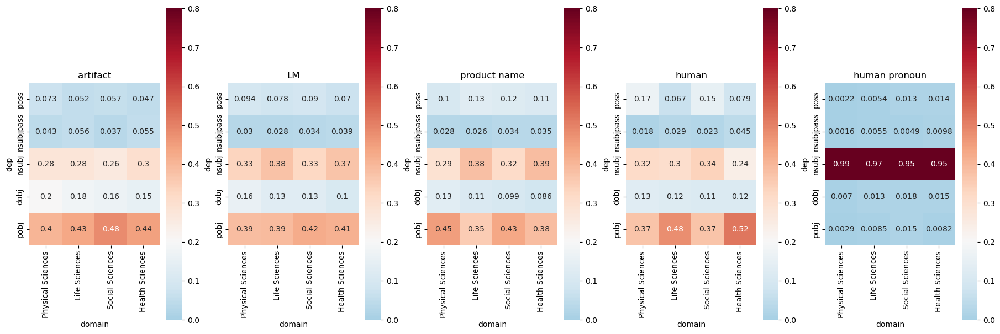

In [209]:
# Try to show percentages per domain, i.e. how often is each dep used within domain proportionally

fig, axes = plt.subplots(1, len(et_order)+1, figsize=(18, 6), layout="constrained")
for i, et in enumerate(et_order + ["human_pron"]):
    subset = df_dedupl_humlike[(df_dedupl_humlike["dep"].isin(top_dep)) & (df_dedupl_humlike["entity_type_new"] == et)].copy()
    subset["dep"] = subset["dep"].cat.remove_unused_categories()
    dep_dom_freq_ent = pd.crosstab(subset["dep"], subset["domain"], normalize="columns")
    axes[i].set_title(legend_map[et])
    sns.heatmap(dep_dom_freq_ent.loc[dep_order, domain_order],
                square=True, ax=axes[i], cmap="RdBu_r", center=0.2, annot=True, vmin=0, vmax=0.8)

The above heatmap shows certain differences between entities and domains. Largely, the domains have the same patterns: non-human terms most often take the positions of pobj and nsubj, whereas human pronoun almost exclusively are nsubjs. Other human terms, on the other hand, more often take similar positions to non-human terms -- pobj is more common than nsubj, with some differences appearing between domains. When it comes to artifact terms, Social Sciences uses pobj a bit more often than other domains. In the case of LM terms, all domains in general, but Life and Health Sciences in particular, use nsubj more often than in the case of artifact terms. Also possessive forms are increasing, whereas nsubjpass and dobj are getting less utilized. Maybe somewhat surprisingly, product name terms are proportionately less often used as nsubjs, which one could assume to be an animacy marker. Instead, possessive forms are used more.

In [212]:
df_dedupl[df_dedupl["entity_type_new"] == "human_pron"]["entity_lower"].value_counts()[lambda x: x > 0]

entity_lower
we     333836
i       16561
us       9075
he       5671
her      2494
she      2486
him       572
Name: count, dtype: int64

In [214]:
df_dedupl[df_dedupl["entity_type_new"] == "human"]["entity_lower"].value_counts()[lambda x: x > 0]

entity_lower
students         51618
patients         47953
user             40147
users            27298
researchers      20046
people           19950
participants     18091
humans           14520
teachers         13450
organizations    13418
authors          12418
companies        10955
author            8073
Name: count, dtype: int64

In [216]:
# What if the dependencies of negative and positive scores were compared instead?

df_dedupl_neg = df_dedupl[~df_dedupl["humanlike"]].copy()

In [147]:
# Frequency of dep x entity type
dep_ent_freq_neg = df_dedupl_neg[df_dedupl_neg["dep"].isin(top_dep)].value_counts(["dep", "entity_type_updated"]).unstack()

Text(0.5, 1.0, 'Dependencies with negative scores')

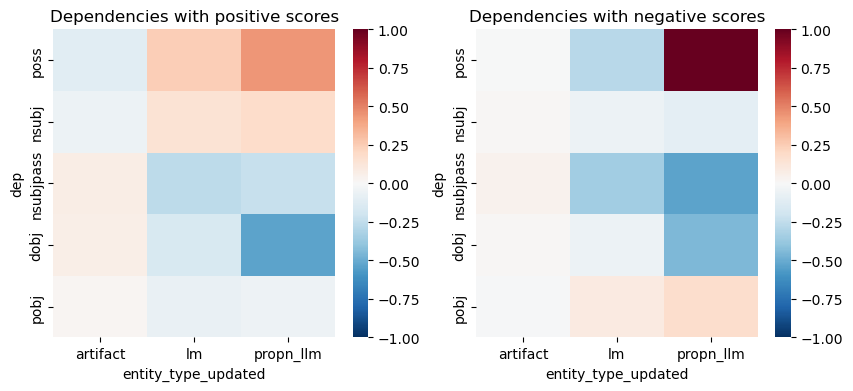

In [157]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(standardize(dep_ent_freq.drop(columns="human").loc[dep_order, et_order[:-1]]), center=0, cmap="RdBu_r", ax=axes[0], vmin=-1, vmax=1)
sns.heatmap(standardize(dep_ent_freq_neg.drop(columns="human").loc[dep_order, et_order[:-1]]), center=0, cmap="RdBu_r", ax=axes[1], vmin=-1, vmax=1)

axes[0].set_title("Dependencies with positive scores")
axes[1].set_title("Dependencies with negative scores")

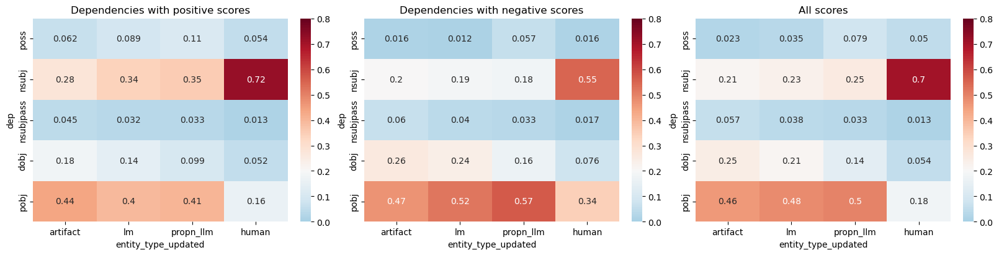

In [170]:
# Compare the proportions between positive, negative, and all scores
fig, axes = plt.subplots(1, 3, figsize=(16, 4), layout="constrained")

sub_pos = df_dedupl_humlike[df_dedupl_humlike["dep"].isin(top_dep)].copy()
sub_pos["dep"] = sub_pos["dep"].cat.remove_unused_categories()
sns.heatmap(
    pd.crosstab(sub_pos["dep"], sub_pos["entity_type_updated"], dropna=True, normalize="columns").loc[dep_order, et_order],
    ax=axes[0], cmap="RdBu_r", center=0.2, annot=True, vmin=0, vmax=0.8)

sub_neg = df_dedupl_neg[df_dedupl_neg["dep"].isin(top_dep)].copy()
sub_neg["dep"] = sub_neg["dep"].cat.remove_unused_categories()
sns.heatmap(
    pd.crosstab(sub_neg["dep"], sub_neg["entity_type_updated"], normalize="columns").loc[dep_order, et_order],
    ax=axes[1], cmap="RdBu_r", center=0.2, annot=True, vmin=0, vmax=0.8)

sub_all = df_dedupl[df_dedupl["dep"].isin(top_dep)].copy()
sub_all["dep"] = sub_all["dep"].cat.remove_unused_categories()
sns.heatmap(
    pd.crosstab(sub_all["dep"], sub_all["entity_type_updated"], normalize="columns").loc[dep_order, et_order],
    ax=axes[2], cmap="RdBu_r", center=0.2, annot=True, vmin=0, vmax=0.8)

axes[0].set_title("Dependencies with positive scores")
axes[1].set_title("Dependencies with negative scores")
axes[2].set_title("All scores")
plt.show()

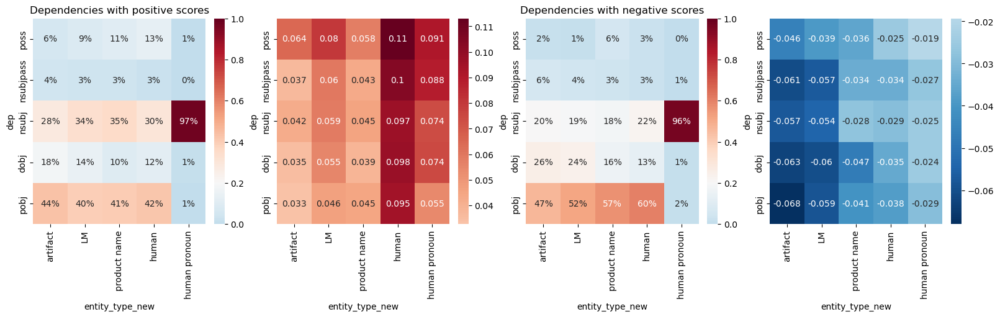

In [240]:
# Compare the proportions between positive, negative, and all scores
new_et_order = et_order + ["human_pron"]
fig, axes = plt.subplots(1, 4, figsize=(16, 5), layout="constrained")

sub_pos = df_dedupl_humlike[df_dedupl_humlike["dep"].isin(top_dep)].copy()
sub_pos["dep"] = sub_pos["dep"].cat.remove_unused_categories()
sns.heatmap(
    pd.crosstab(sub_pos["dep"], sub_pos["entity_type_new"], normalize="columns").loc[dep_order, new_et_order],
    ax=axes[0], cmap="RdBu_r", center=0.2, annot=True, vmin=0, vmax=1, fmt=".0%")
sns.heatmap(
    sub_pos.groupby(["dep", "entity_type_new"], observed=True)["score"].mean().unstack().loc[dep_order, new_et_order],
    ax=axes[1], cmap="RdBu_r", center=0, annot=True)

sub_neg = df_dedupl_neg[df_dedupl_neg["dep"].isin(top_dep)].copy()
sub_neg["dep"] = sub_neg["dep"].cat.remove_unused_categories()
sns.heatmap(
    pd.crosstab(sub_neg["dep"], sub_neg["entity_type_new"], normalize="columns").loc[dep_order, new_et_order],
    ax=axes[2], cmap="RdBu_r", center=0.2, annot=True, vmin=0, vmax=1, fmt=".0%")
sns.heatmap(
    sub_neg.groupby(["dep", "entity_type_new"], observed=True)["score"].mean().unstack().loc[dep_order, new_et_order],
    ax=axes[3], cmap="RdBu_r", center=0, annot=True)

axes[0].set_title("Dependencies with positive scores")
axes[2].set_title("Dependencies with negative scores")

for i in range(4):
    axes[i].set_xticklabels([legend_map[l] for l in new_et_order])
plt.show()

In [172]:
df_dedupl["humanlike"].mean()

0.3652735599004617

In [189]:
df_dedupl.groupby("entity_type_new", observed=True)["humanlike"].mean().sort_values()

entity_type_new
artifact      0.194360
lm            0.317029
propn_llm     0.448185
human         0.830837
human_pron    0.923552
Name: humanlike, dtype: float64

In [241]:
df_dedupl_humlike.groupby("entity_type_new", observed=True)["score"].mean().sort_values()

entity_type_new
artifact      0.030898
lm            0.042415
propn_llm     0.046030
human_pron    0.073755
human         0.097112
Name: score, dtype: float64

In [242]:
df_dedupl_neg.groupby("entity_type_new", observed=True)["score"].mean().sort_values()

entity_type_new
artifact     -0.060470
lm           -0.050513
propn_llm    -0.036644
human        -0.035467
human_pron   -0.024530
Name: score, dtype: float64

### All scores

Investigate the linguistic features from all scores.

In [34]:
df_dedupl.columns

Index(['id', 'year', 'domain', 'sent_id', 'match_id', 'sentence',
       'masked_sentence_minimal', 'masked_sentence_chunk', 'entity',
       'entity_lower', 'in_noun_chunk', 'chunk_text', 'chunk_root_text',
       'chunk_root_dep', 'score', 'token_i', 'token_text', 'pos', 'tag', 'dep',
       'ent_type', 'ent_iob', 'head', 'entity_type', 'num_tokens',
       'is_propn_llm', 'entity_type_updated', 'humanlike', 'entity_stripped'],
      dtype='object')

In [39]:
# What are the dependency value counts when only the entities that are the root of the noun chunk are considered?
df_dedupl[df_dedupl["chunk_root_text"] == df_dedupl["entity_lower"]]["dep"].value_counts()[lambda x: x > 0]

dep
pobj         509212
nsubj        467667
dobj         282554
conj          98659
nsubjpass     62630
appos         36132
attr          13621
ROOT           2972
dative         1441
oprd            627
nmod            107
compound         71
pcomp            21
npadvmod         20
amod             11
poss              3
dep               1
Name: count, dtype: int64

In [38]:
# How many of the matched entites are compounds?
len(df_dedupl[df_dedupl["dep"] == "compound"]) / len(df_dedupl)

0.13974269832109254

In [15]:
df_dedupl["dep"].value_counts()

dep
pobj         761102
nsubj        729578
compound     413816
dobj         368395
conj         157772
appos        145533
npadvmod     112250
nsubjpass     84017
nmod          67174
poss          66489
amod          18774
attr          15631
ROOT           8144
dative         1546
oprd           1412
dep            1408
advcl          1399
xcomp          1274
ccomp          1241
relcl          1086
advmod          607
punct           553
meta            536
acl             525
nummod          294
pcomp           187
parataxis       180
det              90
acomp            77
prep             42
intj             35
preconj          34
aux              22
csubj            18
cc               10
quantmod          6
case              5
csubjpass         4
mark              3
predet            1
auxpass           1
Name: count, dtype: int64

In [62]:
top_dep = ("nsubj", "nsubjpass", "dobj", "pobj", "poss") #("nsubj", "nsubjpass", "dobj", "pobj", "appos", "poss", "npadvmod", "nmod", "amod", "compound")
dep_entity = df_dedupl[df_dedupl["dep"].isin(top_dep)].groupby(["dep", "entity_type_updated"], observed=True)["score"].mean().unstack()
dep_entity.style.background_gradient(axis=None, cmap="RdBu_r")

entity_type_updated,artifact,human,lm,propn_llm
dep,,,,
dobj,-0.051612,0.075897,-0.037351,-0.020662
nsubj,-0.037292,0.069012,-0.005940,0.015440
nsubjpass,-0.048914,0.082749,-0.028058,-0.001433
pobj,-0.053270,0.067685,-0.033206,-0.010922
poss,-0.000263,0.106919,0.050464,0.018972


Domain-wise comparison of how often each entity type takes each dependency or POS.

In [63]:
df_dedupl[df_dedupl["dep"].isin(top_dep)].groupby(["domain", "dep"], observed=True)["score"].mean().unstack().style.background_gradient(axis=None, cmap="RdBu_r")

dep,dobj,nsubj,nsubjpass,pobj,poss
domain,,,,,
Health Sciences,-0.024448,0.030779,-0.012706,-0.004074,0.056058
Life Sciences,-0.040710,0.028118,-0.034414,-0.031538,0.034318
Physical Sciences,-0.043063,0.023976,-0.044545,-0.044406,0.049869
Social Sciences,-0.034812,0.032773,-0.028104,-0.027410,0.062409


In [65]:
pd.crosstab(df_dedupl[df_dedupl["dep"].isin(top_dep)]["domain"], df_dedupl[df_dedupl["dep"].isin(top_dep)]["dep"], normalize="index").style.background_gradient(axis=None, cmap="RdBu_r")

dep,dobj,nsubj,nsubjpass,pobj,poss
domain,,,,,
Health Sciences,0.166889,0.344462,0.052315,0.401519,0.034815
Life Sciences,0.185346,0.400797,0.046045,0.346392,0.021419
Physical Sciences,0.189445,0.371373,0.041033,0.367456,0.030693
Social Sciences,0.179184,0.345510,0.035173,0.399229,0.040904


In [243]:
for name, group in df_dedupl[(df_dedupl["dep"].isin(top_dep))].groupby(["domain"], observed=True): #  & (df_dedupl["entity_type_updated"] != "human")
    print(name[0])
    print("Proportion")
    display(pd.crosstab(group["entity_type_new"], group["dep"], normalize="index").style.background_gradient(axis=None, cmap="RdBu_r"))
    print("Mean score")
    display(group.groupby(["entity_type_new", "dep"], observed=True)["score"].mean().unstack().style.background_gradient(axis=None, cmap="RdBu_r"))
    print()

Health Sciences
Proportion


dep,dobj,nsubj,nsubjpass,pobj,poss
entity_type_new,,,,,
artifact,0.227406,0.236706,0.066772,0.445620,0.023495
human,0.118991,0.229438,0.046022,0.534301,0.071247
lm,0.165217,0.284930,0.051756,0.464282,0.033815
propn_llm,0.126809,0.294481,0.037665,0.458518,0.082527
human_pron,0.014840,0.952114,0.010462,0.008607,0.013978


Mean score


dep,dobj,nsubj,nsubjpass,pobj,poss
entity_type_new,,,,,
artifact,-0.046016,-0.026715,-0.040438,-0.040486,0.000220
human,0.083359,0.094686,0.085802,0.083799,0.113594
lm,-0.033655,-0.000139,-0.025280,-0.021022,0.048221
propn_llm,-0.018879,0.017925,-0.000026,-0.005804,0.020400
human_pron,0.070092,0.068874,0.075620,0.051313,0.079466



Life Sciences
Proportion


dep,dobj,nsubj,nsubjpass,pobj,poss
entity_type_new,,,,,
artifact,0.254214,0.230359,0.063808,0.431656,0.019963
human,0.118818,0.287914,0.030380,0.502375,0.060514
lm,0.234447,0.249004,0.039687,0.450506,0.026356
propn_llm,0.130120,0.279518,0.033735,0.472289,0.084337
human_pron,0.013098,0.966518,0.005587,0.009550,0.005247


... (6 outputs left out)


Social Sciences
Proportion


dep,dobj,nsubj,nsubjpass,pobj,poss
entity_type_new,,,,,
artifact,0.238974,0.197714,0.046432,0.491740,0.025139
human,0.111919,0.328934,0.021763,0.407703,0.129681
lm,0.202693,0.235486,0.041226,0.481287,0.039308
propn_llm,0.136570,0.205388,0.028541,0.550013,0.079488
human_pron,0.018786,0.947165,0.005003,0.016424,0.012622


Mean score


dep,dobj,nsubj,nsubjpass,pobj,poss
entity_type_new,,,,,
artifact,-0.050147,-0.030734,-0.045760,-0.047093,0.002544
human,0.071969,0.073656,0.082961,0.058545,0.106547
lm,-0.034483,0.001939,-0.021235,-0.024622,0.054503
propn_llm,-0.022926,0.016090,0.002673,-0.015416,0.024156
human_pron,0.065623,0.070574,0.079996,0.041436,0.086911


In [77]:
vmin = df_dedupl.groupby(["entity_type_updated", "dep"], observed=True)["score"].mean().min()
vmax = df_dedupl.groupby(["entity_type_updated", "dep"], observed=True)["score"].mean().max()
print(vmin, vmax)

-0.0863527599498016 0.1811913845550551


In [80]:
for name, group in df_dedupl[(df_dedupl["dep"].isin(top_dep))].groupby(["entity_type_updated"], observed=True): #  & (df_dedupl["entity_type_updated"] != "human")
    print(name[0])
    print("Proportion")
    display(pd.crosstab(group["domain"], group["dep"], normalize="index").loc[domain_order].style.background_gradient(axis=None, cmap="RdBu_r", vmin=0, vmax=1))
    print("Mean score")
    display(group.groupby(["domain", "dep"], observed=True)["score"].mean().unstack().loc[domain_order].style.background_gradient(axis=None, cmap="RdBu_r", vmin=vmin, vmax=vmax))
    print()

artifact
Proportion


dep,dobj,nsubj,nsubjpass,pobj,poss
domain,,,,,
Physical Sciences,0.251848,0.210378,0.058310,0.456432,0.023032
Life Sciences,0.254214,0.230359,0.063808,0.431656,0.019963
Social Sciences,0.238974,0.197714,0.046432,0.491740,0.025139
Health Sciences,0.227406,0.236706,0.066772,0.445620,0.023495


Mean score


dep,dobj,nsubj,nsubjpass,pobj,poss
domain,,,,,
Physical Sciences,-0.053448,-0.042652,-0.052725,-0.059380,-0.001062
Life Sciences,-0.051991,-0.039216,-0.046673,-0.051609,-0.006249
Social Sciences,-0.050147,-0.030734,-0.045760,-0.047093,0.002544
Health Sciences,-0.046016,-0.026715,-0.040438,-0.040486,0.000220



human
Proportion


dep,dobj,nsubj,nsubjpass,pobj,poss
domain,,,,,
Physical Sciences,0.043648,0.782160,0.006405,0.123078,0.044709
Life Sciences,0.046455,0.752403,0.013409,0.165048,0.022685
Social Sciences,0.064165,0.645935,0.013170,0.207073,0.069658
Health Sciences,0.075201,0.533284,0.031071,0.313275,0.047169


... (6 outputs left out)


propn_llm
Proportion


dep,dobj,nsubj,nsubjpass,pobj,poss
domain,,,,,
Physical Sciences,0.152314,0.199719,0.026928,0.548387,0.072651
Life Sciences,0.130120,0.279518,0.033735,0.472289,0.084337
Social Sciences,0.136570,0.205388,0.028541,0.550013,0.079488
Health Sciences,0.126809,0.294481,0.037665,0.458518,0.082527


Mean score


dep,dobj,nsubj,nsubjpass,pobj,poss
domain,,,,,
Physical Sciences,-0.022978,0.007950,-0.007216,-0.017035,0.011794
Life Sciences,-0.010174,0.016334,-0.005574,-0.006400,0.034746
Social Sciences,-0.022926,0.016090,0.002673,-0.015416,0.024156
Health Sciences,-0.018879,0.017925,-0.000026,-0.005804,0.020400


In [146]:
entity_order = ["artifact", "lm", "propn_llm", "human"]

<Axes: xlabel='dep'>

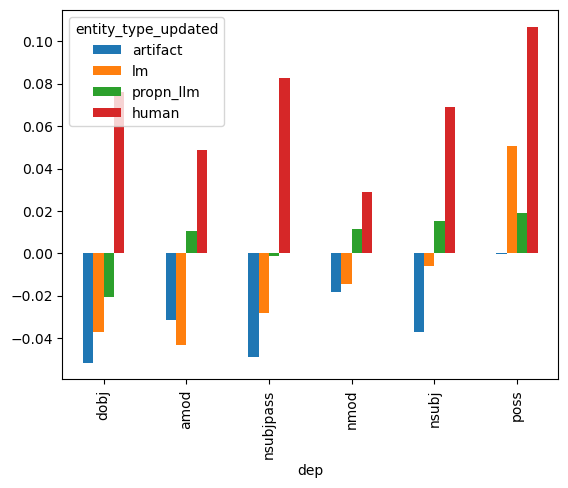

In [147]:
dep_entity.loc[dep_entity.mean(axis=1).sort_values().index.tolist()][entity_order].plot.bar()

In [65]:
df[df["dep"].isin(("nmod", "amod"))]["entity_lower"].value_counts().head(10)

entity_lower
artificial intelligence        157449
large language models           39918
ai                              30896
agent                            9559
large language model             7592
pre-trained language models      7173
model                            4169
llm                              3406
network                          2483
pre-trained language model       2196
Name: count, dtype: int64

In [87]:
df_dedupl.pos.value_counts()

pos
NOUN     1776089
PROPN     782035
PRON      370892
ADJ        17722
VERB       10934
NUM         2115
ADV          874
X            281
PUNCT        191
ADP           44
DET           35
AUX           25
SYM           12
INTJ          11
CCONJ          8
SCONJ          2
PART           1
Name: count, dtype: int64

In [88]:
top_pos = df_dedupl.pos.value_counts()[:4].index.tolist()

In [83]:
pos_entity = df[df["pos"].isin(top_pos)].groupby(["pos", "entity_type_updated"], observed=True)["score"].mean().unstack()
pos_entity

entity_type_updated,artifact,human,lm,propn_llm
pos,,,,
ADJ,-0.031779,0.045322,-0.042348,0.004098
NOUN,-0.051220,0.074905,-0.032157,-0.011203
PRON,-0.030706,0.066242,0.016167,-0.015932
PROPN,-0.025826,0.056556,-0.019943,0.005051


<Axes: xlabel='pos'>

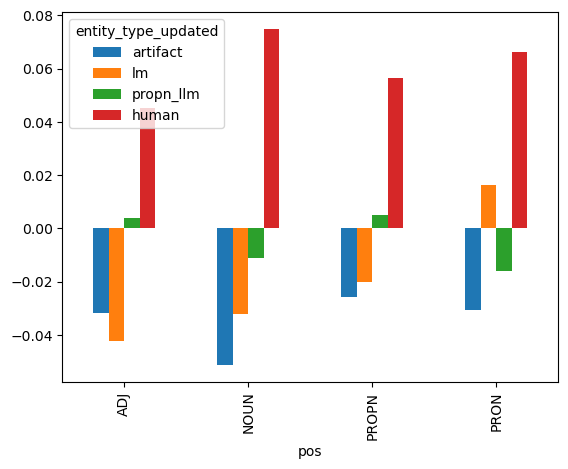

In [143]:
pos_entity.loc[pos_entity.mean(axis=1).sort_values().index.tolist()][entity_order].plot.bar()

In [84]:
df_dedupl[df_dedupl["pos"].isin(top_pos)].groupby(["domain", "pos"], observed=True)["score"].mean().unstack().style.background_gradient(axis=None, cmap="RdBu_r")

pos,ADJ,NOUN,PRON,PROPN
domain,,,,
Health Sciences,0.001561,-0.006131,0.068708,-0.014512
Life Sciences,-0.003110,-0.031828,0.066985,-0.023238
Physical Sciences,0.007997,-0.036536,0.064298,-0.027364
Social Sciences,0.011019,-0.020550,0.069987,-0.019555


In [91]:
df_dedupl[df_dedupl["pos"].isin(top_pos)].groupby(["domain", "entity_type_updated", "pos"], observed=True)["score"].mean().unstack().style.background_gradient(axis="index", cmap="RdBu_r")

In [111]:
for name, group in df_dedupl[df_dedupl["pos"].isin(("NOUN", "PROPN"))].groupby(["domain"], observed=True):
    print(name[0])
    print("Proportion")
    display(pd.crosstab(group["entity_type_updated"], group["pos"], normalize="index").style.background_gradient(axis=None, cmap="RdBu_r", vmin=0, vmax=1))
    print("Mean score")
    display(group.groupby(["entity_type_updated", "pos"], observed=True)["score"].mean().unstack().style.background_gradient(axis=None, cmap="RdBu_r", vmin=vmin, vmax=vmax))
    print()

Health Sciences
Proportion


pos,NOUN,PROPN
entity_type_updated,,
artifact,0.594296,0.405704
human,0.990779,0.009221
lm,0.525387,0.474613
propn_llm,0.301354,0.698646


Mean score


pos,NOUN,PROPN
entity_type_updated,,
artifact,-0.042904,-0.018987
human,0.087049,0.061901
lm,-0.023694,-0.003549
propn_llm,-0.007293,0.009520



Life Sciences
Proportion


pos,NOUN,PROPN
entity_type_updated,,
artifact,0.721424,0.278576
human,0.988986,0.011014
lm,0.559486,0.440514
propn_llm,0.173228,0.826772


... (6 outputs left out)


Social Sciences
Proportion


pos,NOUN,PROPN
entity_type_updated,,
artifact,0.597094,0.402906
human,0.989676,0.010324
lm,0.522247,0.477753
propn_llm,0.279403,0.720597


Mean score


pos,NOUN,PROPN
entity_type_updated,,
artifact,-0.048371,-0.021637
human,0.069776,0.063770
lm,-0.020512,-0.009988
propn_llm,-0.013067,0.003014


In [128]:
propn_predictions = df_dedupl[(df_dedupl["entity_type_updated"] != "human") & (df_dedupl["pos"] == "PROPN")].groupby("domain", observed=True).value_counts(["entity_lower"], normalize=True)
propn_predictions[lambda x: x > 0.01].unstack().style.background_gradient(axis=None, cmap="RdBu_r")

entity_lower,ai,chatgpt,artificial intelligence,algorithm,gpt,llm,llms,gemini,genai,network,networks,transformer,system,model,large language models,bert
domain,,,,,,,,,,,,,,,,
Health Sciences,0.708273,0.075103,0.033017,0.032261,0.025142,0.022727,0.017443,0.011464,0.011296,nan,nan,nan,nan,nan,nan,nan
Life Sciences,0.683729,nan,0.044048,0.044234,0.018230,0.032399,0.025208,nan,nan,0.018150,0.013586,0.011994,0.010189,0.010083,nan,nan
Physical Sciences,0.539546,0.014793,0.047520,0.053024,0.022462,0.074257,0.064239,nan,0.011775,0.013615,0.010936,0.010639,nan,nan,0.028828,0.012480
Social Sciences,0.759729,0.014109,0.050247,0.015648,0.011149,0.026987,0.023191,nan,0.016166,nan,nan,nan,nan,nan,0.010312,nan


In [125]:
propn_predictions[lambda x: x > 0.01].unstack().columns

CategoricalIndex(['ai', 'chatgpt', 'artificial intelligence', 'algorithm',
                  'gpt', 'llm', 'llms', 'gemini', 'genai', 'network',
                  'networks', 'transformer', 'system', 'model',
                  'large language models', 'bert'],
                 categories=['agent', 'agents', 'ai', 'algorithm', ..., 'chatgpt', 'claude', 'gemini', 'llama'], ordered=False, dtype='category', name='entity_lower')

In [127]:
propn_predictions[lambda x: x == 0].unstack().columns

CategoricalIndex(['author', 'authors', 'companies', 'he', 'her', 'him',
                  'humans', 'i', 'organizations', 'participants', 'patients',
                  'people', 'pre-trained language model', 'researchers', 'she',
                  'students', 'teachers', 'us', 'user', 'users', 'we'],
                 categories=['agent', 'agents', 'ai', 'algorithm', ..., 'chatgpt', 'claude', 'gemini', 'llama'], ordered=False, dtype='category', name='entity_lower')

In [99]:
propn_slice = df_dedupl[(df_dedupl["entity_type_updated"] == "propn_llm") & (df_dedupl["pos"] == "PROPN")].copy()
propn_slice.groupby(["domain", "entity_lower"], observed=True)["score"].mean().unstack().style.background_gradient(axis=None, cmap="RdBu_r")

entity_lower,chatgpt,claude,gemini
domain,,,
Health Sciences,0.007840,0.030345,0.010147
Life Sciences,0.008816,0.020521,0.001185
Physical Sciences,-0.003805,0.013994,-0.003951
Social Sciences,0.000165,0.021785,-0.001900


In [100]:
propn_slice.groupby(["domain", "entity_lower"], observed=True)["humanlike"].mean().unstack().style.background_gradient(axis=None, cmap="RdBu_r")

entity_lower,chatgpt,claude,gemini
domain,,,
Health Sciences,0.536119,0.645809,0.470865
Life Sciences,0.543716,0.634146,0.424390
Physical Sciences,0.415098,0.496800,0.345553
Social Sciences,0.451327,0.554745,0.369540


In [110]:
propn_slice.groupby("domain", observed=True).value_counts(["entity_lower"], normalize=True)[lambda x: x > 0].unstack()

entity_lower,chatgpt,gemini,claude
domain,,,
Health Sciences,0.813834,0.124232,0.061933
Life Sciences,0.497959,0.278912,0.223129
Physical Sciences,0.642364,0.213660,0.143976
Social Sciences,0.665721,0.184813,0.149465


In [108]:
for row in df[(df["pos"] == "VERB")].sample(10).itertuples():
    print(f"[{row.entity}] [{row.score:.3f}] {row.masked_sentence_minimal}")

[algorithms] [-0.075] It is based on an algorithm known as kill chain interior point (KCIP), which is the result of a merger of kill chain and interior point [MASK], as well as a precise and accurate analytical model of brain tumors.
[algorithms] [-0.106] While several early warning systems use remotely sensed images collected by optical and non-optical sensors, as well as supervised AI (Artificial Intelligence) [MASK] to detect fires early on, the development and dissemination of reliable, low-cost sensors together with the advancement of the IoT (Internet of Things) paradigm make it possible to apply monitoring techniques relying on widespread ground-based sensor networks.
[models] [-0.021] We develop a multi-agent framework that [MASK] supply chain system-of-systems dynamics drawing on (1) supply chain decision functions (shipment planning, sourcing and vendor management), (2) national energy-transition conditions that determine grid carbon intensity, and (3) carbon-aware computatio

In [148]:
top_ent = df_dedupl.ent_type.value_counts()[:5].index.tolist()

In [149]:
ent_entity = df[df["ent_type"].isin(top_ent)].groupby(["ent_type", "entity_type_updated"], observed=True)["score"].mean().unstack()
ent_entity

entity_type_updated,artifact,human,lm,propn_llm
ent_type,,,,
GPE,-0.028275,0.110837,-0.017936,0.004800
ORG,-0.025652,0.051405,-0.030044,0.009333
PERSON,-0.024938,0.053443,0.009495,0.018635
PRODUCT,-0.031665,0.090082,-0.028793,0.011741
WORK_OF_ART,-0.032407,0.066664,-0.052522,0.041358


In [150]:
df[df["ent_type"].isin(top_ent)].groupby(["ent_type", "entity_type_updated"], observed=True).size().unstack()

entity_type_updated,artifact,human,lm,propn_llm
ent_type,,,,
GPE,5861,171,7634,2190
ORG,500087,1330,68065,2882
PERSON,7023,132,10088,2970
PRODUCT,1030,22,3004,860
WORK_OF_ART,3381,310,12517,117


<Axes: xlabel='ent_type'>

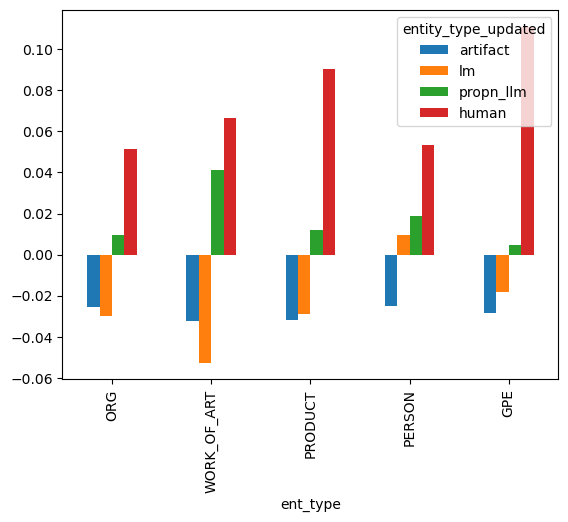

In [151]:
ent_entity.loc[ent_entity.mean(axis=1).sort_values().index.tolist()][entity_order].plot.bar()

In [124]:
human_average = df_dedupl[df_dedupl["entity_type_updated"] == "human"]["score"].mean()

In [125]:
for row in df[(df["ent_type"] == "WORK_OF_ART") & (df["score"] > human_average)].sample(10).itertuples():
    print(f"[{row.entity}] [{row.score:.3f}] {row.masked_sentence_minimal}")

[Large Language Models] [0.134] Our benchmark serves as a valuable resource for evaluating the abilities of [MASK] to interpret medical codes and distinguish between medical concepts.
[Language Models] [0.106] Pretrained [MASK] (PLMs) are trained on large text data, understanding and generating human-like language patterns, and fine-tuning for specific NLP tasks.
[Language Models] [0.077] While Chain-of-Thought (CoT) prompting boosts [MASK]' (LM) performance on a gamut of complex reasoning tasks, the generated reasoning chain does not necessarily reflect how the model arrives at the answer (aka.
[Large Language Models] [0.085] A common challenge towards the adaptability of [MASK] (LLMs) is their ability to learn new languages over time without hampering the model's performance on languages in which the model is already proficient (usually English).
[Large Language Models] [0.136] Despite remarkable performance in legal consultation exhibited by legal [MASK](LLMs) combined with legal ar

In [93]:
df.columns

Index(['id', 'year', 'domain', 'sent_id', 'match_id', 'sentence',
       'masked_sentence_minimal', 'masked_sentence_chunk', 'entity',
       'entity_lower', 'in_noun_chunk', 'chunk_text', 'chunk_root_text',
       'chunk_root_dep', 'score', 'token_i', 'token_text', 'pos', 'tag', 'dep',
       'ent_type', 'ent_iob', 'head', 'entity_type', 'num_tokens',
       'is_propn_llm', 'entity_type_updated'],
      dtype='object')

In [126]:
df_dedupl["human_like"] = df_dedupl["score"] > 0

In [129]:
df_dedupl.groupby("entity_type_updated", observed=True)["human_like"].value_counts(normalize="index").unstack("entity_type_updated")

entity_type_updated,artifact,human,lm,propn_llm
human_like,,,,
False,0.80564,0.117761,0.682971,0.551815
True,0.19436,0.882239,0.317029,0.448185


In [141]:
(df_dedupl[(df_dedupl["entity_type_updated"] == "propn_llm") & (df_dedupl["dep"].isin(top_dep))]
    .groupby("dep", observed=True))["head"].value_counts().sort_values(ascending=False).head(50)

dep        head       
dobj       use            1647
nsubj      be             1039
           have            357
           demonstrate     349
           provide         332
poss       of              282
nsubj      show            280
nsubjpass  use             231
nsubj      generate        202
           achieve         200
dobj       integrate       191
nsubj      perform         173
dobj       utilize         156
nsubj      offer           152
           outperform      142
dobj       outperform      133
nmod       of              132
nsubj      exhibit         128
poss       be              127
           evaluate        120
nsubj      produce          92
           enhance          91
           become           86
           serve            82
           emerge           80
poss       assess           78
dobj       ask              76
nmod       use              73
nsubj      score            72
nmod       model            66
poss       highlight        64
nmod       llm  

In [142]:
(df_dedupl[(df_dedupl["entity_type_updated"] == "human") & (df_dedupl["dep"].isin(top_dep))]
    .groupby("dep", observed=True))["head"].value_counts().sort_values(ascending=False).head(50)

dep    head       
nsubj  propose        35653
       introduce      19319
       present        17025
       use            11553
       find           11356
       show           10627
       be             10496
       develop        10239
       demonstrate     9261
       evaluate        8386
       conduct         7774
       explore         7204
       discuss         6686
       investigate     5900
       identify        5881
       provide         5833
       have            5573
       analyze         4690
       argue           4512
       examine         4504
       aim             3872
       apply           3608
       design          3517
       compare         3423
       focus           3283
poss   of              3275
nsubj  employ          3157
       observe         2921
       consider        2892
       study           2811
       conclude        2799
       describe        2684
dobj   enable          2674
nsubj  need            2605
       report          2579
 

In [143]:
(df_dedupl[(df_dedupl["entity_type_updated"] == "artifact") & (df_dedupl["dep"].isin(top_dep))]
    .groupby("dep", observed=True))["head"].value_counts().sort_values(ascending=False).head(50)

dep        head       
dobj       use            37630
nsubj      be             30229
dobj       propose        19613
           develop        15295
nmod       of             12139
dobj       present        10288
nsubjpass  use             9884
dobj       introduce       9737
nsubj      achieve         9569
           have            8868
dobj       integrate       8421
nsubj      provide         6632
dobj       train           6507
           provide         5598
           employ          5360
nsubj      demonstrate     5222
           offer           5093
dobj       build           4852
           leverage        4773
nsubjpass  develop         4709
dobj       utilize         4594
           outperform      4556
nsubj      improve         4533
           become          4495
           enhance         4474
dobj       create          4431
           apply           4430
           evaluate        4373
           implement       4229
nsubj      outperform      4110
           show  

In [152]:
# See how often each entity type is taking which syntactic position
for et in entity_order:
    print(et)
    subset = df_dedupl[(df_dedupl["entity_type_updated"] == et) & (df_dedupl["dep"].isin(top_dep)) & (df_dedupl["pos"].isin(top_pos))]
    #print(subset.groupby(["dep"], observed=True).size().sort_values())
    proportions = subset["dep"].value_counts(normalize=True)[lambda x: x > 0]
    scores = subset.groupby("dep", observed=True)["score"].mean()
    new = pd.DataFrame([proportions, scores])
    #print(subset["dep"].value_counts(normalize=True)[lambda x: x > 0])
    display(new)
    print()

artifact


dep,dobj,nsubj,nsubjpass,nmod,poss,amod
proportion,0.410117,0.355607,0.095571,0.078859,0.039188,0.020657
score,-0.051579,-0.037294,-0.048911,-0.018262,-0.000264,0.008511



lm


dep,nsubj,dobj,nmod,nsubjpass,poss,amod
proportion,0.407479,0.370114,0.071277,0.066434,0.061651,0.023045
score,-0.006069,-0.037608,-0.010433,-0.028099,0.050492,-0.013981



propn_llm


dep,nsubj,dobj,poss,nmod,nsubjpass,amod
proportion,0.444437,0.237678,0.139031,0.116806,0.058122,0.003926
score,0.015367,-0.020675,0.019067,0.011490,-0.001521,0.000683



human


dep,nsubj,dobj,poss,nsubjpass,nmod,amod
proportion,0.853559,0.066204,0.060461,0.015738,0.003570,0.000468
score,0.069012,0.075902,0.106919,0.082749,0.028892,0.044887


In [179]:
# Which heads have the highest and lowest scores? (Only look at the heads that appear often-ish)
top_heads = set((df_dedupl[df_dedupl["dep"].isin(("nsubj", "dobj"))]
    ["head"].value_counts()[lambda x: x > 10]).index)

In [181]:
for et in entity_order:
    heads = (df_dedupl[(df_dedupl["dep"].isin(("nsubj", "dobj"))) & (df_dedupl["head"].isin(top_heads)) & (df_dedupl["entity_type_updated"] == et)]
        .groupby(["entity_type_updated", "dep", "head"], observed=True)).agg(score=("score", "mean"), size=("id", "size")).sort_values("score", ascending=False)
    print("Highest scores")
    display(heads.head(30))

    print("Lowest scores")
    display(heads.tail(30))
    print()

Highest scores


score  size
entity_type_updated dep   head                       
artifact            nsubj hone         0.171374     1
                          opine        0.167347     1
                          criticize    0.148065     1
                    dobj  experienced  0.124029     1
                    nsubj debug        0.122978     1
                          rethink      0.122587     1
                          pause        0.119056     2
                          hand         0.103046     4
                    dobj  entice       0.102993     1
                    nsubj suspect      0.102359     1
                    dobj  remind       0.102288     2
                          surprise     0.101786     1
                    nsubj debate       0.101391     2
                    dobj  thank        0.097971     1
                    nsubj believe      0.097442    15
                          cite         0.093387     4
                          visit        0.092360     4
                    dobj  transport    0.091642     4
                    nsubj where        0.089633     1
                    dobj  persuade     0.086201     1
                    nsubj inquire      0.085506     3
                          speak        0.084845    13
                          zoom         0.082819     1
                          fear         0.082733     1
                          verbalize    0.082154     5
                          master       0.080079    14
                          talk         0.079145     8
                    dobj  educate      0.078878    11
                    nsubj choose       0.078442    64
                          guess        0.075411     6

Lowest scores


score  size
entity_type_updated dep   head                        
artifact            dobj  manufacture  -0.100492    13
                          conjecture   -0.101368     1
                          explode      -0.101849     1
                          assure       -0.102517     3
                          microservice -0.103370    14
                          modernise    -0.103663    11
                          import       -0.104423     9
                          reliable     -0.105378    10
                          install      -0.105435    14
                          mount        -0.105499     3
                          modernize    -0.107150   115
                          specialise   -0.109843     2
                    nsubj print        -0.110446     2
                    dobj  phishe       -0.110765    10
                    nsubj spur         -0.111096     7
                    dobj  title        -0.111843     3
                          accessible   -0.113094     1
                          flourish     -0.113239     2
                          message      -0.113472    32
                          blockchain   -0.114868   129
                    nsubj impart       -0.116272     1
                    dobj  system       -0.120836     1
                          recall       -0.121138     3
                    nsubj deprive      -0.125159     1
                    dobj  workflow     -0.128600     4
                    nsubj pressure     -0.133314     1
                    dobj  cool         -0.135104    39
                          interfere    -0.155366     1
                          contact      -0.155482     1
                          intervene    -0.197489     1


Highest scores


score  size
entity_type_updated dep   head                         
lm                  nsubj field          0.169792     1
                          issue          0.161949     2
                          remind         0.147961     1
                          interview      0.147199     2
                          speak          0.145130     2
                          exchange       0.144617     1
                          foresee        0.143201     1
                    dobj  order          0.139428     1
                    nsubj compensate     0.135366     1
                          pause          0.134556     1
                          converse       0.134119     3
                          pressure       0.132835     1
                    dobj  showcase       0.132661     1
                    nsubj contextualise  0.130219     1
                          resemble       0.127820     2
                          ask            0.127699    18
                    dobj  educate        0.127404     1
                          reward         0.127230     1
                    nsubj fast           0.127104     1
                          master         0.124430     6
                          sense          0.122229     2
                          regain         0.121839     1
                          specialise     0.121697     1
                          rectify        0.121185     1
                          respect        0.121133     1
                    dobj  entrust        0.119559     1
                    nsubj attend         0.118464     4
                          view           0.117572     2
                          talk           0.117102     2
                          trace          0.116837     1

... (6 outputs left out)


Highest scores


score  size
entity_type_updated dep   head                         
human               dobj  omit           0.234414     1
                          live           0.194089     1
                          crowdsource    0.191879     1
                    nsubj fool           0.180650     1
                    dobj  interpretable  0.179261     1
                          available      0.179021     1
                          infer          0.175689     2
                          instal         0.172721     1
                          transmit       0.171814     1
                          disabled       0.166802    13
                          spotlight      0.165599     1
                    nsubj intelligent    0.156284     1
                    dobj  abandon        0.154612     2
                          attain         0.154565     1
                          belong         0.154061     1
                          audit          0.153771     1
                    nsubj database       0.153293     1
                          disadvantage   0.152619     1
                          nudge          0.151949     1
                    dobj  end            0.150403   181
                    nsubj entertain      0.149711     4
                          training       0.147320     1
                    dobj  reside         0.146675     1
                          restore        0.145501     3
                          prohibit       0.145237     1
                    nsubj chat           0.143791    15
                          entail         0.140859     1
                          immerse        0.139681     8
                    dobj  technique      0.139376     1
                          streamline     0.139154     1

Lowest scores


score  size
entity_type_updated dep   head                         
human               dobj  probe         -0.061820     2
                          interconnect  -0.062230     3
                          orchestrate   -0.062520     2
                          blame         -0.063591     2
                    nsubj saturate      -0.063996     1
                    dobj  embed         -0.064898     1
                          export        -0.066759     1
                          =             -0.066760     1
                          co            -0.067726     1
                          balance       -0.068523     1
                          distort       -0.071563     1
                          impose        -0.072187     1
                          certify       -0.072207     1
                    nsubj valuable      -0.073068     1
                          adaptive      -0.074038     1
                    dobj  articulate    -0.074597     1
                          distill       -0.074926     2
                          disrupt       -0.075930     2
                          log           -0.076191     1
                          manifest      -0.076561     1
                          harmonize     -0.078698     1
                          fast          -0.078858     1
                          inspect       -0.081042     1
                          intertwine    -0.083224     1
                          traverse      -0.083983     1
                          launch        -0.097284     1
                          interact      -0.107167     1
                          conceptualize -0.109949     2
                          reason        -0.115117     1
                          underlie      -0.157575     1

In [ ]:
for domain in hue_order:
    heads = (df_dedupl[(df_dedupl["dep"].isin(("nsubj", "dobj"))) & (df_dedupl["head"].isin(top_heads)) & (df_dedupl["domain"] == domain)]
        .groupby(["entity_type_updated", "dep", "head"], observed=True)).agg(score=("score", "mean"), size=("id", "size")).sort_values("score", ascending=False)
    print("Highest scores")
    display(heads.head(30))

    print("Lowest scores")
    display(heads.tail(30))
    print()